# ME 228 
## Project: Remaining Useful Life (RUL) Prediction for Turbofan Engines

| Field | Details |
|---|---|
| **Roll Number** | 24B2215 |
| **Title of Project** | Remaining Useful Life (RUL) Prediction for Turbofan Engines Using Machine Learning |
| **Source of Data** | NASA C-MAPSS (Commercial Modular Aero-Propulsion System Simulation) Turbofan Engine Degradation Dataset - FD001 subset. Link: [https://data.nasa.gov/dataset/cmapss-jet-engine-simulated-data/resource/5224bcd1-ad61-490b-93b9-2817288accb8](https://data.nasa.gov/dataset/cmapss-jet-engine-simulated-data/resource/5224bcd1-ad61-490b-93b9-2817288accb8) |
| **Objective** | To develop predictive regression models that estimate the Remaining Useful Life (RUL) of turbofan jet engines from multivariate time-series sensor data using the NASA C-MAPSS FD001 benchmark. Multiple approaches are explored: from classical baselines (Linear Regression, Support Vector Regression, Random Forest, XGBoost) trained on raw and rolling-mean-smoothed sensor features, to a deep-learning two-layer LSTM that used temporal sequence information. A cost-sensitive LSTM variant is also trained with an asymmetric overprediction-penalising loss, motivated by the safety-critical consequence of underestimating engine degradation in maintenance scheduling. |

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.ensemble import RandomForestRegressor
import sklearn
from sklearn.metrics import mean_squared_error, r2_score
import os
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
import random
import warnings
np.random.seed(34)
warnings.filterwarnings('ignore')

In [3]:
index_names = ['unit_number', 'time_cycles']
setting_names = ['setting_1', 'setting_2', 'setting_3']
sensor_names = ['s_{}'.format(i+1) for i in range(0,21)]
col_names = index_names + setting_names + sensor_names

## 1. Data Loading

The NASA C-MAPSS FD001 dataset is read from local text files. It consists of:
- **train_FD001.txt** - 100 engines run to failure; 20,631 rows × 26 columns.
- **test_FD001.txt** - 100 engines truncated at an unknown degradation point (validation set feature matrix).
- **RUL_FD001.txt** - Ground-truth RUL values for the 100 test engines.

Each row contains unit_number, time_cycles, 3 operational setting columns, and 21 sensor measurement columns (s_1 through s_21).

In [4]:
dftrain = pd.read_csv('data/CMaps/train_FD001.txt',sep='\s+',header=None,index_col=False,names=col_names)
dfvalid = pd.read_csv('data/CMaps/test_FD001.txt',sep='\s+',header=None,index_col=False,names=col_names)
y_valid = pd.read_csv('data/CMaps/RUL_FD001.txt',sep='\s+',header=None,index_col=False,names=['RUL'])
dfvalid.shape

(13096, 26)

In [5]:
train = dftrain.copy()
valid = dfvalid.copy()

## 2. EDA - Dataframe Overview and Lifetime Distribution

The raw training dataframe is displayed to inspect shape, column types, and value ranges. A horizontal bar chart then shows the total operational lifetime (max time_cycles) of each engine unit, illustrating fleet-level variability. The "add_RUL_column" function computes the Remaining Useful Life target for every row:

**RUL = max\_time\_cycle(unit) − current\_time\_cycle**

In [6]:
train

,unit_number,time_cycles,setting_1,setting_2,setting_3,s_1,s_2,s_3,s_4,s_5,...,s_12,s_13,s_14,s_15,s_16,s_17,s_18,s_19,s_20,s_21
0,1,1,-0.0007,-0.0004,100.0,518.67,641.82,1589.70,1400.60,14.62,...,521.66,2388.02,8138.62,8.4195,0.03,392,2388,100.0,39.06,23.4190
1,1,2,0.0019,-0.0003,100.0,518.67,642.15,1591.82,1403.14,14.62,...,522.28,2388.07,8131.49,8.4318,0.03,392,2388,100.0,39.00,23.4236
2,1,3,-0.0043,0.0003,100.0,518.67,642.35,1587.99,1404.20,14.62,...,522.42,2388.03,8133.23,8.4178,0.03,390,2388,100.0,38.95,23.3442
3,1,4,0.0007,0.0000,100.0,518.67,642.35,1582.79,1401.87,14.62,...,522.86,2388.08,8133.83,8.3682,0.03,392,2388,100.0,38.88,23.3739
4,1,5,-0.0019,-0.0002,100.0,518.67,642.37,1582.85,1406.22,14.62,...,522.19,2388.04,8133.80,8.4294,0.03,393,2388,100.0,38.90,23.4044
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
20626,100,196,-0.0004,-0.0003,100.0,518.67,643.49,1597.98,1428.63,14.62,...,519.49,2388.26,8137.60,8.4956,0.03,397,2388,100.0,38.49,22.9735
20627,100,197,-0.0016,-0.0005,100.0,518.67,643.54,1604.50,1433.58,14.62,...,519.68,2388.22,8136.50,8.5139,0.03,395,2388,100.0,38.30,23.1594
20628,100,198,0.0004,0.0000,100.0,518.67,643.42,1602.46,1428.18,14.62,...,520.01,2388.24,8141.05,8.5646,0.03,398,2388,100.0,38.44,22.9333
20629,100,199,-0.0011,0.0003,100.0,518.67,643.23,1605.26,1426.53,14.62,...,519.67,2388.23,8139.29,8.5389,0.03,395,2388,100.0,38.29,23.0640


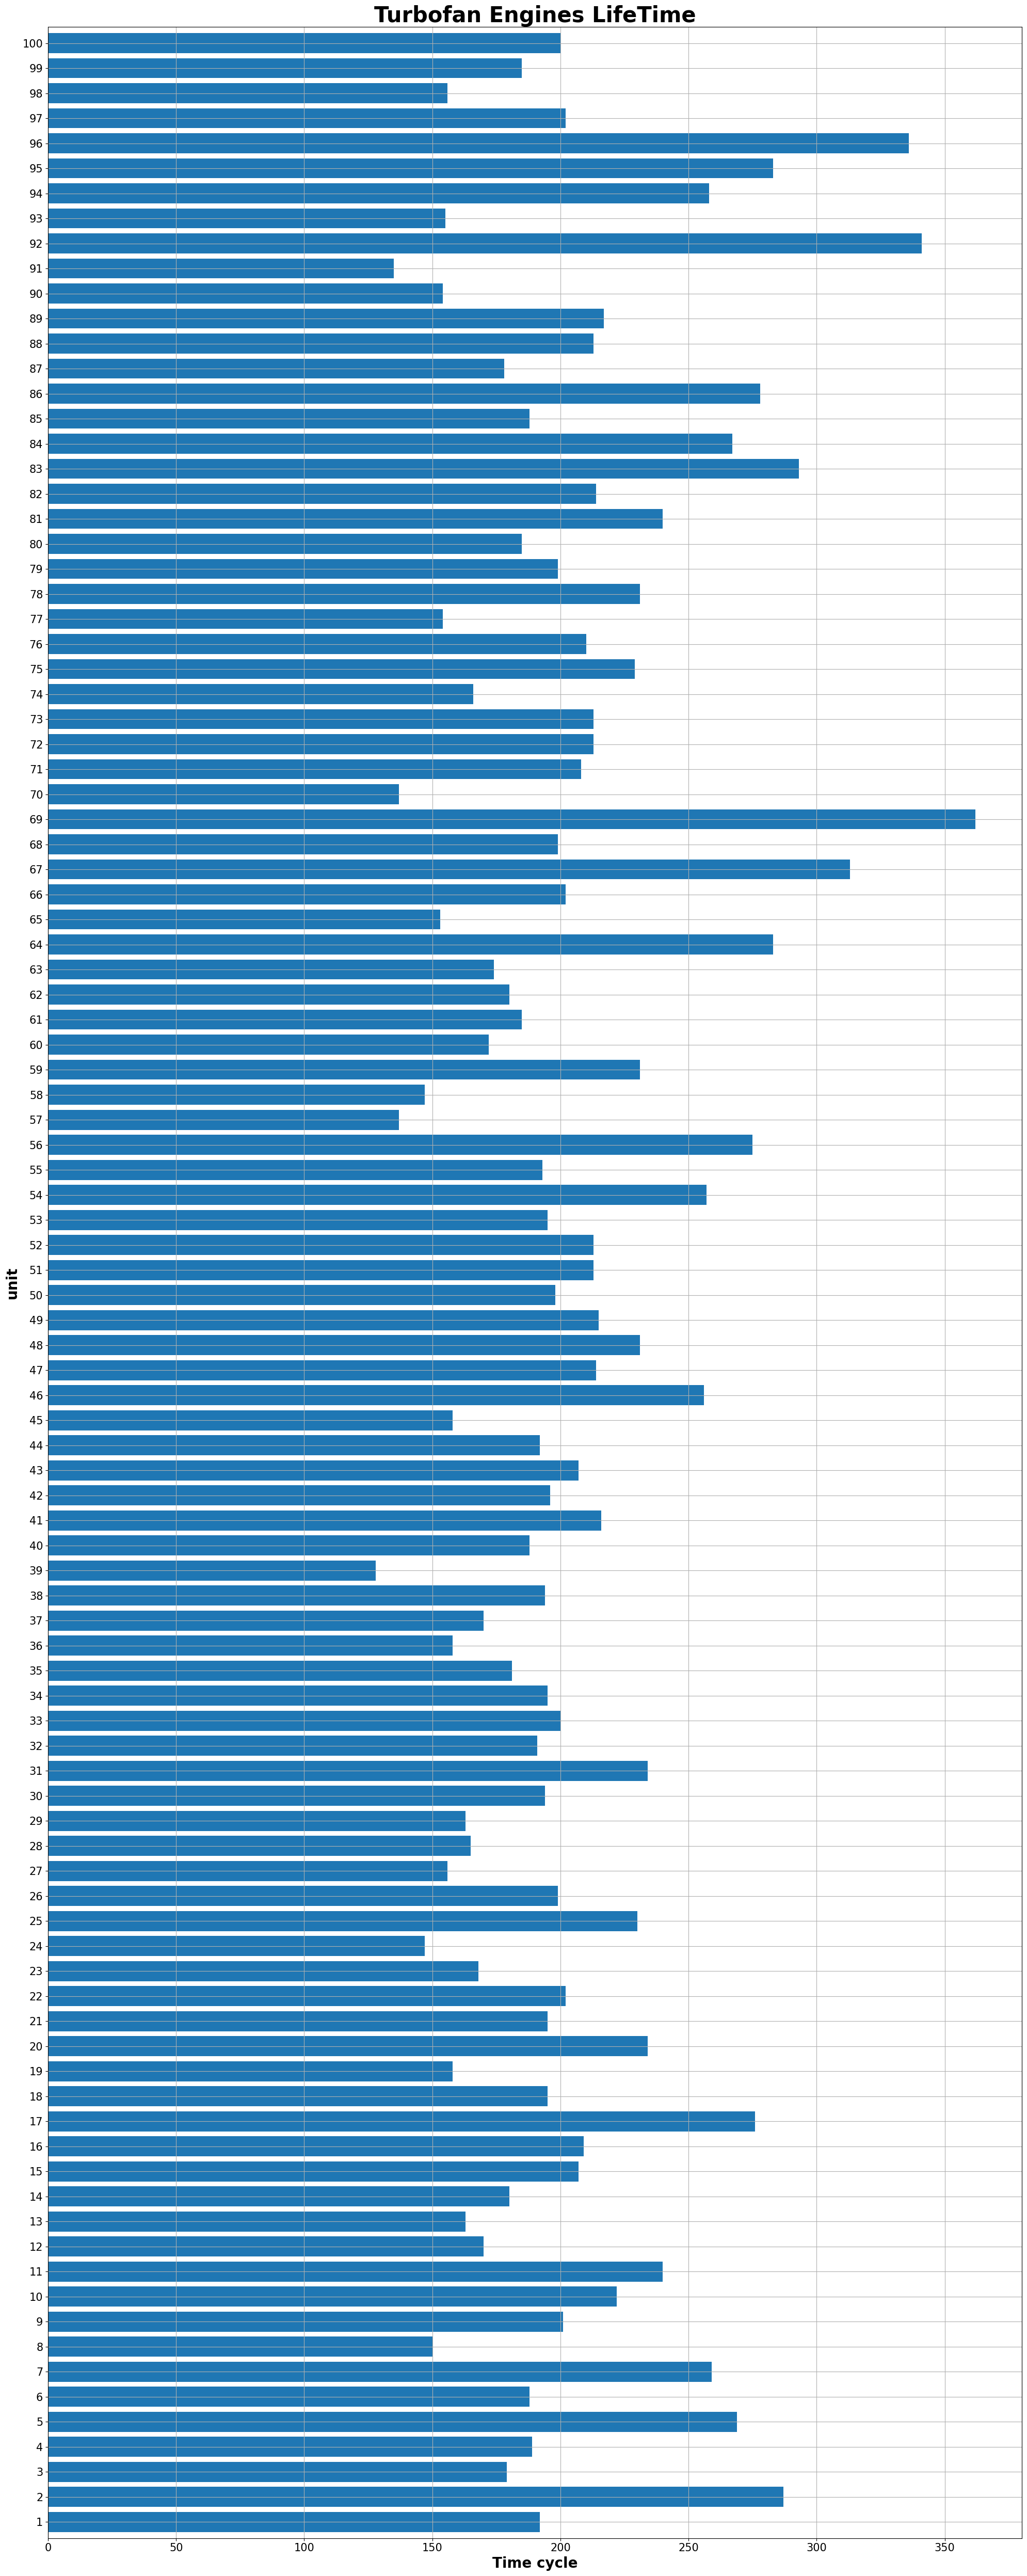

In [7]:
max_time_cycles=train[index_names].groupby('unit_number').max()
plt.figure(figsize=(20,50))
ax=max_time_cycles['time_cycles'].plot(kind='barh',width=0.8, stacked=True,align='center')
plt.title('Turbofan Engines LifeTime',fontweight='bold',size=30)
plt.xlabel('Time cycle',fontweight='bold',size=20)
plt.xticks(size=15)
plt.ylabel('unit',fontweight='bold',size=20)
plt.yticks(size=15)
plt.grid(True)
plt.tight_layout()
plt.show()

In [8]:
def add_RUL_column(df):
    train_grouped_by_unit = df.groupby(by='unit_number') 
    max_time_cycles = train_grouped_by_unit['time_cycles'].max() 
    merged = df.merge(max_time_cycles.to_frame(name='max_time_cycle'), left_on='unit_number',right_index=True)
    merged["RUL"] = merged["max_time_cycle"] - merged['time_cycles']
    merged = merged.drop("max_time_cycle", axis=1) 
    return merged

In [9]:
train = add_RUL_column(train)

In [10]:
train[['unit_number','RUL']]

,unit_number,RUL
0,1,191
1,1,190
2,1,189
3,1,188
4,1,187
...,...,...
20626,100,4
20627,100,3
20628,100,2
20629,100,1


In [11]:
#Rul analysis
maxrul_u = train.groupby('unit_number').max().reset_index()
maxrul_u.head()

,unit_number,time_cycles,setting_1,setting_2,setting_3,s_1,s_2,s_3,s_4,s_5,...,s_13,s_14,s_15,s_16,s_17,s_18,s_19,s_20,s_21,RUL
0,1,192,0.0047,0.0005,100.0,518.67,644.21,1605.44,1432.52,14.62,...,2388.35,8140.58,8.5227,0.03,398,2388,100.0,39.18,23.4999,191
1,2,287,0.0076,0.0006,100.0,518.67,643.94,1610.10,1431.17,14.62,...,2388.26,8175.57,8.5377,0.03,398,2388,100.0,39.24,23.6005,286
2,3,179,0.0058,0.0005,100.0,518.67,643.93,1606.50,1438.51,14.62,...,2388.20,8255.34,8.5363,0.03,399,2388,100.0,39.23,23.5181,178
3,4,189,0.0059,0.0006,100.0,518.67,644.53,1612.11,1434.12,14.62,...,2388.17,8259.42,8.5462,0.03,399,2388,100.0,39.21,23.5074,188
4,5,269,0.0055,0.0005,100.0,518.67,644.02,1609.41,1434.59,14.62,...,2388.23,8215.19,8.5410,0.03,398,2388,100.0,39.29,23.5503,268


## 3. EDA - Sensor Correlation and Signal Visualization

A correlation heatmap reveals the linear relationships between all 21 sensors (and operational settings) and the target RUL, helping identify informative features. Individual sensor signals are plotted against RUL for a sample of 10 engine units, revealing which sensors exhibit a clear monotonic degradation trend and which are constant or uninformative. Descriptive statistics are shown for all sensor columns.

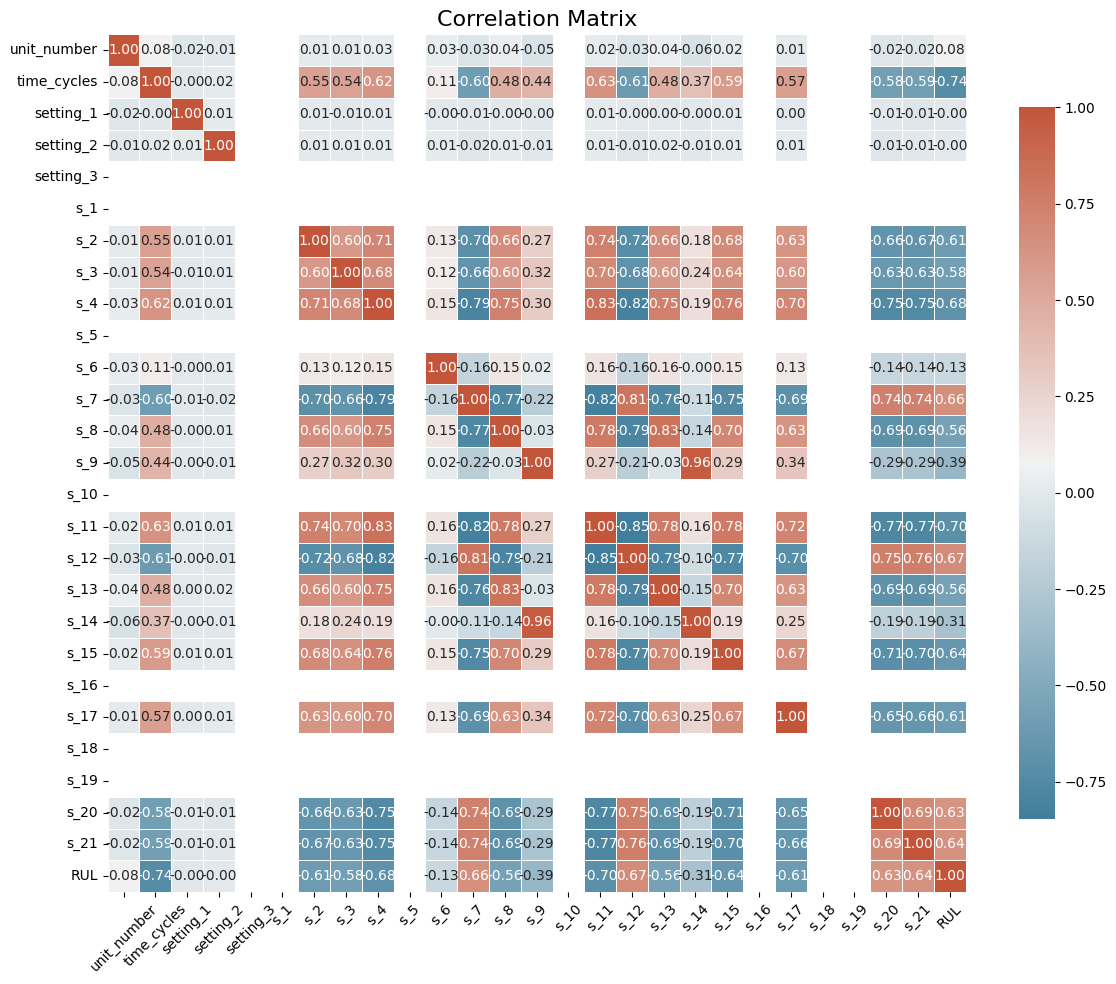

In [12]:
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

# Compute correlation matrix
corr = train.corr()

# Create figure
plt.figure(figsize=(12,10))

# Color palette
cmap = sns.diverging_palette(230, 20, as_cmap=True)

# Draw heatmap
sns.heatmap(
    corr,
    cmap=cmap,
    annot=True,
    fmt=".2f",
    square=True,
    linewidths=0.5,
    cbar_kws={"shrink": 0.8}
)

plt.title("Correlation Matrix", fontsize=16)
plt.xticks(rotation=45)
plt.yticks(rotation=0)
plt.tight_layout()

plt.show()

In [13]:
Sensor_dictionary={}
dict_list=[ "(Fan inlet temperature) (◦R)",
"(LPC outlet temperature) (◦R)",
"(HPC outlet temperature) (◦R)",
"(LPT outlet temperature) (◦R)",
"(Fan inlet Pressure) (psia)",
"(bypass-duct pressure) (psia)",
"(HPC outlet pressure) (psia)",
"(Physical fan speed) (rpm)",
"(Physical core speed) (rpm)",
"(Engine pressure ratio(P50/P2)",
"(HPC outlet Static pressure) (psia)",
"(Ratio of fuel flow to Ps30) (pps/psia)",
"(Corrected fan speed) (rpm)",
"(Corrected core speed) (rpm)",
"(Bypass Ratio) ",
"(Burner fuel-air ratio)",
"(Bleed Enthalpy)",
"(Required fan speed)",
"(Required fan conversion speed)",
"(High-pressure turbines Cool air flow)",
"(Low-pressure turbines Cool air flow)" ]
i=1
for x in dict_list :
    Sensor_dictionary['s_'+str(i)]=x
    i+=1
Sensor_dictionary

{'s_1': '(Fan inlet temperature) (◦R)',
 's_2': '(LPC outlet temperature) (◦R)',
 's_3': '(HPC outlet temperature) (◦R)',
 's_4': '(LPT outlet temperature) (◦R)',
 's_5': '(Fan inlet Pressure) (psia)',
 's_6': '(bypass-duct pressure) (psia)',
 's_7': '(HPC outlet pressure) (psia)',
 's_8': '(Physical fan speed) (rpm)',
 's_9': '(Physical core speed) (rpm)',
 's_10': '(Engine pressure ratio(P50/P2)',
 's_11': '(HPC outlet Static pressure) (psia)',
 's_12': '(Ratio of fuel flow to Ps30) (pps/psia)',
 's_13': '(Corrected fan speed) (rpm)',
 's_14': '(Corrected core speed) (rpm)',
 's_15': '(Bypass Ratio) ',
 's_16': '(Burner fuel-air ratio)',
 's_17': '(Bleed Enthalpy)',
 's_18': '(Required fan speed)',
 's_19': '(Required fan conversion speed)',
 's_20': '(High-pressure turbines Cool air flow)',
 's_21': '(Low-pressure turbines Cool air flow)'}

In [14]:
def plot_signal(df, Sensor_dic, signal_name):
    plt.figure(figsize=(13,5))
    for i in df['unit_number'].unique():
        if (i % 10 == 0):   #For a better visualisation, we plot the sensors signals of 20 units only
            plt.plot('RUL', signal_name, data=df[df['unit_number']==i].rolling(10).mean())

    plt.xlim(250, 0)  # reverse the x-axis so RUL counts down to zero
    plt.xticks(np.arange(0, 300, 25))
    plt.ylabel(Sensor_dic[signal_name])
    plt.xlabel('Remaining Useful Life')
    plt.show()


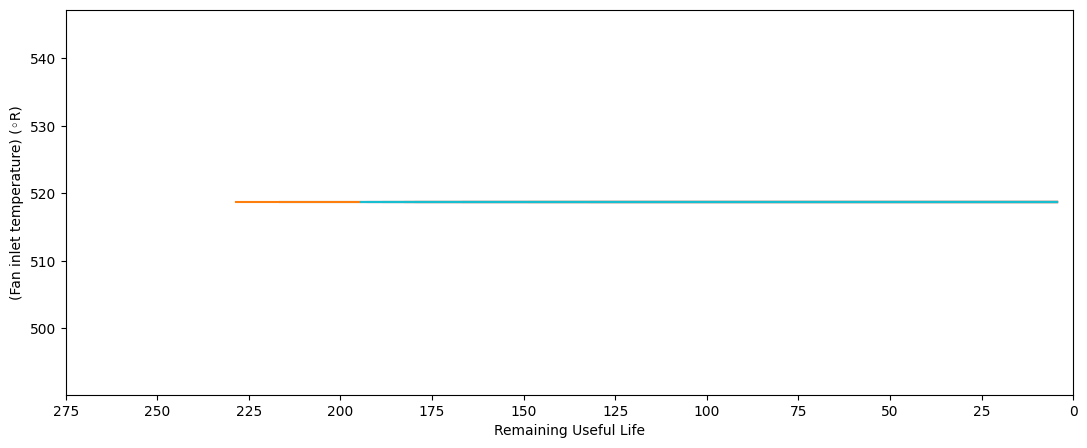

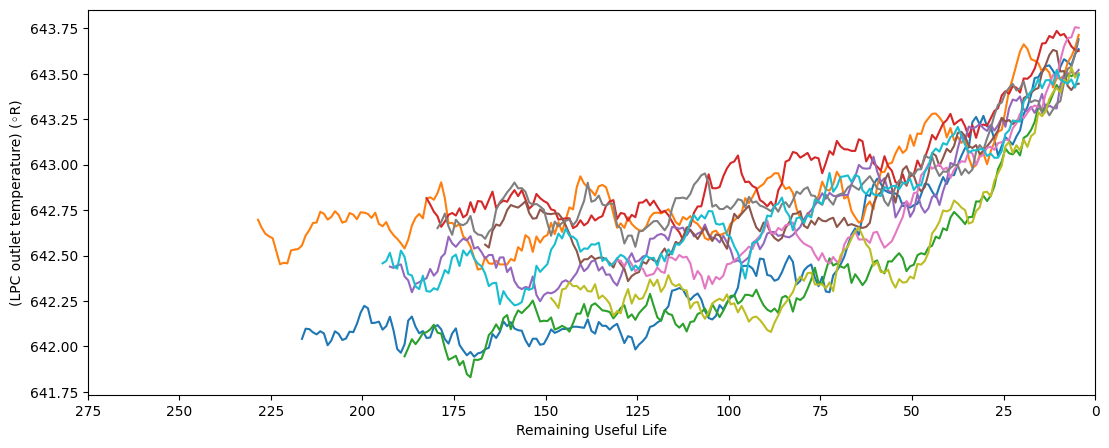

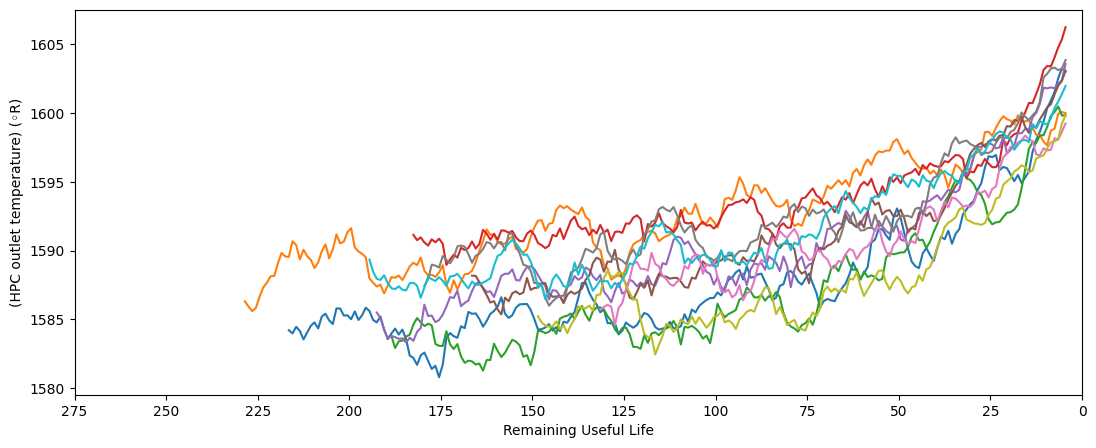

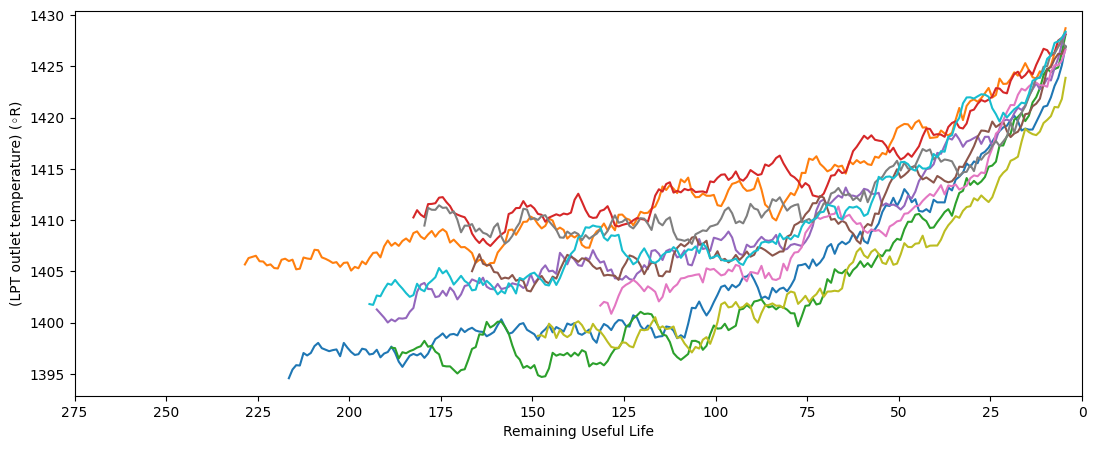

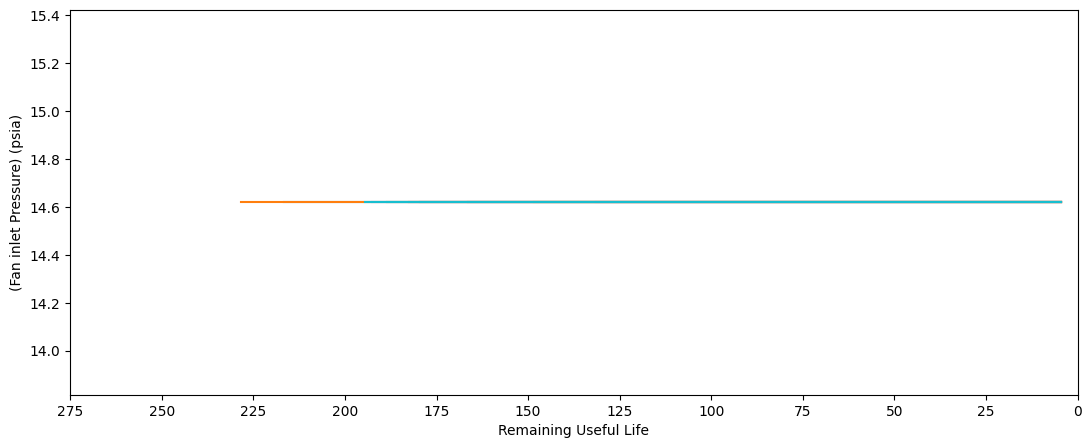

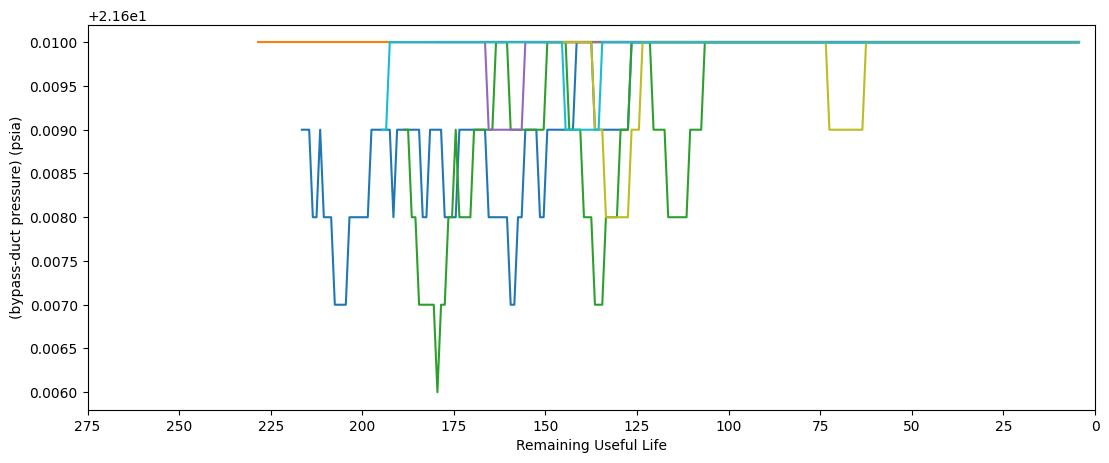

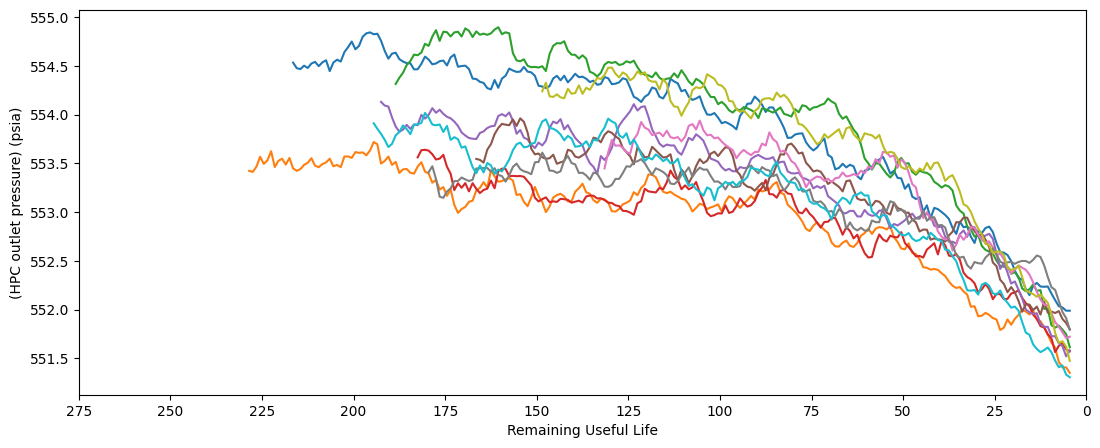

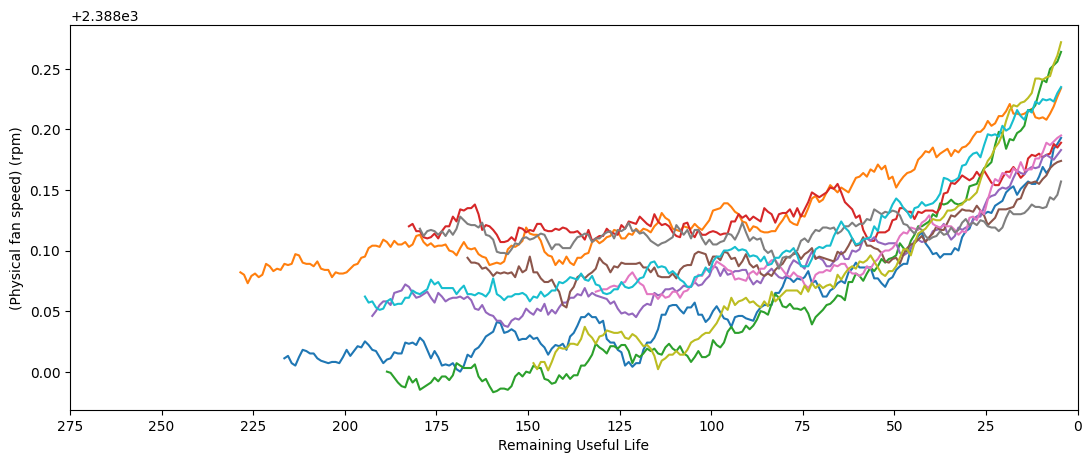

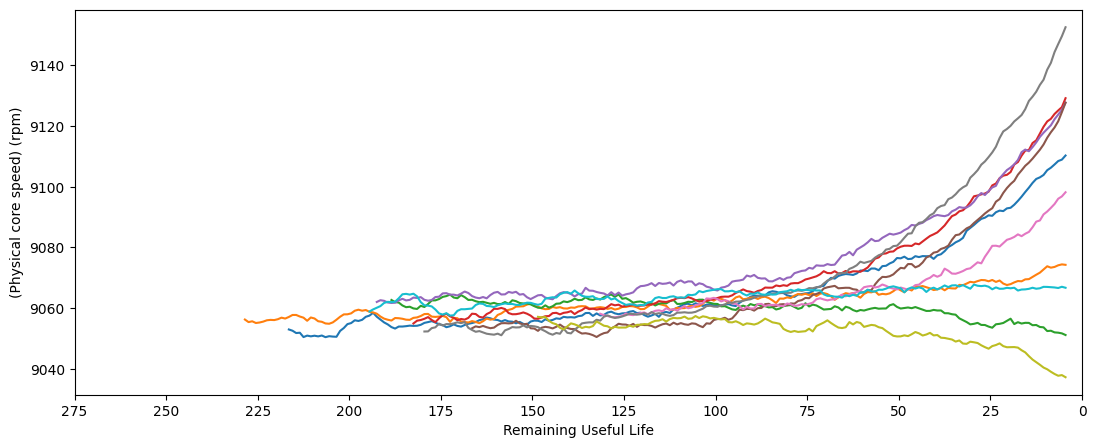

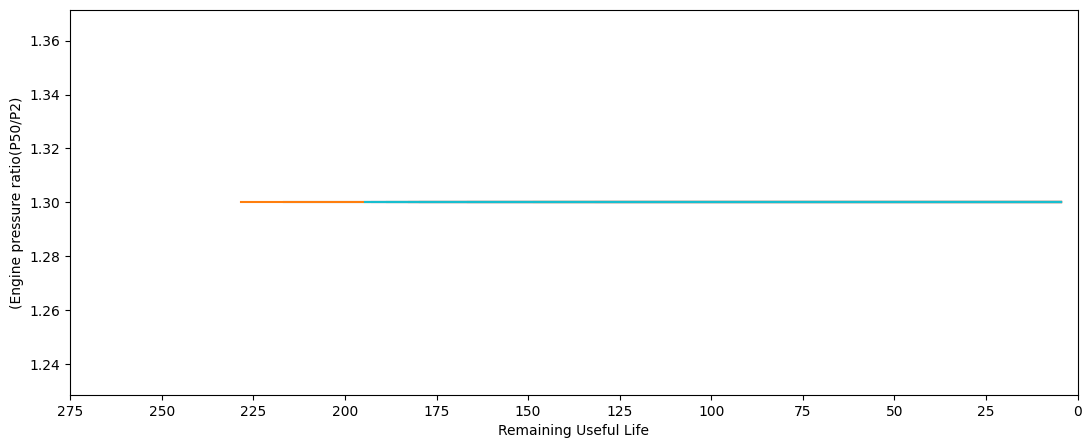

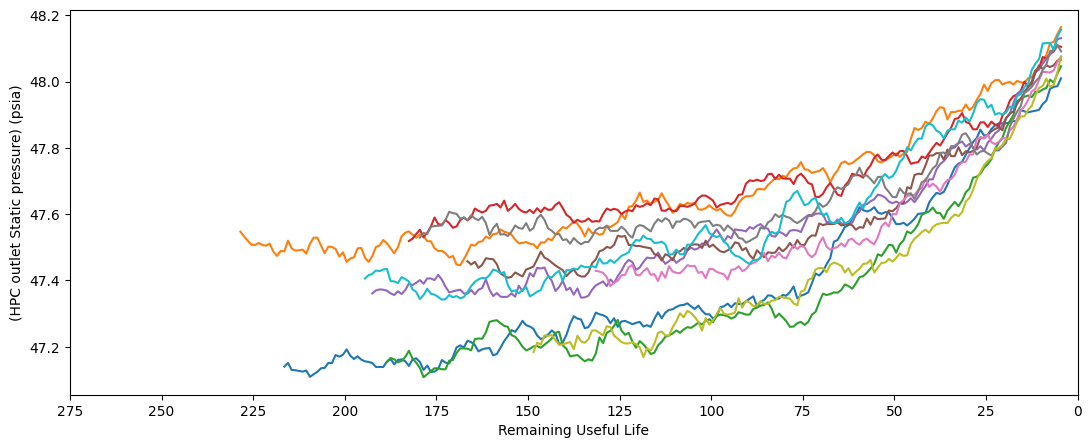

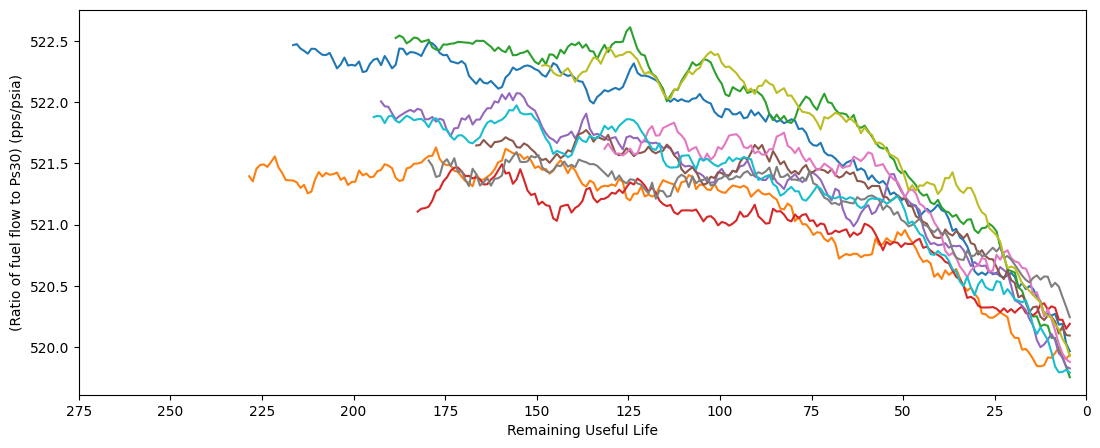

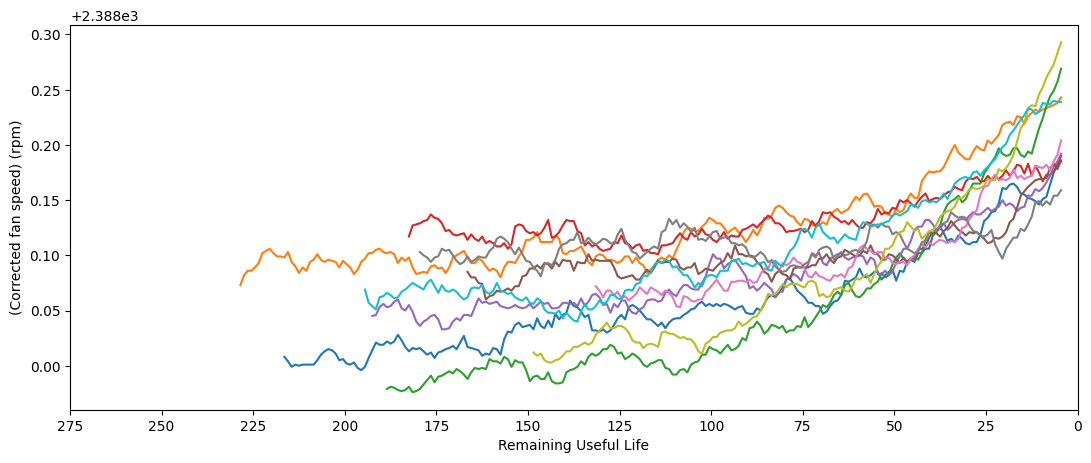

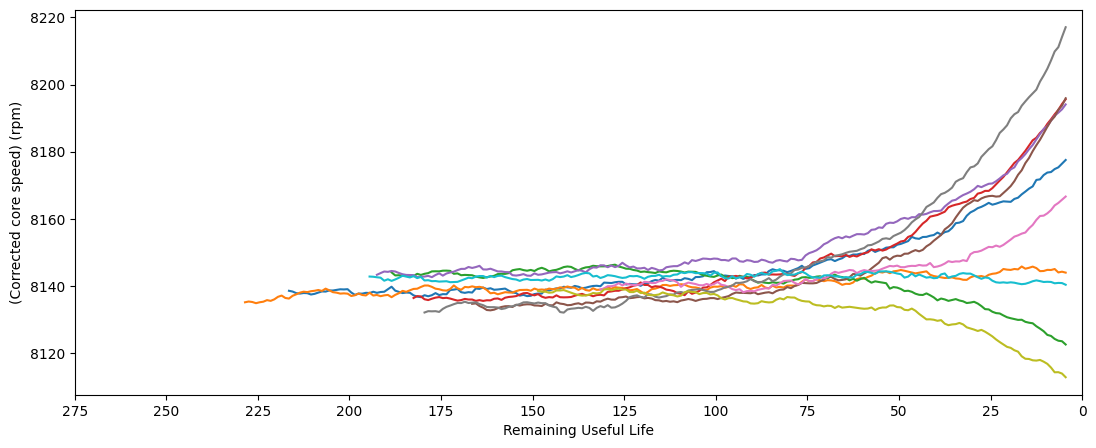

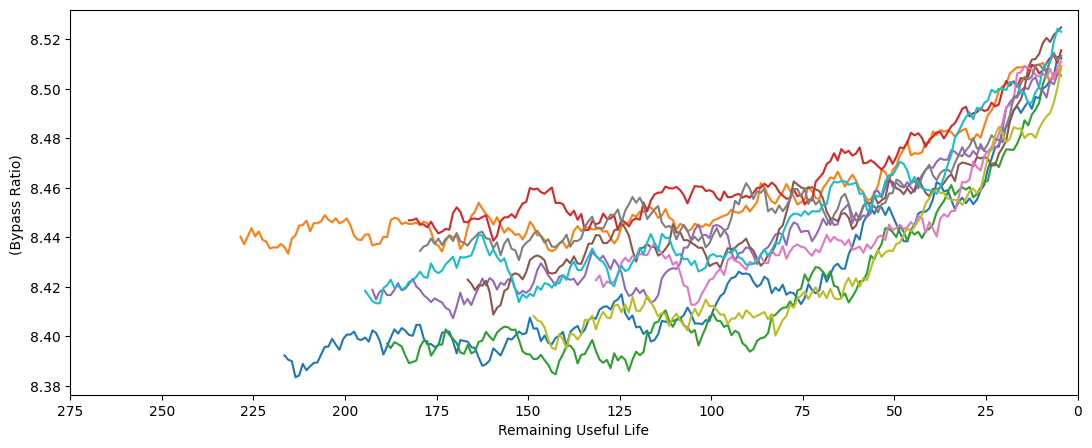

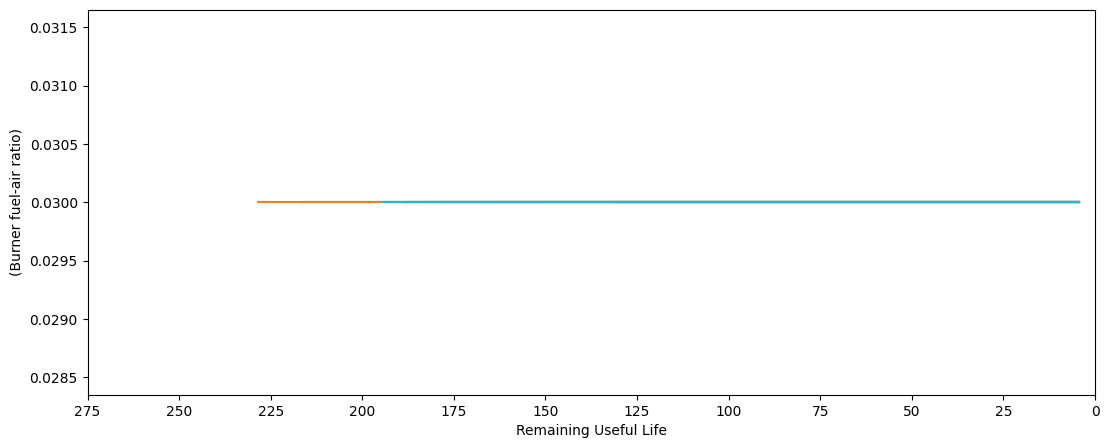

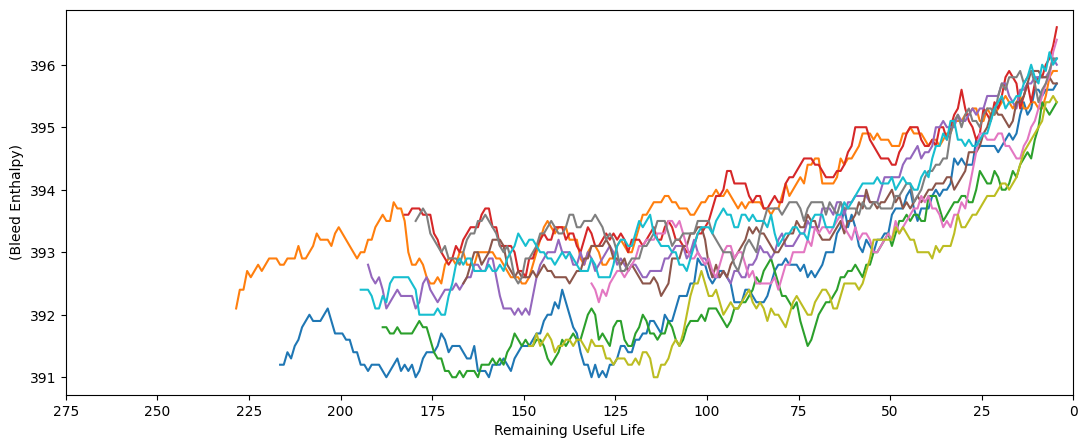

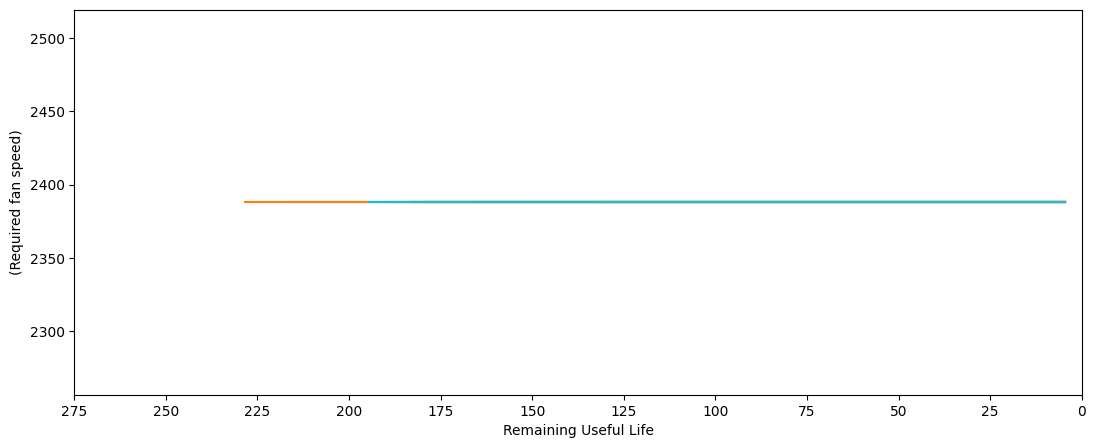

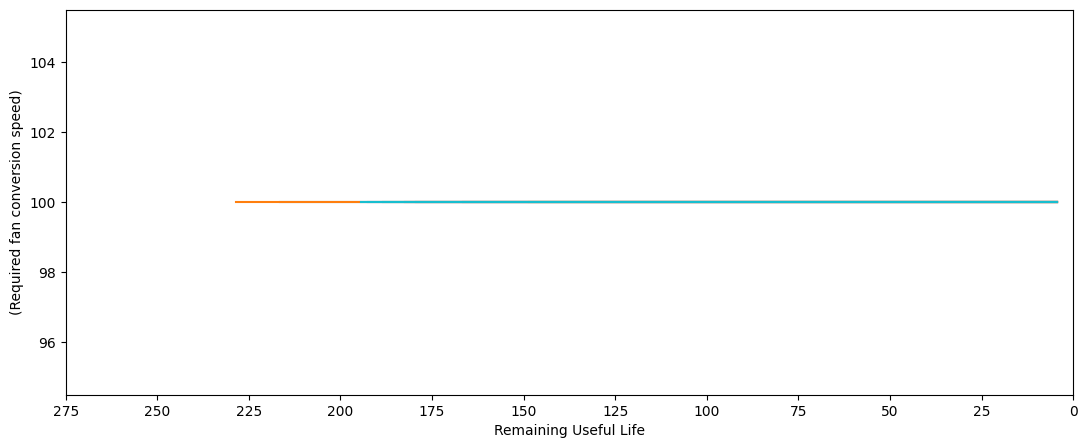

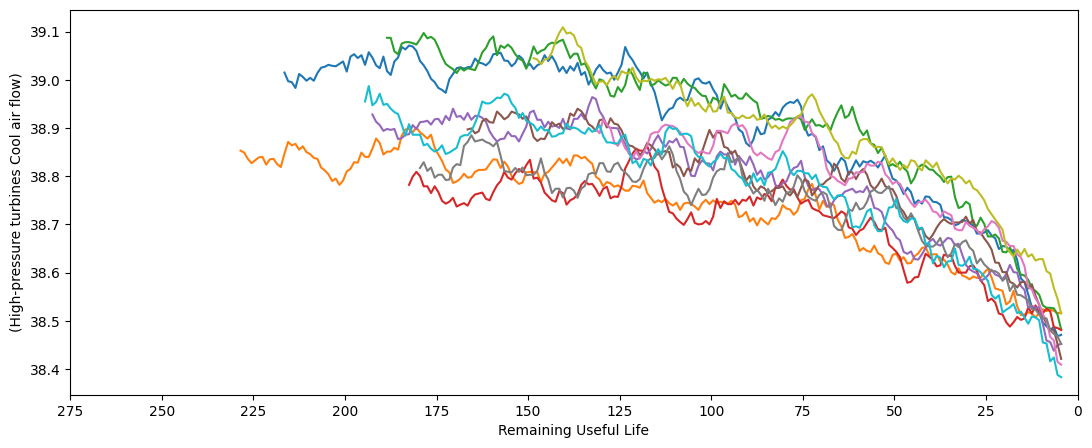

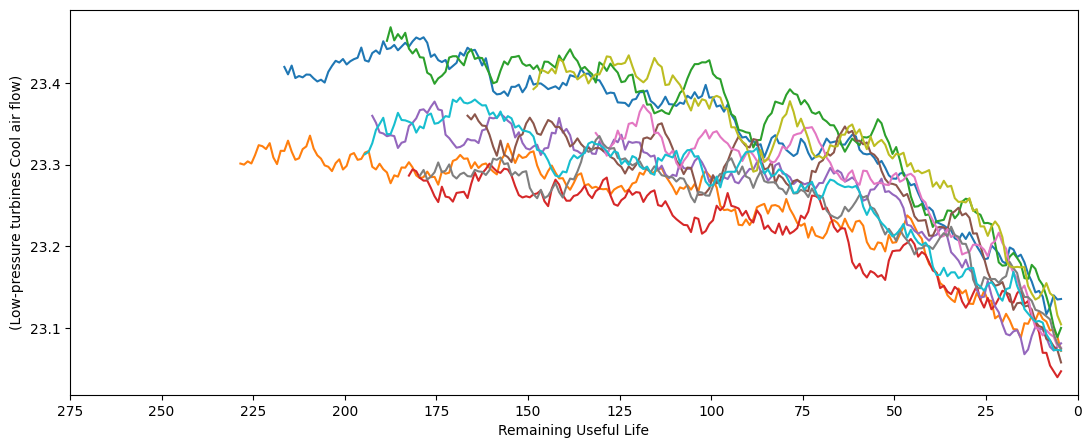

In [15]:
for i in range(1,22):
    try:
        plot_signal(train, Sensor_dictionary,'s_'+str(i))
    except:
        pass

In [16]:
train.loc[:,'s_1':].describe().transpose()

,count,mean,std,min,25%,50%,75%,max
s_1,20631.0,518.670000,0.000000e+00,518.6700,518.6700,518.6700,518.6700,518.6700
s_2,20631.0,642.680934,5.000533e-01,641.2100,642.3250,642.6400,643.0000,644.5300
s_3,20631.0,1590.523119,6.131150e+00,1571.0400,1586.2600,1590.1000,1594.3800,1616.9100
s_4,20631.0,1408.933782,9.000605e+00,1382.2500,1402.3600,1408.0400,1414.5550,1441.4900
s_5,20631.0,14.620000,1.776400e-15,14.6200,14.6200,14.6200,14.6200,14.6200
s_6,20631.0,21.609803,1.388985e-03,21.6000,21.6100,21.6100,21.6100,21.6100
s_7,20631.0,553.367711,8.850923e-01,549.8500,552.8100,553.4400,554.0100,556.0600
s_8,20631.0,2388.096652,7.098548e-02,2387.9000,2388.0500,2388.0900,2388.1400,2388.5600
s_9,20631.0,9065.242941,2.208288e+01,9021.7300,9053.1000,9060.6600,9069.4200,9244.5900
s_10,20631.0,1.300000,0.000000e+00,1.3000,1.3000,1.3000,1.3000,1.3000


## 4. Train / Test / Validation Split and Feature Scaling

The training dataframe is split **70 / 30** into an internal train and test set (random_state=42). A "MinMaxScaler" is fitted on the training features only and then applied to all three splits to prevent data leakage. For the validation set, only the **last recorded time step** of each test engine is used as the feature vector (most recent sensor snapshot), matched against the true RUL provided in RUL_FD001.txt.

In [17]:
from sklearn.model_selection import train_test_split
drop_labels = index_names+setting_names
X_train=train.drop(columns=drop_labels).copy()
X_train, X_test, y_train, y_test=train_test_split(X_train,X_train['RUL'], test_size=0.3, random_state=42)

#Removing useless columns

In [18]:
from sklearn.preprocessing import MinMaxScaler
scaler = MinMaxScaler()

#Dropping the target variable
X_train.drop(columns=['RUL'], inplace=True)
X_test.drop(columns=['RUL'], inplace=True)

#Scaling X_train and X_test
X_train_s=scaler.fit_transform(X_train)
X_test_s=scaler.fit_transform(X_test)

#Conserve only the last occurence of each unit to match the length of y_valid
X_valid = valid.groupby('unit_number').last().reset_index().drop(columns=drop_labels)

#scaling X_valid
X_valid_s=scaler.fit_transform(X_valid)


In [19]:
print(X_valid_s.shape)
print(y_valid.shape)

(100, 21)
(100, 1)


## 5. Model and Helper Function Definitions

**This notebook trains 6 models across 4 feature-engineering phases for the same RUL prediction objective:**

| # | Model | Implementation |
|---|-------|---------------|
| 1 | **Custom Linear Regression** (gradient descent) | Implemented from scratch using NumPy |
| 2 | **Support Vector Regression (SVR, RBF kernel)** | sklearn.svm.SVR |
| 3 | **Random Forest Regressor** | sklearn.ensemble.RandomForestRegressor |
| 4 | **XGBoost Regressor** | xgboost.XGBRegressor |
| 5 | **LSTM** | tensorflow.keras - 2-layer stacked LSTM with dropout |
| 6 | **Cost-Sensitive LSTM** | Same LSTM architecture with an asymmetric overprediction-penalising loss function |

Helper functions: evaluate(y_true, y_hat, label) computes and prints **RMSE** and **R²** for a given split; plot_predActual(y_test, y_pred) renders a side-by-side bar chart of true vs predicted RUL for each validation engine.

In [20]:
#Lin Reg
class Linear_Regression() :
    def __init__( self, lr=0.01, iterations=150 ) :    
        self.lr = lr
        self.iterations = iterations     
    def fit( self, X, Y ) :
        self.l, self.p = X.shape
        # weight initializer
        self.W = np.zeros( self.p )
        self.b = 0
        self.X = X
        self.Y = Y
        # gradientlearning      
        for i in range( self.iterations ) :  
            self.weight_updater()
        return self
         
    def weight_updater( self ) :
        Y_pred = self.predict( self.X )  
        #  gradients  
        dW = - ( 2 * ( self.X.T ).dot( self.Y - Y_pred )  ) / self.l
        db = - 2 * np.sum( self.Y - Y_pred ) / self.l
        # new weights assigned
        self.b = self.b - self.lr * db
        self.W = self.W - self.lr * dW
        return self
          
    def predict( self, X ) :
          # Y_pr=X.W+b
        return X.dot( self.W ) + self.b
     
  

In [21]:
from sklearn.svm import SVR
import tensorflow as tf
regressor = SVR(kernel='rbf')

In [22]:
rf = RandomForestRegressor(max_features="sqrt", random_state=42)

In [23]:
def evaluate(y_true, y_hat, label='test'):
    mse = mean_squared_error(y_true, y_hat)
    rmse = np.sqrt(mse)
    variance = r2_score(y_true, y_hat)
    print('{} set RMSE:{}, R2:{}'.format(label, rmse, variance))

In [24]:
def plot_predActual(y_test, y_test_hat):
  
    indices = np.arange(len(y_test_hat))
    wth= 0.6
    plt.figure(figsize=(70,30))
    true_values = [int(x) for x in y_test.values]
    predicted_values = list(y_test_hat)

    plt.bar(indices, true_values, width=wth,color='b', label='True RUL')
    plt.bar([i for i in indices], predicted_values, width=0.5*wth, color='r', alpha=0.7, label='Predicted RUL')

    plt.legend(prop={'size': 40})
    plt.tick_params(labelsize=40)

    plt.show()

## 6. Phase 1: Baseline Model Training - All 21 Sensors, No Feature Engineering

Three models (Linear Regression, SVR, Random Forest) are trained on all 21 raw sensor features with MinMax scaling and **no RUL clipping**. This establishes the baseline before any feature selection or engineering.

**Reported error metrics: RMSE (lower is better) and R² (higher is better) on train, internal test, and validation sets.**

In [25]:
lr=Linear_Regression() 
lr.fit(X=X_train_s, Y=y_train) 

y_lr_train = lr.predict(X_train_s) 
evaluate(y_train,y_lr_train, label='train')

y_lr_test = lr.predict(X_test_s)  
evaluate(y_test, y_lr_test, label='test')

y_lr_valid= lr.predict(X_valid_s) 
evaluate(y_valid, y_lr_valid, label='valid')

train set RMSE:56.19869318681088, R2:0.3439361345919162
test set RMSE:54.264009074691856, R2:0.35713062175493715
valid set RMSE:34.84962228223509, R2:0.2967064952591344


In [26]:
regressor.fit(X_train_s, y_train) 

y_svr_train = regressor.predict(X_train_s) 
evaluate(y_train,y_svr_train, label='train')

y_svr_test = regressor.predict(X_test_s) 
evaluate(y_test, y_svr_test, label='test')

y_svr_valid= regressor.predict(X_valid_s)  
evaluate(y_valid, y_svr_valid, label='valid')

train set RMSE:43.56448464126648, R2:0.605761670162996
test set RMSE:47.26718449996111, R2:0.5122262167433573
valid set RMSE:27.11886101817364, R2:0.5741238232909898


In [27]:
rf.fit(X_train_s, y_train)

y_rf_train = rf.predict(X_train_s)
evaluate(y_train,y_rf_train, label='train')

y_rf_test = rf.predict(X_test_s)
evaluate(y_test, y_rf_test, label='test')

y_rf_valid = rf.predict(X_valid_s)
evaluate(y_valid, y_rf_valid, label='valid')

train set RMSE:15.408303170220156, R2:0.9506822432050425
test set RMSE:44.36383009860364, R2:0.5703082128383993
valid set RMSE:30.653618024631285, R2:0.45586841183607596


## 7. Phase 1: Prediction vs Ground Truth - Baseline Models

The bar charts below compare predicted vs actual RUL for each of the 100 validation engines. A perfect model would produce bars of equal height. Systematic over- or under-prediction of high-RUL engines reveals the effect of not clipping the target.

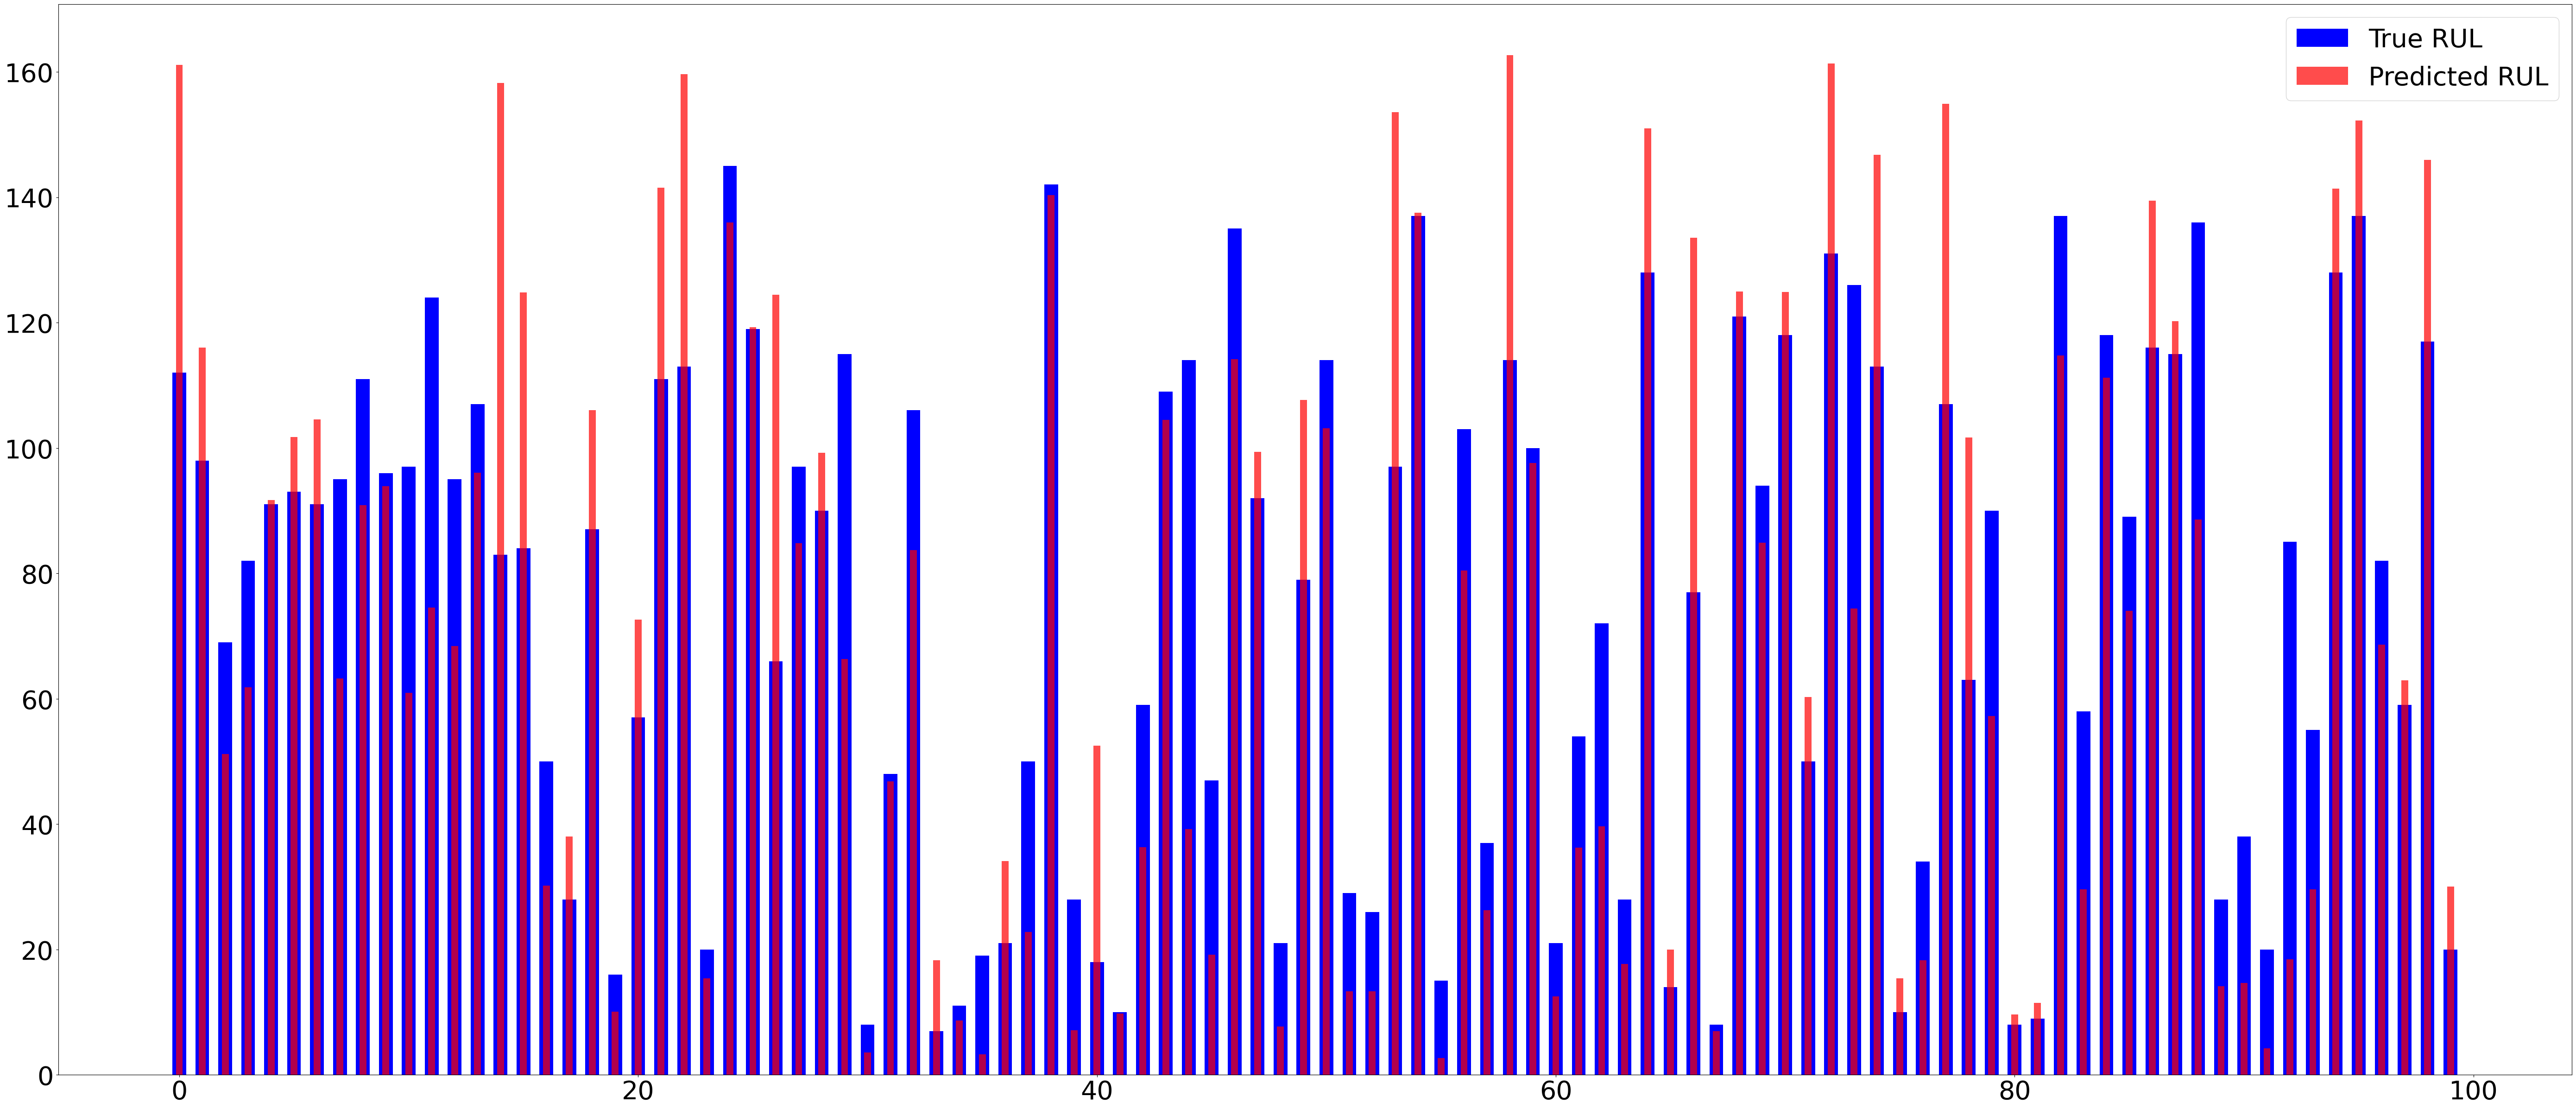

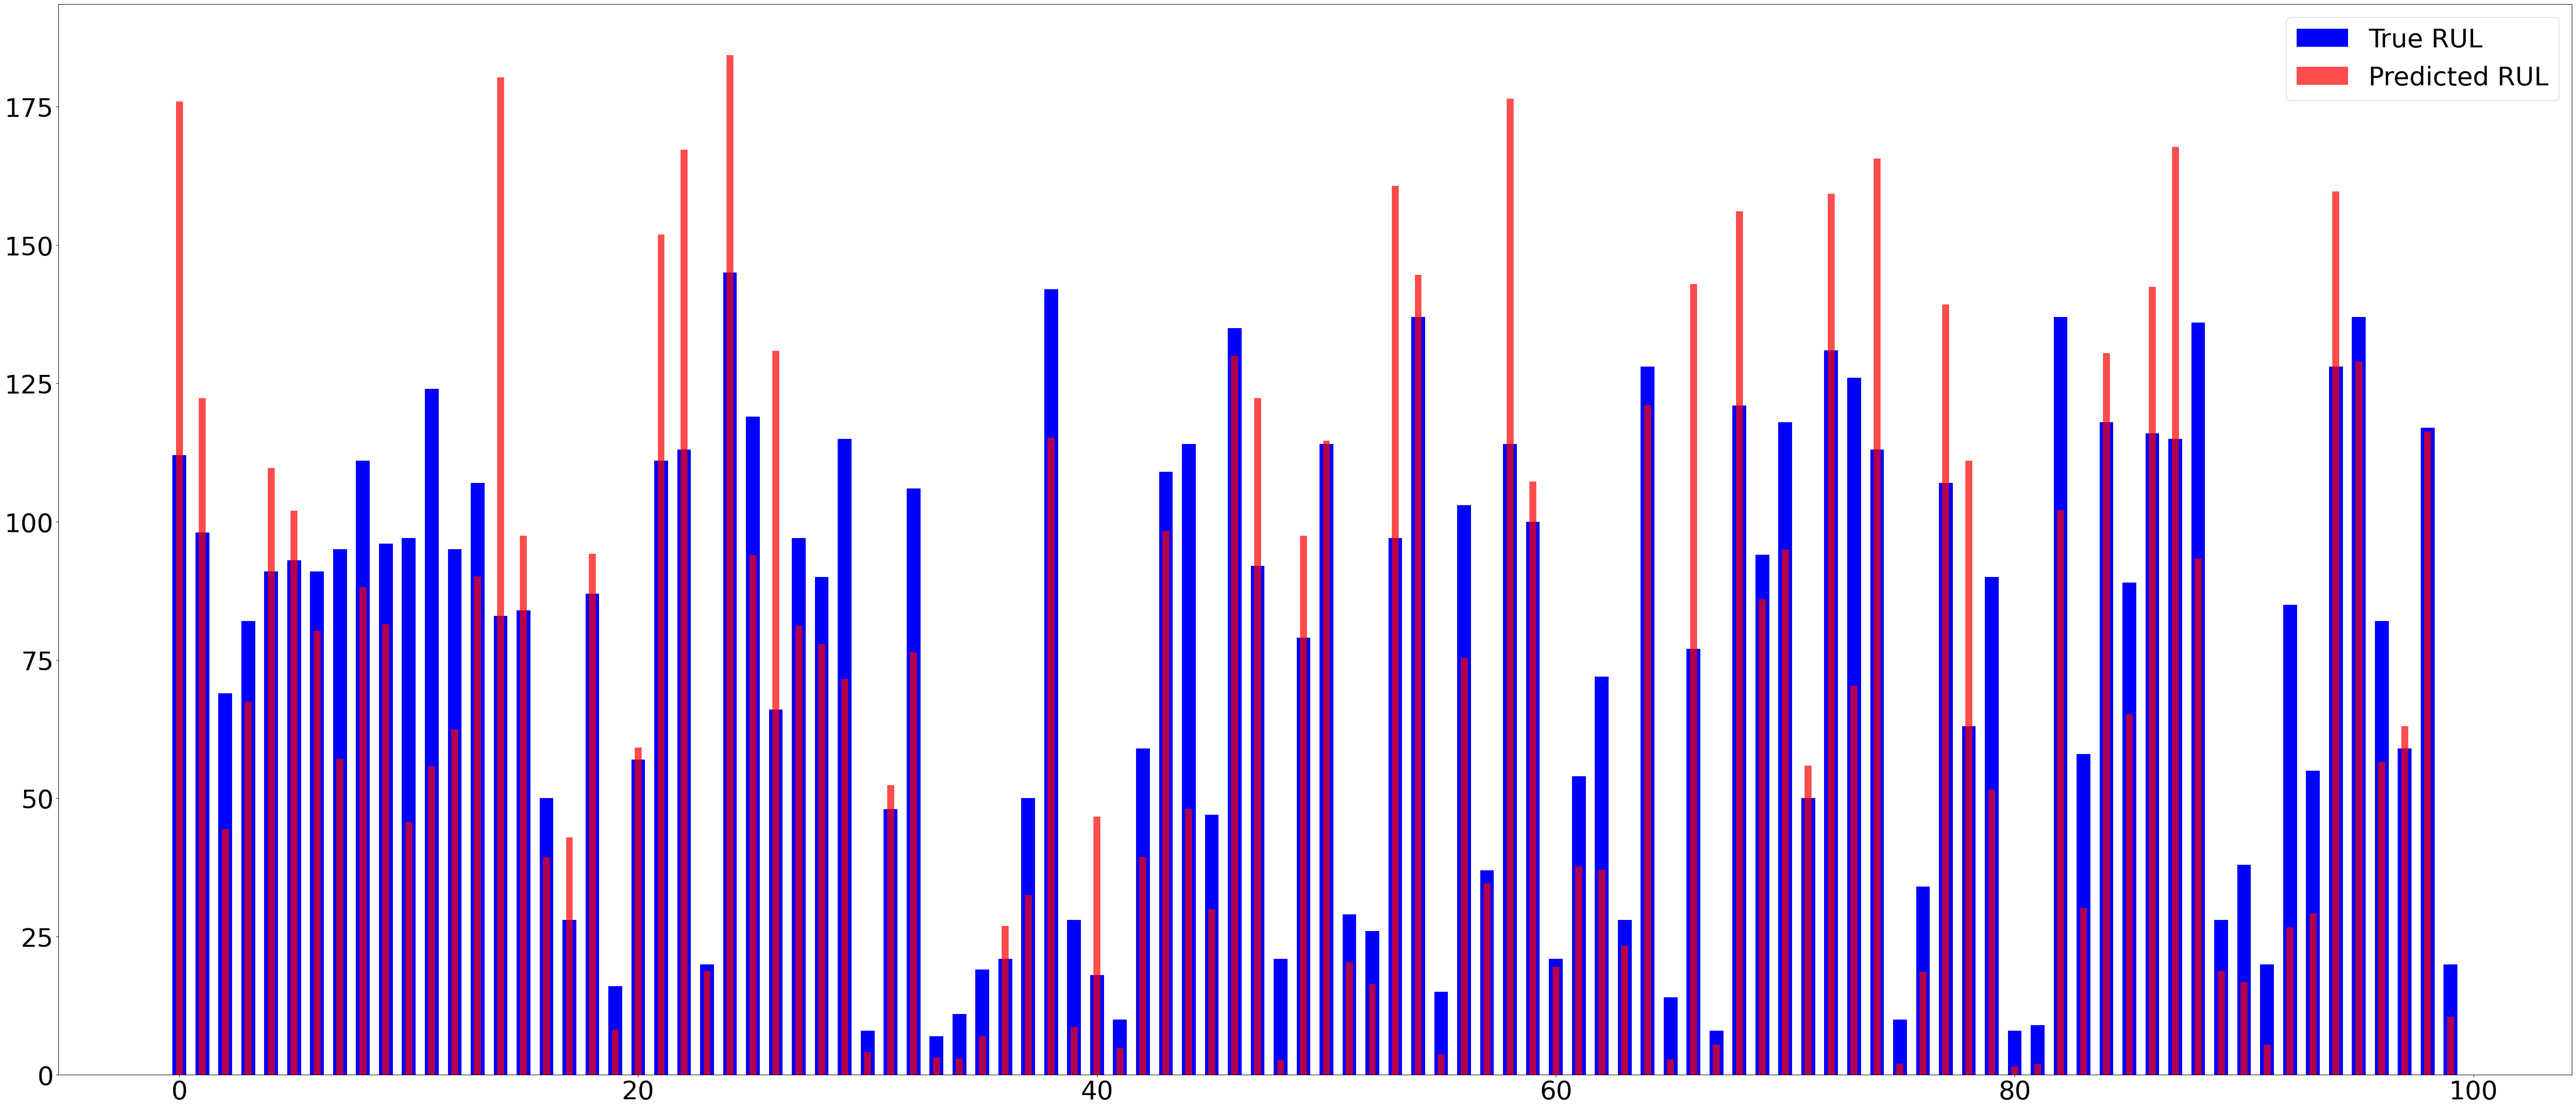

In [28]:
plot_predActual(y_valid, y_svr_valid)
plot_predActual(y_valid, y_rf_valid)

In [29]:
print('maximum of y_train : ',y_train.max())
print('maximum of y_test : ',y_test.max())
print('maximum of y_valid : ',y_valid.max())

maximum of y_train :  361
maximum of y_test :  360
maximum of y_valid :  RUL    145
dtype: int64


(array([1023., 1066., 1083., 1120.,  937.,  557.,  237.,  117.,   35.,
          15.]),
 array([  0.,  36.,  72., 108., 144., 180., 216., 252., 288., 324., 360.]),
 <BarContainer object of 10 artists>)

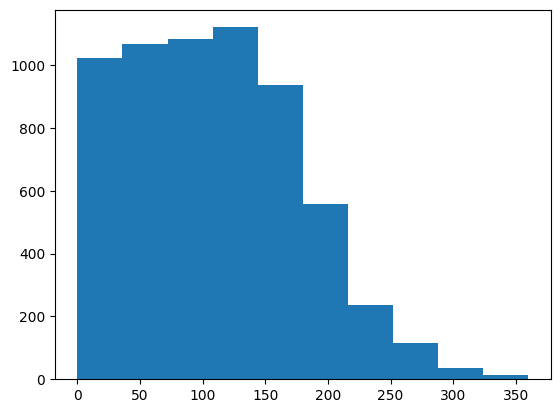

In [30]:
plt.hist(y_test)

## 8. Phase 2: Feature Selection and RUL Clipping

Two targeted improvements over the Phase 1 baseline:

1. **Remove 7 near-constant sensors** (s_1, s_5, s_6, s_10, s_16, s_18, s_19) — these showed negligible variance across the fleet in the descriptive statistics and signal plots above.
2. **Clip RUL at 195 cycles** (y_train.clip(upper=195)) — implements the piecewise-linear degradation assumption: engines far from failure have high uncertainty in their RUL labels, and clipping focuses the model on the degradation-onset region.

Four models (now including XGBoost) are trained with hyperparameter tuning applied to Random Forest and XGBoost.

**Reported error metrics: RMSE and R² on train, test, and validation sets.**

In [31]:
drop_labels2=['s_1', 's_5','s_6','s_10',  's_16', 's_18', 's_19']
X_train_2=X_train.drop(columns=drop_labels2, axis=1) # drop the constant columns from the train dataset
X_test_2=X_test.drop(columns=drop_labels2, axis=1)  # drop the constant columns from the test dataset
X_train_2_s=scaler.fit_transform(X_train_2) #scaling X_train_2
X_test_2_s=scaler.fit_transform(X_test_2) #scaling X_test_2
y_train_clip=y_train.clip(upper=195)  #Clipping y_train to have 195 as the maximum value 
X_valid_2=X_valid.drop(columns=drop_labels2, axis=1)  # drop the constant columns from the validation dataset
X_valid_2_s=scaler.fit_transform(X_valid_2) #scaling X_valid_2

In [32]:
lr=Linear_Regression()
lr.fit(X=X_train_2_s, Y=y_train_clip)

y_lr_train = lr.predict(X_train_2_s)
evaluate(y_train_clip,y_lr_train, label='train')

y_lr_test = lr.predict(X_test_2_s)
evaluate(y_test, y_lr_test, label='test')

y_lr_valid = lr.predict(X_valid_2_s)
evaluate(y_valid, y_lr_valid, label='valid')

train set RMSE:47.86312955545103, R2:0.3792662465007207
test set RMSE:55.6261002397046, R2:0.3244519972933424
valid set RMSE:34.21070108960351, R2:0.3222579927041398


In [33]:
regressor.fit(X_train_2_s, y_train)

y_svr_train = regressor.predict(X_train_2_s)
evaluate(y_train_clip,y_svr_train, label='train')

y_svr_test = regressor.predict(X_test_2_s)
evaluate(y_test, y_svr_test, label='test')

y_svr_valid = regressor.predict(X_valid_2_s)
evaluate(y_valid, y_svr_valid, label='valid')


train set RMSE:32.91543148706822, R2:0.7064363470171213
test set RMSE:48.75516379159361, R2:0.48103242301470384
valid set RMSE:25.94791222536621, R2:0.6101071274546096


In [34]:
rf = RandomForestRegressor(max_features=0.3, random_state=42, max_depth=5, min_samples_leaf=50, min_samples_split=100, n_estimators=200, max_samples=0.7)
rf.fit(X_train_2_s, y_train_clip)

y_rf_train = rf.predict(X_train_2_s)
evaluate(y_train_clip,y_rf_train, label='train')

y_rf_test = rf.predict(X_test_2_s)
evaluate(y_test, y_rf_test, label='test')

y_rf_valid = rf.predict(X_valid_2_s)
evaluate(y_valid, y_rf_valid, label='valid')

train set RMSE:33.26114198115595, R2:0.700237370130459
test set RMSE:45.28155120797087, R2:0.5523469186421937
valid set RMSE:25.68582251147002, R2:0.6179436605457991


In [35]:
import xgboost
xgb = xgboost.XGBRegressor(n_estimators=200, learning_rate=0.02, gamma=3, subsample=0.6, colsample_bytree=0.4, max_depth=2, reg_alpha=1, reg_lambda=5, min_child_weight=15)
xgb.fit(X_train_2_s, y_train_clip)


y_xgb_train = xgb.predict(X_train_2_s)
evaluate(y_train_clip,y_xgb_train, label='train')

y_xgb_test = xgb.predict(X_test_2_s)
evaluate(y_test, y_xgb_test, label='test')

y_xgb_valid = xgb.predict(X_valid_2_s)
evaluate(y_valid, y_xgb_valid, label='valid')

train set RMSE:33.25617453242706, R2:0.7003269195556641
test set RMSE:45.792508747849524, R2:0.5421872138977051
valid set RMSE:23.714331254242392, R2:0.67434161901474


## 9. Phase 2: Prediction vs Ground Truth — Feature-Selected and Tuned Models

Hyperparameter changes from Phase 1:
- **Random Forest**: max_depth=5, min_samples_leaf=50, min_samples_split=100, n_estimators=200, max_samples=0.7 - regularised to reduce overfitting.
- **XGBoost**: learning_rate=0.02, gamma=3, max_depth=2, reg_alpha=1, reg_lambda=5 - strong regularisation for smooth, generalising predictions.

Bar charts below show predicted vs actual RUL on the 100 validation engines.

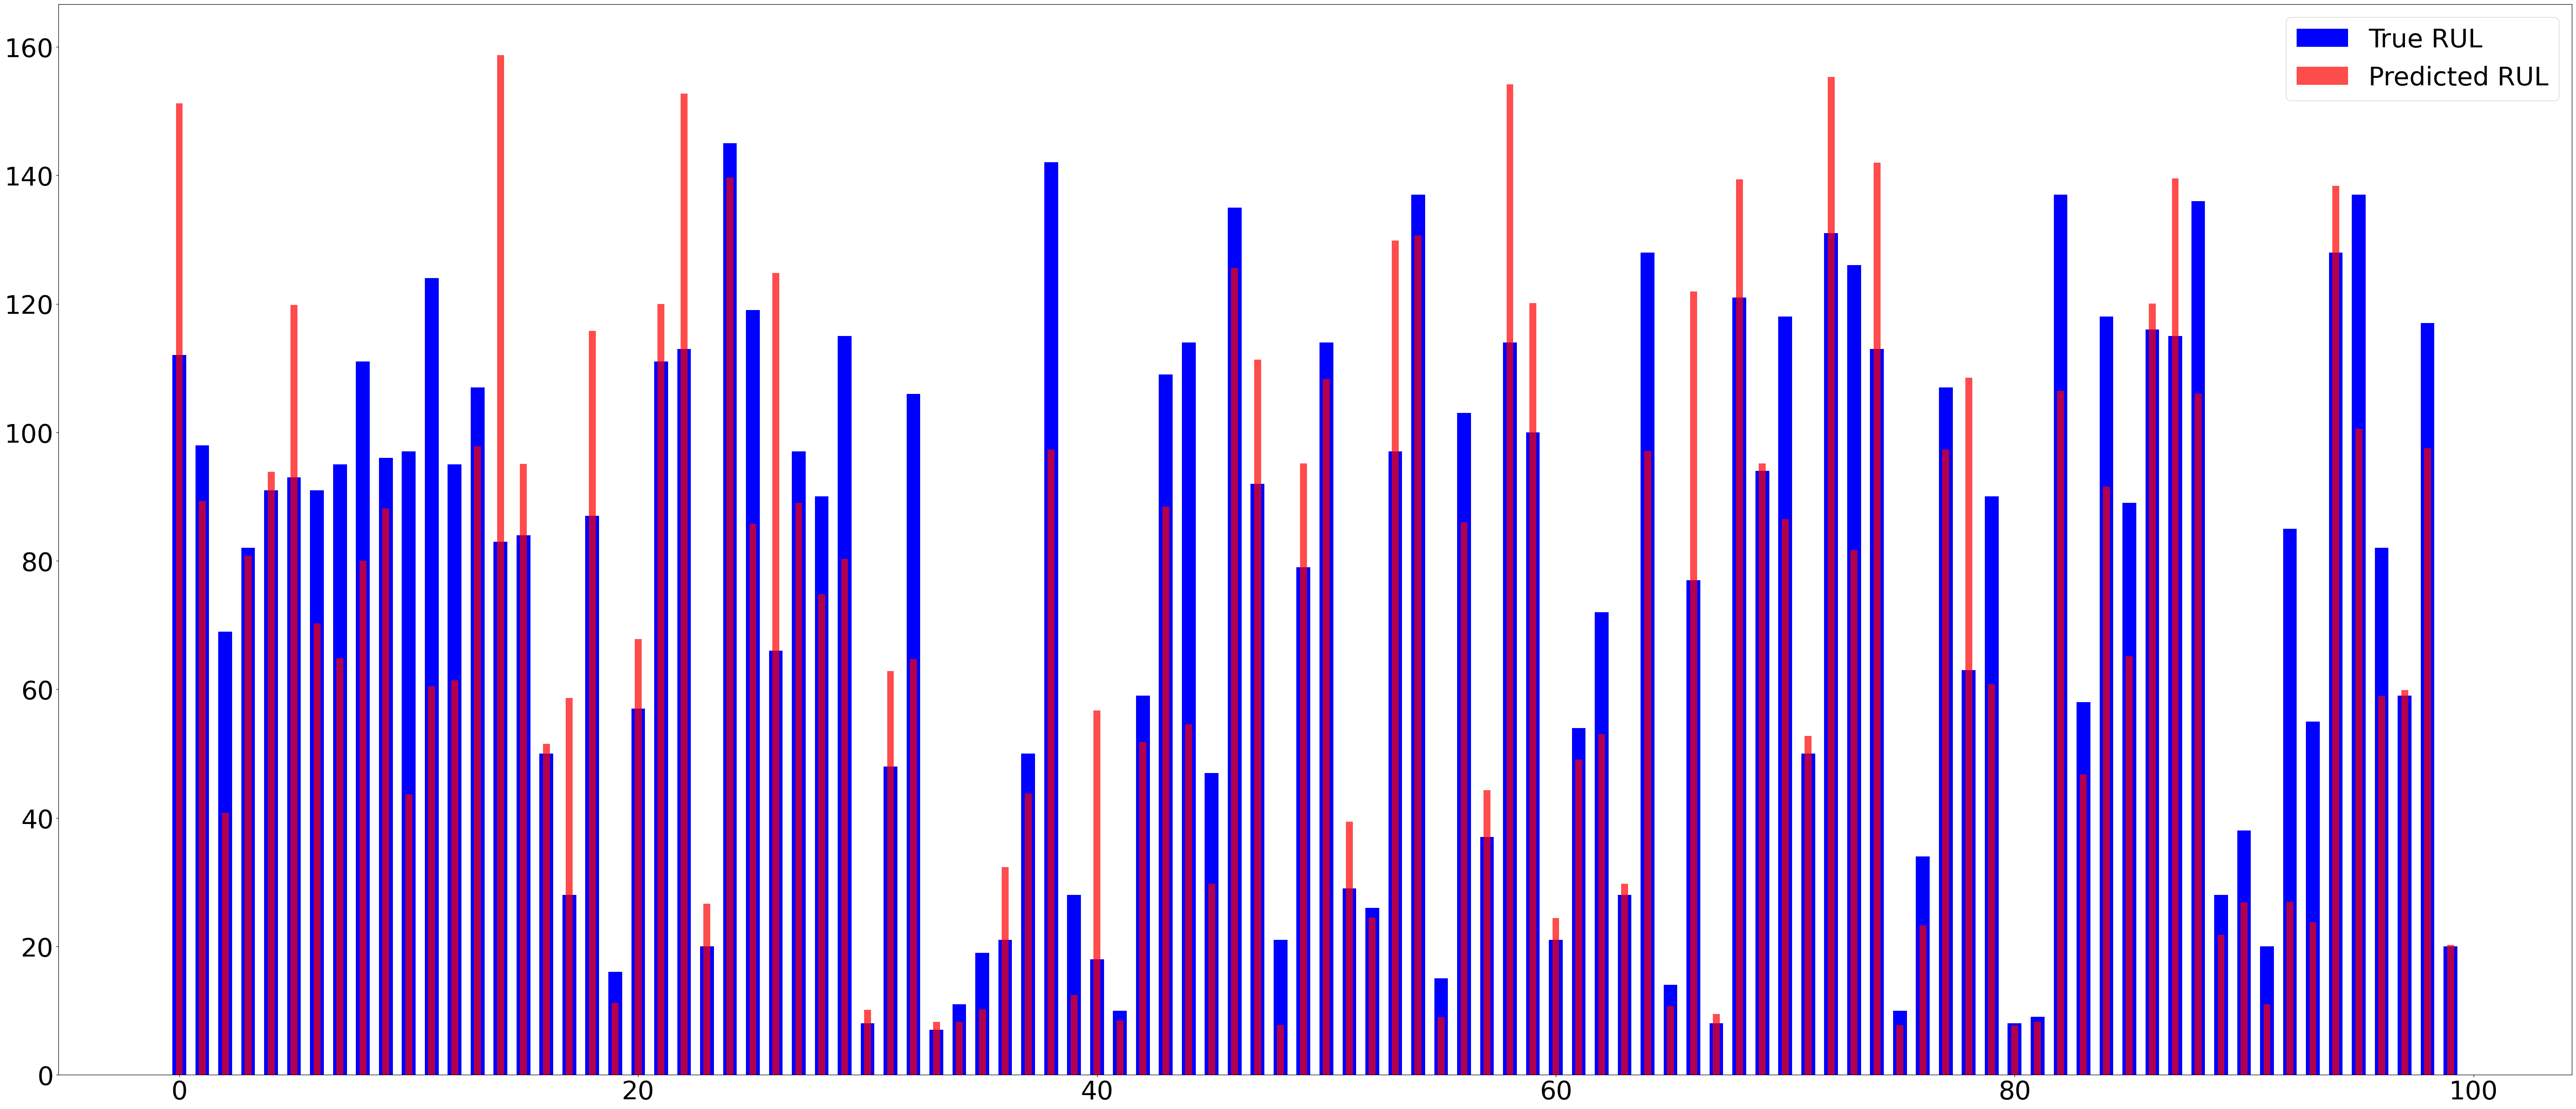

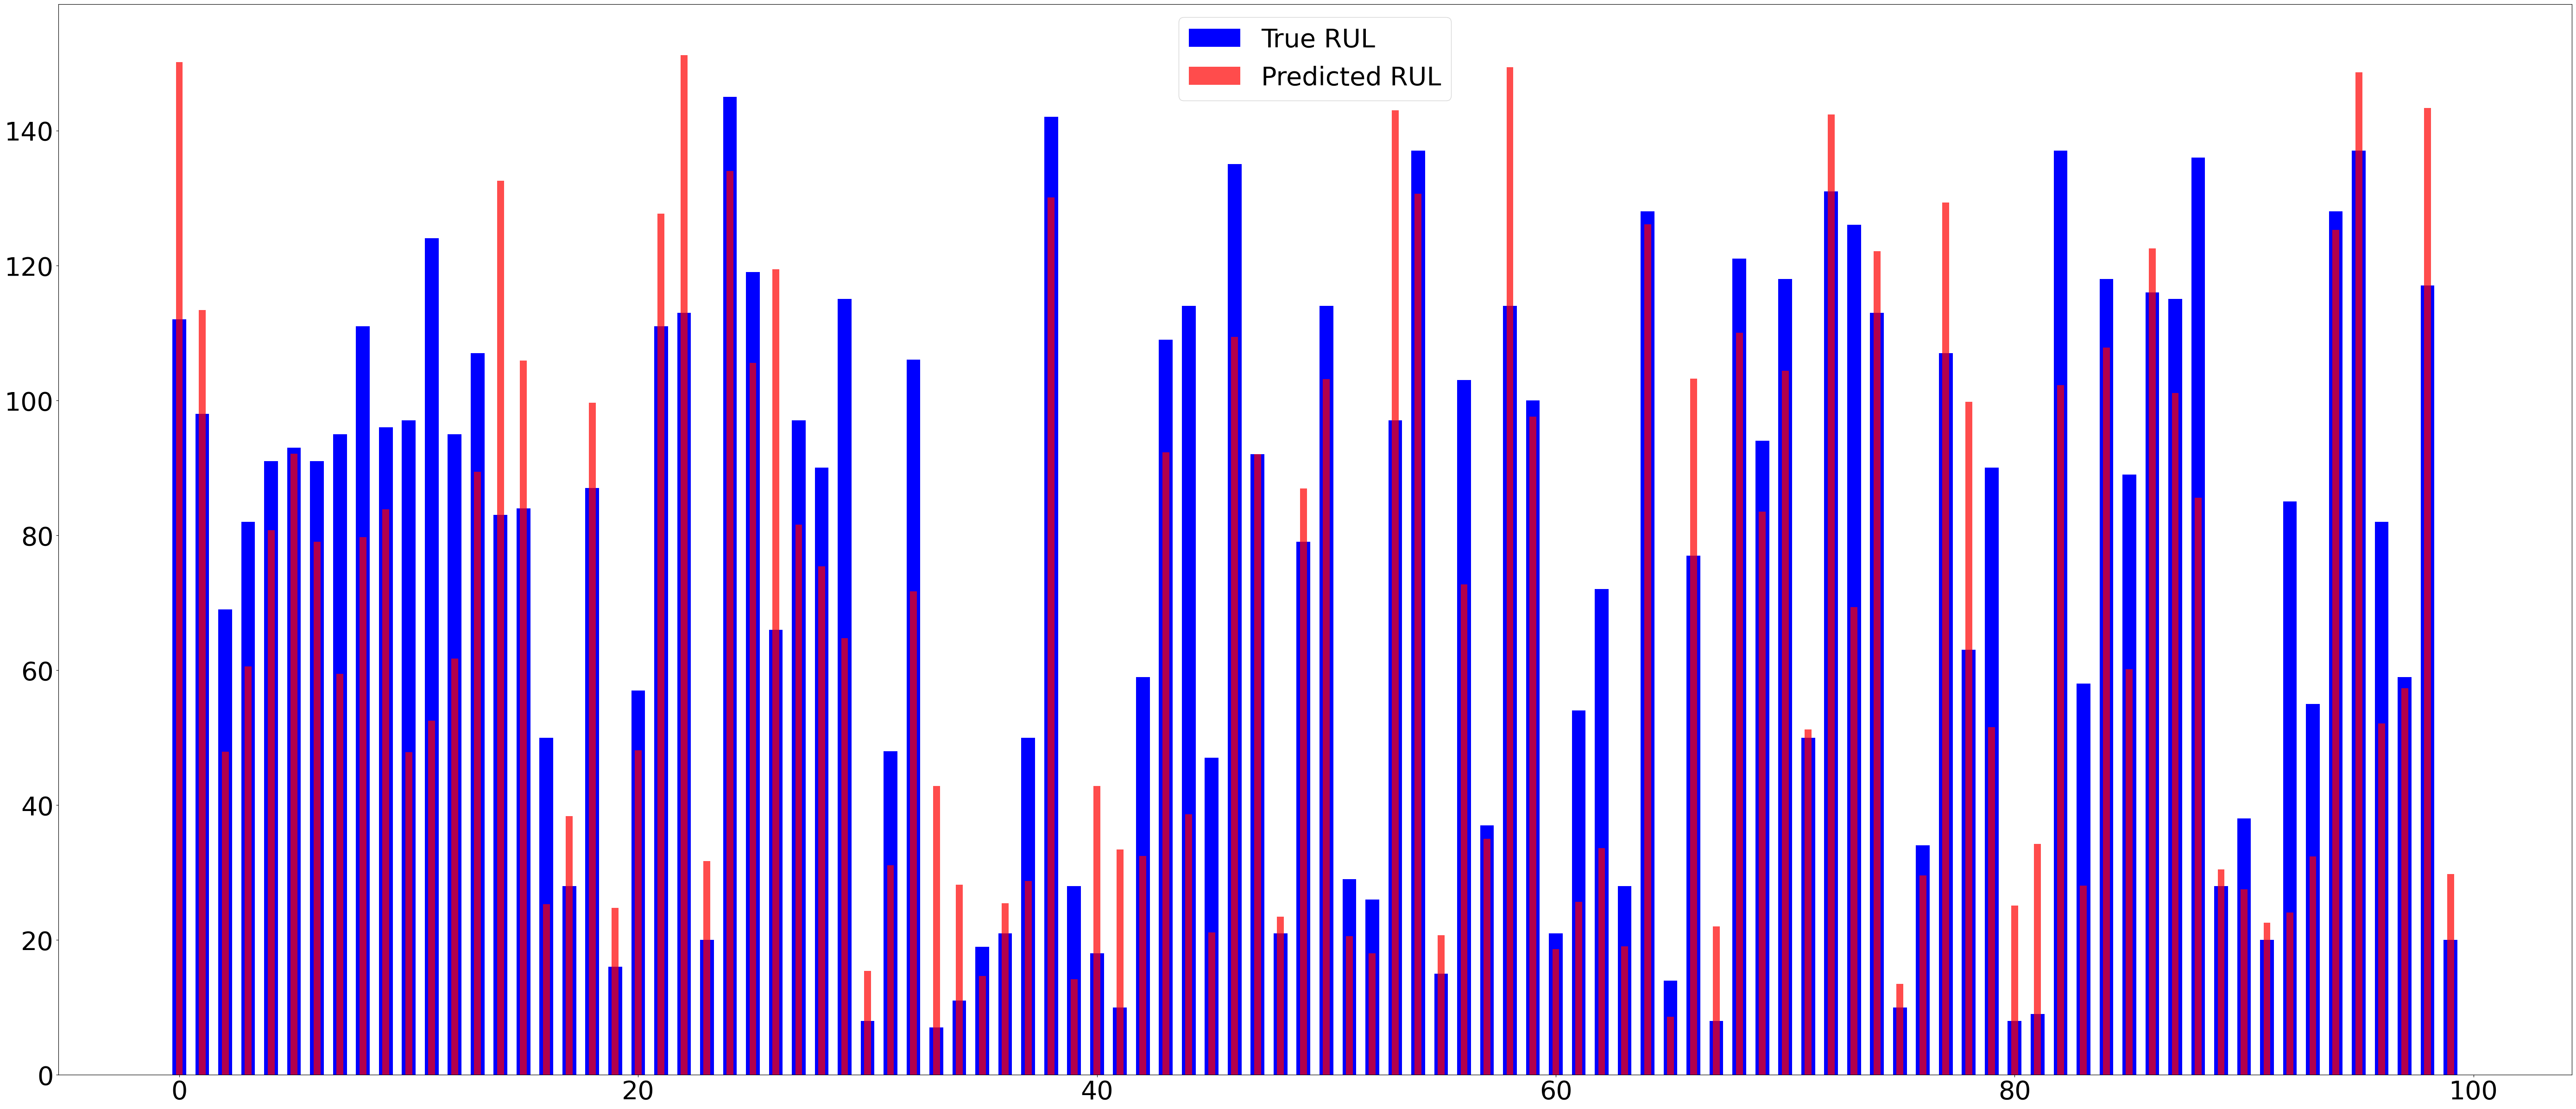

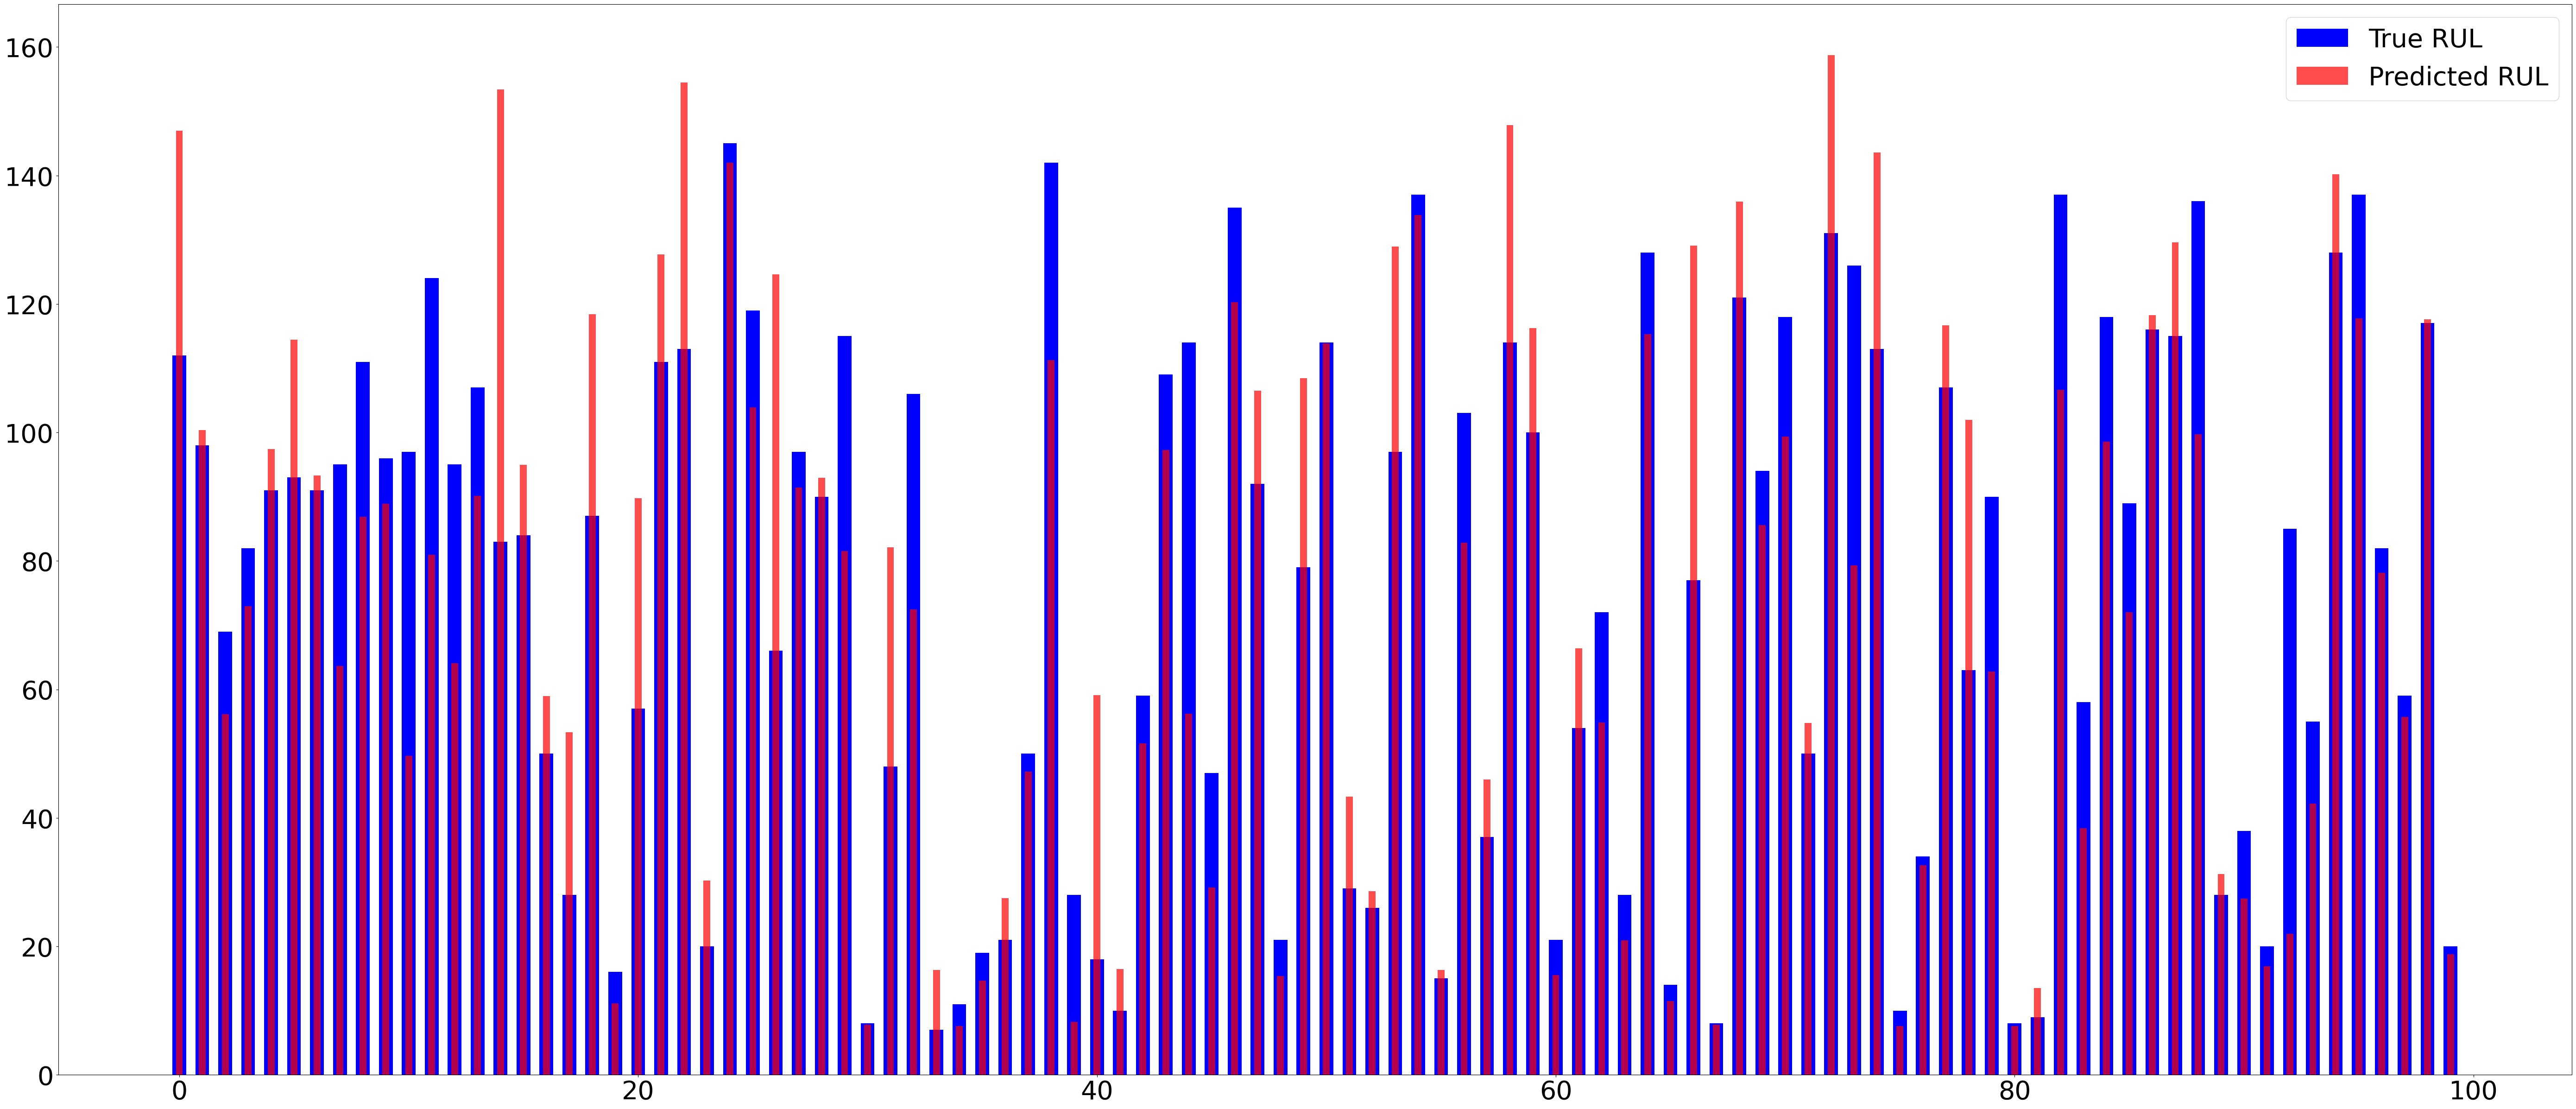

In [36]:
plot_predActual(y_valid, y_rf_valid)
plot_predActual(y_valid, y_svr_valid)
plot_predActual(y_valid, y_xgb_valid)

## 10. Phase 1 & 2 Summary — Key Observations

- **Phase 1 (all 21 sensors, no clipping):** Models struggle with noisy early-life samples where RUL is large; Random Forest and SVR outperform Linear Regression substantially on validation RMSE.
- **Phase 2 (14 sensors, RUL clipped at 195):** Removing constant sensors and clipping the target reduces overfitting and improves all models. XGBoost with strong regularisation is competitive with the tuned Random Forest.
- **General trend:** Tree-based ensemble methods generalise far better than the custom gradient-descent Linear Regression, which is limited by its fixed learning rate and iteration budget.

**Next:** Apply a 10-cycle rolling mean to sensor signals (Phase 3) to further reduce cycle-to-cycle noise and test whether smoother features yield better predictions.

## 11. Phase 3: Rolling Mean Feature Engineering

Each sensor reading is replaced with a **10-cycle rolling mean** computed per engine unit:
- Reduces high-frequency sensor noise while preserving the underlying degradation trend.
- For the first 10 cycles of each unit (insufficient lookback window), the raw sensor value is retained unchanged.
- The feature matrix retains the same 14 dimensions as Phase 2 but with smoother signals.

The rolling mean is computed using update_rolling_mean(), which groups data by unit_number and applies a rolling window in-place.

In [37]:
df=train.copy()
for x in X_train_2.columns:
    df[x+'_rm']=0

    
df.columns

Index(['unit_number', 'time_cycles', 'setting_1', 'setting_2', 'setting_3',
       's_1', 's_2', 's_3', 's_4', 's_5', 's_6', 's_7', 's_8', 's_9', 's_10',
       's_11', 's_12', 's_13', 's_14', 's_15', 's_16', 's_17', 's_18', 's_19',
       's_20', 's_21', 'RUL', 's_2_rm', 's_3_rm', 's_4_rm', 's_7_rm', 's_8_rm',
       's_9_rm', 's_11_rm', 's_12_rm', 's_13_rm', 's_14_rm', 's_15_rm',
       's_17_rm', 's_20_rm', 's_21_rm'],
      dtype='object')

In [38]:
df.head()

,unit_number,time_cycles,setting_1,setting_2,setting_3,s_1,s_2,s_3,s_4,s_5,...,s_8_rm,s_9_rm,s_11_rm,s_12_rm,s_13_rm,s_14_rm,s_15_rm,s_17_rm,s_20_rm,s_21_rm
0,1,1,-0.0007,-0.0004,100.0,518.67,641.82,1589.70,1400.60,14.62,...,0,0,0,0,0,0,0,0,0,0
1,1,2,0.0019,-0.0003,100.0,518.67,642.15,1591.82,1403.14,14.62,...,0,0,0,0,0,0,0,0,0,0
2,1,3,-0.0043,0.0003,100.0,518.67,642.35,1587.99,1404.20,14.62,...,0,0,0,0,0,0,0,0,0,0
3,1,4,0.0007,0.0000,100.0,518.67,642.35,1582.79,1401.87,14.62,...,0,0,0,0,0,0,0,0,0,0
4,1,5,-0.0019,-0.0002,100.0,518.67,642.37,1582.85,1406.22,14.62,...,0,0,0,0,0,0,0,0,0,0


In [39]:
drop_labels2=['s_1', 's_5','s_6','s_10',  's_16', 's_18', 's_19']
df=df.drop(columns=setting_names+drop_labels2+['RUL'], axis=1)

X_valid_3=valid.drop(columns=index_names+setting_names+drop_labels2, axis=1)

In [40]:
df.head()

,unit_number,time_cycles,s_2,s_3,s_4,s_7,s_8,s_9,s_11,s_12,...,s_8_rm,s_9_rm,s_11_rm,s_12_rm,s_13_rm,s_14_rm,s_15_rm,s_17_rm,s_20_rm,s_21_rm
0,1,1,641.82,1589.70,1400.60,554.36,2388.06,9046.19,47.47,521.66,...,0,0,0,0,0,0,0,0,0,0
1,1,2,642.15,1591.82,1403.14,553.75,2388.04,9044.07,47.49,522.28,...,0,0,0,0,0,0,0,0,0,0
2,1,3,642.35,1587.99,1404.20,554.26,2388.08,9052.94,47.27,522.42,...,0,0,0,0,0,0,0,0,0,0
3,1,4,642.35,1582.79,1401.87,554.45,2388.11,9049.48,47.13,522.86,...,0,0,0,0,0,0,0,0,0,0
4,1,5,642.37,1582.85,1406.22,554.00,2388.06,9055.15,47.28,522.19,...,0,0,0,0,0,0,0,0,0,0


In [41]:
def update_rolling_mean(data, mask):
    for x, group in mask.groupby("unit_number"):
        for x in X_train_2.columns:
            data.loc[group.index[10:], x+"_rm"] = data.loc[group.index, x].rolling(10).mean()[10:]
            data.loc[group.index[:10], x+"_rm"] = data.loc[group.index[:10], x]

update_rolling_mean(df, df)
update_rolling_mean(X_valid_3, valid)

X_valid_3=X_valid_3.fillna(0)

In [42]:
df.head(20)

,unit_number,time_cycles,s_2,s_3,s_4,s_7,s_8,s_9,s_11,s_12,...,s_8_rm,s_9_rm,s_11_rm,s_12_rm,s_13_rm,s_14_rm,s_15_rm,s_17_rm,s_20_rm,s_21_rm
0,1,1,641.82,1589.70,1400.60,554.36,2388.06,9046.19,47.47,521.66,...,2388.060,9046.190,47.470,521.660,2388.020,8138.620,8.41950,392.0,39.060,23.41900
1,1,2,642.15,1591.82,1403.14,553.75,2388.04,9044.07,47.49,522.28,...,2388.040,9044.070,47.490,522.280,2388.070,8131.490,8.43180,392.0,39.000,23.42360
2,1,3,642.35,1587.99,1404.20,554.26,2388.08,9052.94,47.27,522.42,...,2388.080,9052.940,47.270,522.420,2388.030,8133.230,8.41780,390.0,38.950,23.34420
3,1,4,642.35,1582.79,1401.87,554.45,2388.11,9049.48,47.13,522.86,...,2388.110,9049.480,47.130,522.860,2388.080,8133.830,8.36820,392.0,38.880,23.37390
4,1,5,642.37,1582.85,1406.22,554.00,2388.06,9055.15,47.28,522.19,...,2388.060,9055.150,47.280,522.190,2388.040,8133.800,8.42940,393.0,38.900,23.40440
5,1,6,642.10,1584.47,1398.37,554.67,2388.02,9049.68,47.16,521.68,...,2388.020,9049.680,47.160,521.680,2388.030,8132.850,8.41080,391.0,38.980,23.36690
6,1,7,642.48,1592.32,1397.77,554.34,2388.02,9059.13,47.36,522.32,...,2388.020,9059.130,47.360,522.320,2388.030,8132.320,8.39740,392.0,39.100,23.37740
7,1,8,642.56,1582.96,1400.97,553.85,2388.00,9040.80,47.24,522.47,...,2388.000,9040.800,47.240,522.470,2388.030,8131.070,8.40760,391.0,38.970,23.31060
8,1,9,642.12,1590.98,1394.80,553.69,2388.05,9046.46,47.29,521.79,...,2388.050,9046.460,47.290,521.790,2388.050,8125.690,8.37280,392.0,39.050,23.40660
9,1,10,641.71,1591.24,1400.46,553.59,2388.05,9051.70,47.03,521.79,...,2388.050,9051.700,47.030,521.790,2388.060,8129.380,8.42860,393.0,38.950,23.46940


In [43]:
train_tm=df

In [44]:
train_tm=train_tm.drop(columns=index_names, axis=1)

In [45]:
X_train_tm, X_test_tm, y_train_tm, y_test_tm=train_test_split(train_tm,train['RUL'].clip(upper=195), test_size=0.35, random_state=42)
X_train_tm_s=scaler.fit_transform(X_train_tm)
X_test_tm_s=scaler.fit_transform(X_test_tm)
X_val3=pd.concat([valid['unit_number'],X_valid_3],axis=1)
X_valid3 = X_val3.groupby('unit_number').last().reset_index().drop(columns=['unit_number'])
X_valid_s=scaler.fit_transform(X_valid3)

In [46]:
dftm= pd.concat([train['unit_number'],train_tm,train['RUL']],axis=1)
dftm

,unit_number,s_2,s_3,s_4,s_7,s_8,s_9,s_11,s_12,s_13,...,s_9_rm,s_11_rm,s_12_rm,s_13_rm,s_14_rm,s_15_rm,s_17_rm,s_20_rm,s_21_rm,RUL
0,1,641.82,1589.70,1400.60,554.36,2388.06,9046.19,47.47,521.66,2388.02,...,9046.190,47.470,521.660,2388.020,8138.620,8.41950,392.0,39.060,23.41900,191
1,1,642.15,1591.82,1403.14,553.75,2388.04,9044.07,47.49,522.28,2388.07,...,9044.070,47.490,522.280,2388.070,8131.490,8.43180,392.0,39.000,23.42360,190
2,1,642.35,1587.99,1404.20,554.26,2388.08,9052.94,47.27,522.42,2388.03,...,9052.940,47.270,522.420,2388.030,8133.230,8.41780,390.0,38.950,23.34420,189
3,1,642.35,1582.79,1401.87,554.45,2388.11,9049.48,47.13,522.86,2388.08,...,9049.480,47.130,522.860,2388.080,8133.830,8.36820,392.0,38.880,23.37390,188
4,1,642.37,1582.85,1406.22,554.00,2388.06,9055.15,47.28,522.19,2388.04,...,9055.150,47.280,522.190,2388.040,8133.800,8.42940,393.0,38.900,23.40440,187
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
20626,100,643.49,1597.98,1428.63,551.43,2388.19,9065.52,48.07,519.49,2388.26,...,9066.903,48.116,519.840,2388.237,8141.170,8.51031,396.0,38.453,23.09254,4
20627,100,643.54,1604.50,1433.58,550.86,2388.23,9065.11,48.04,519.68,2388.22,...,9066.820,48.116,519.793,2388.237,8140.771,8.51083,395.9,38.416,23.08540,3
20628,100,643.42,1602.46,1428.18,550.94,2388.24,9065.90,48.09,520.01,2388.24,...,9066.642,48.096,519.796,2388.240,8140.882,8.51915,396.2,38.424,23.07321,2
20629,100,643.23,1605.26,1426.53,550.68,2388.25,9073.72,48.39,519.67,2388.23,...,9067.045,48.136,519.813,2388.239,8140.833,8.52434,396.0,38.388,23.07370,1


### Rolling Mean Sensor Signal Visualization

Sensor signals are plotted after rolling-mean smoothing to confirm noise reduction. The smoother trends should correlate more cleanly with RUL compared to the noisy raw signals shown in Section 3.

In [47]:
def plot_signal(df, signal_name):
    plt.figure(figsize=(13,5))
    for i in df['unit_number'].unique():
        if (i % 10 == 0):  
            plt.plot('RUL', signal_name, data=df[df['unit_number']==i].rolling(8).mean())

    plt.ylabel(signal_name)
    plt.xlabel('Remaining Useful Life')
    plt.show()

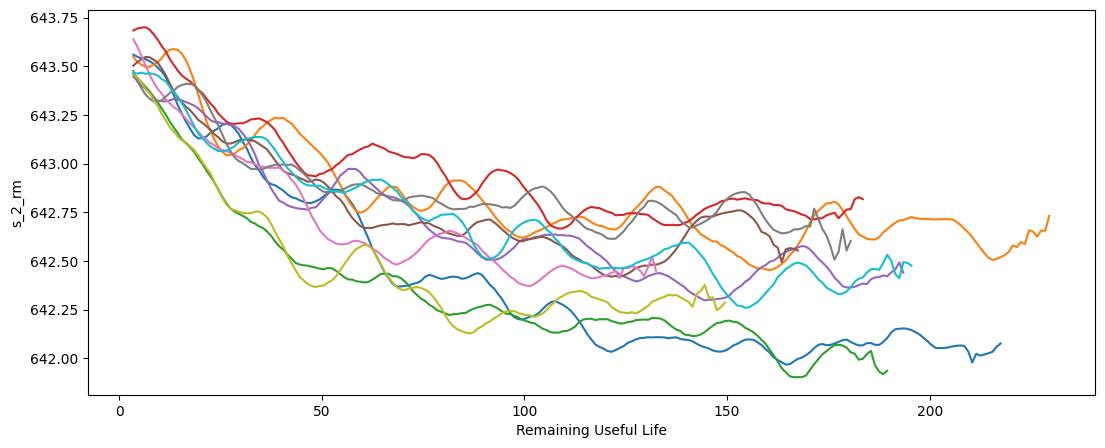

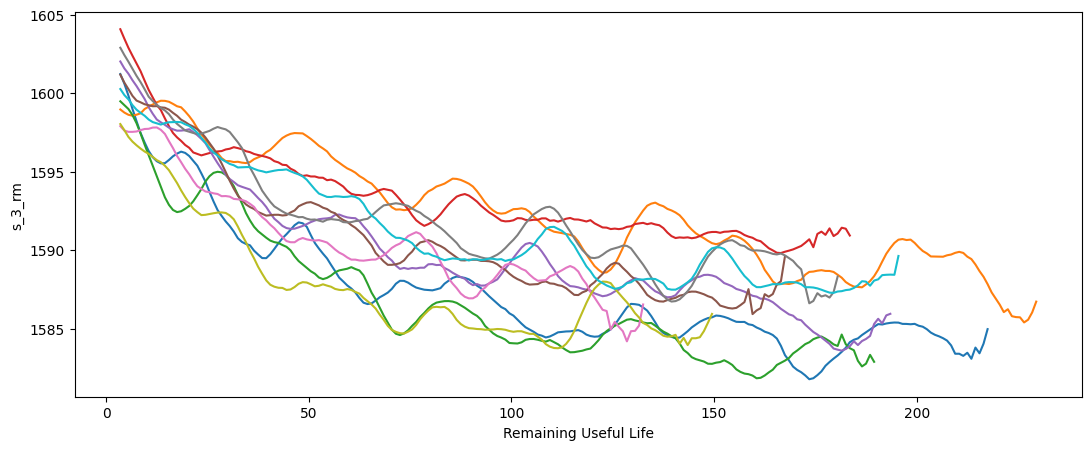

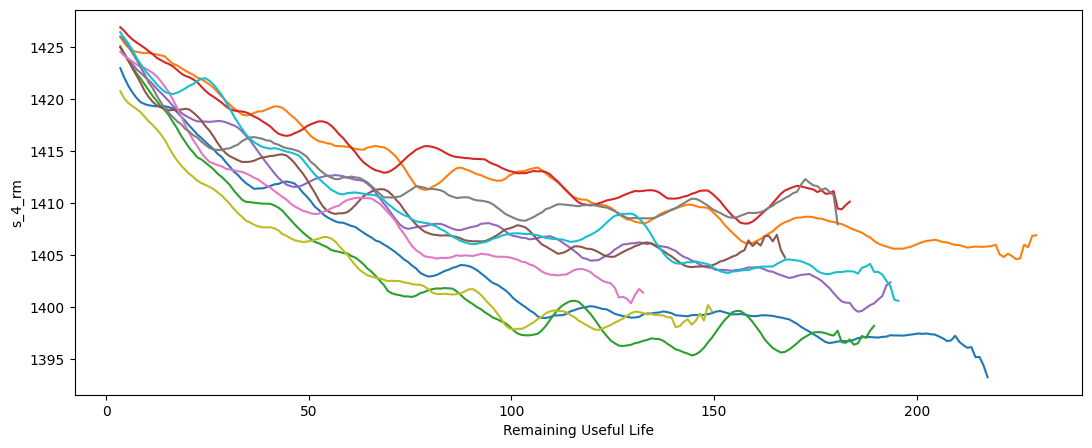

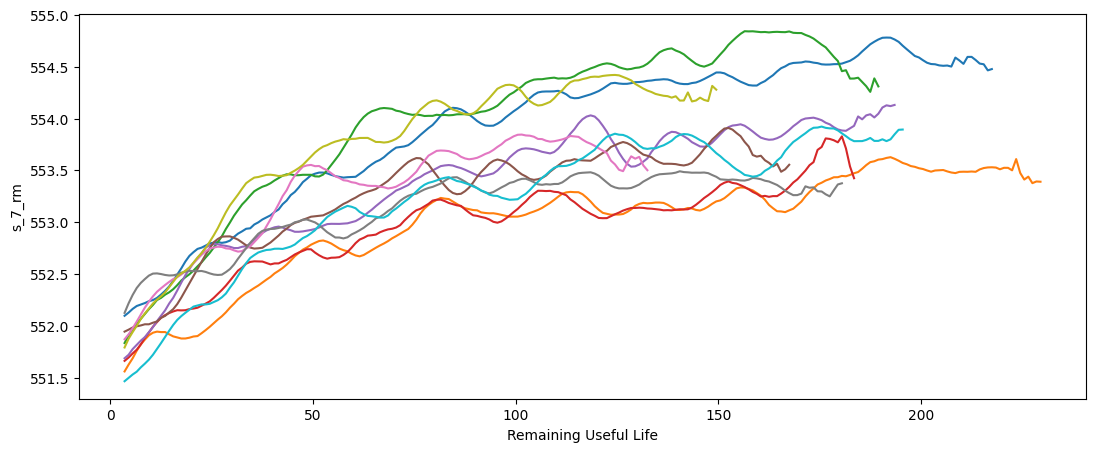

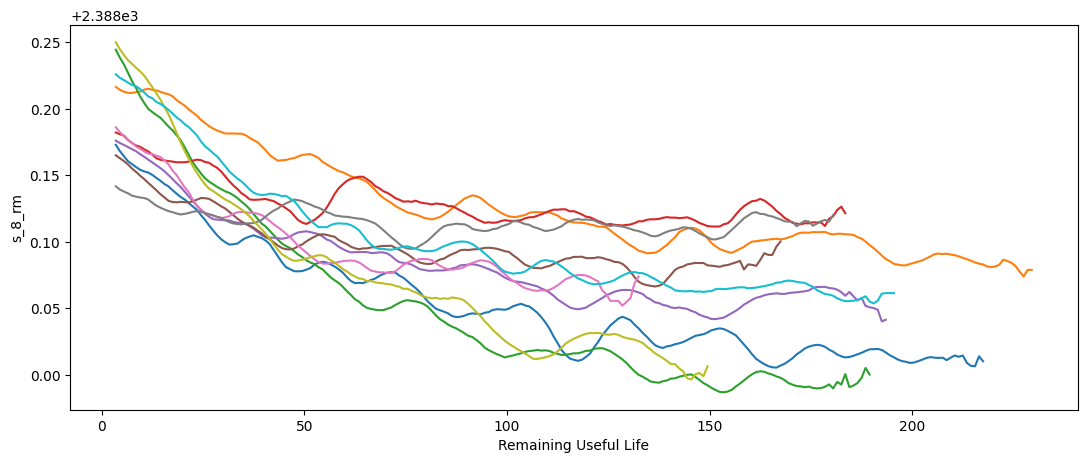

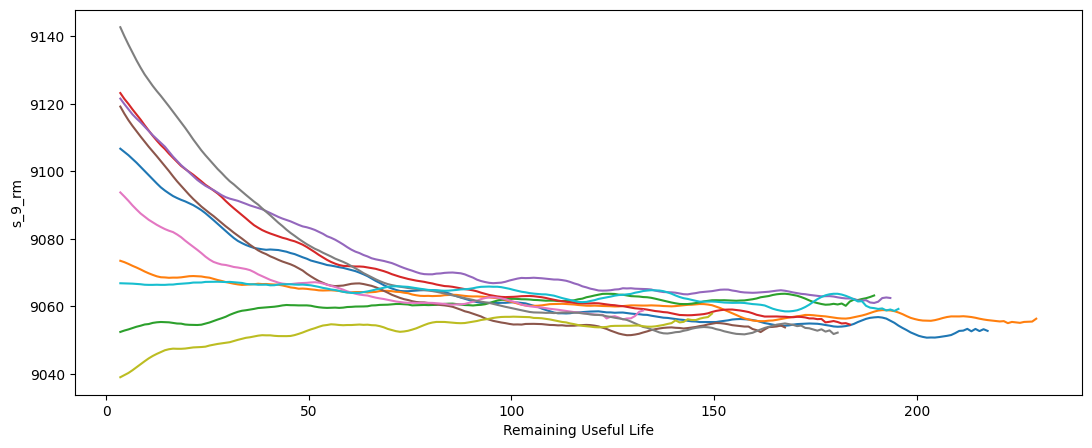

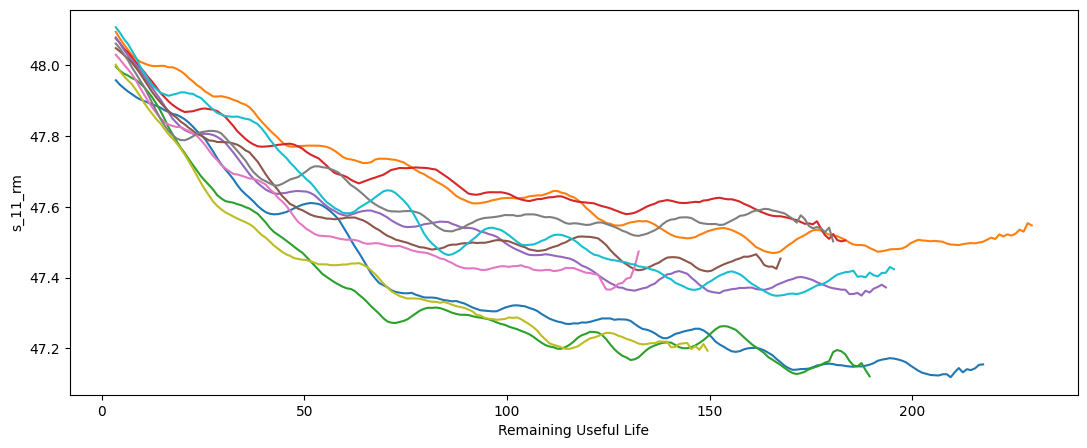

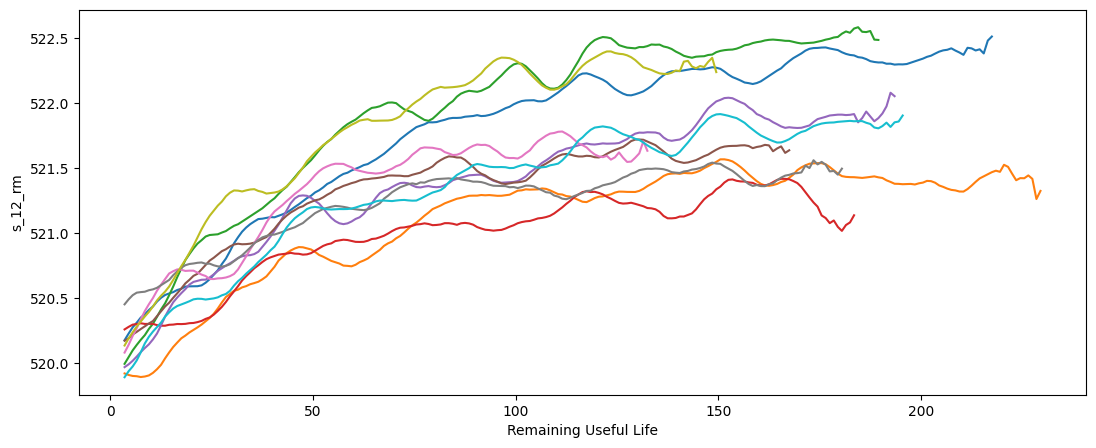

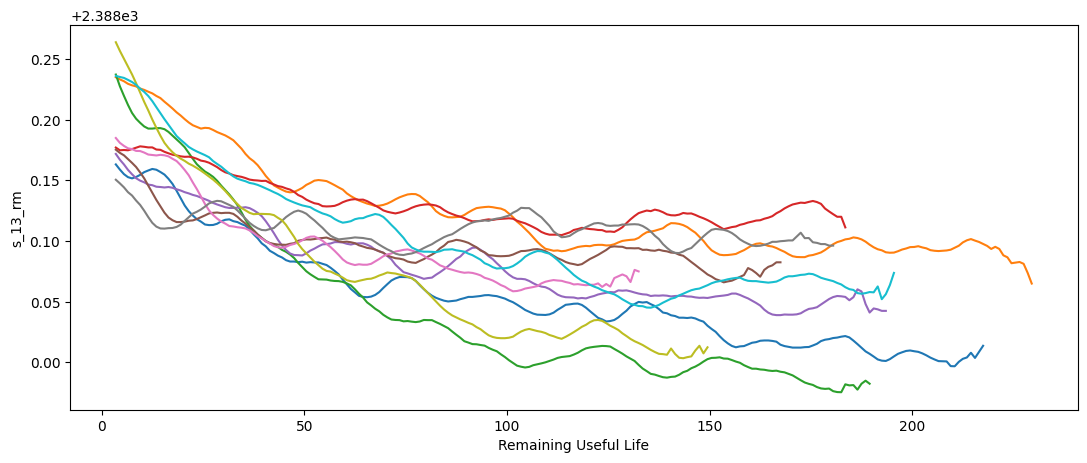

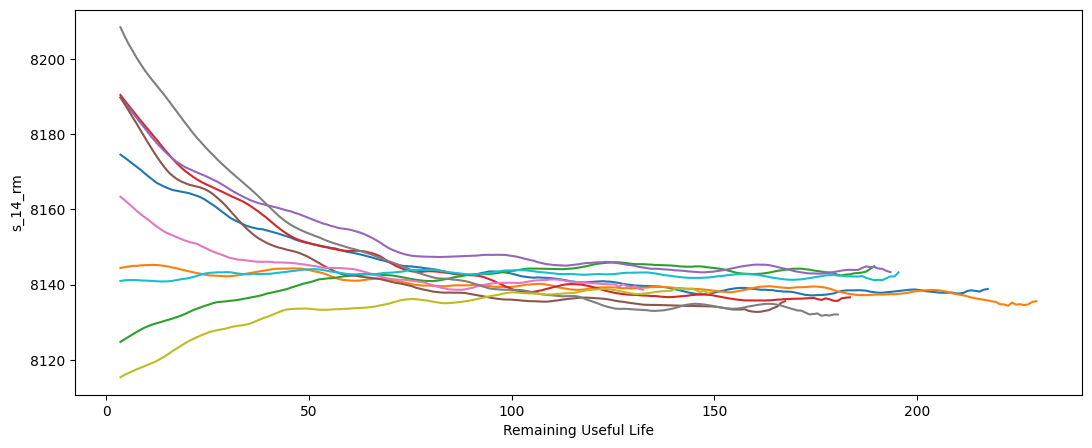

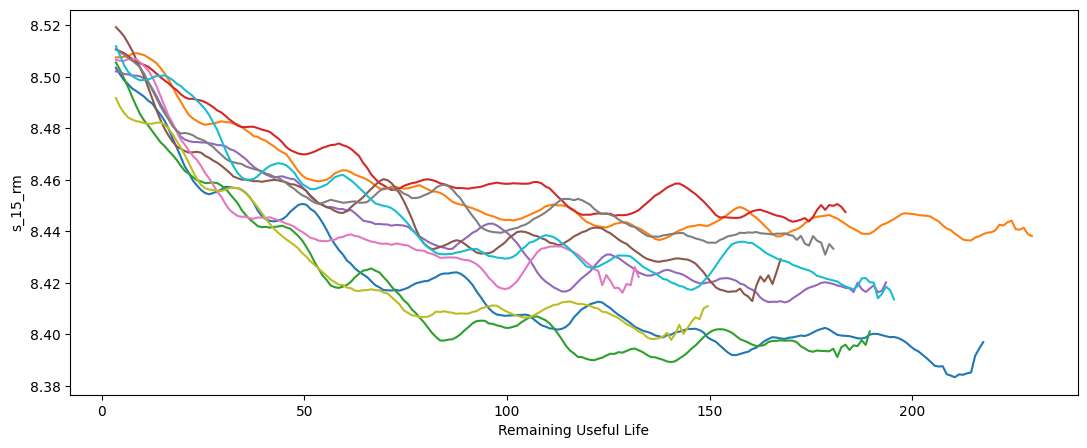

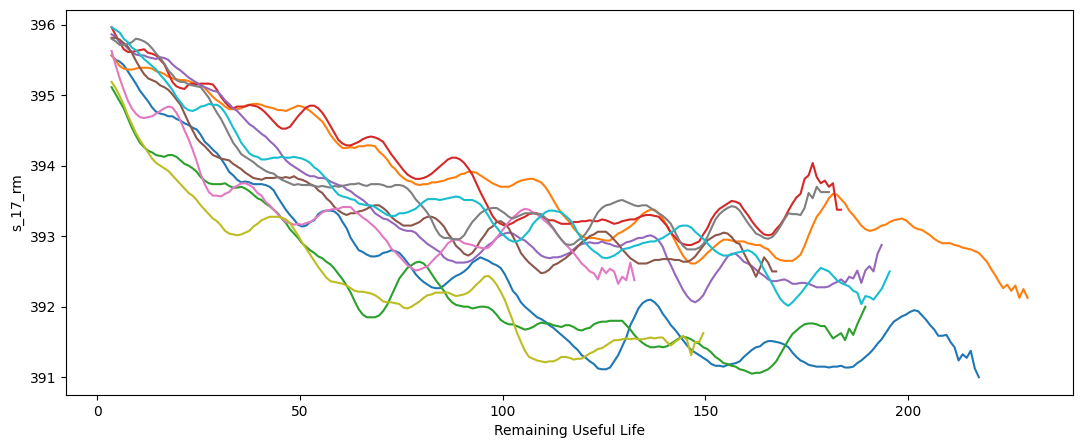

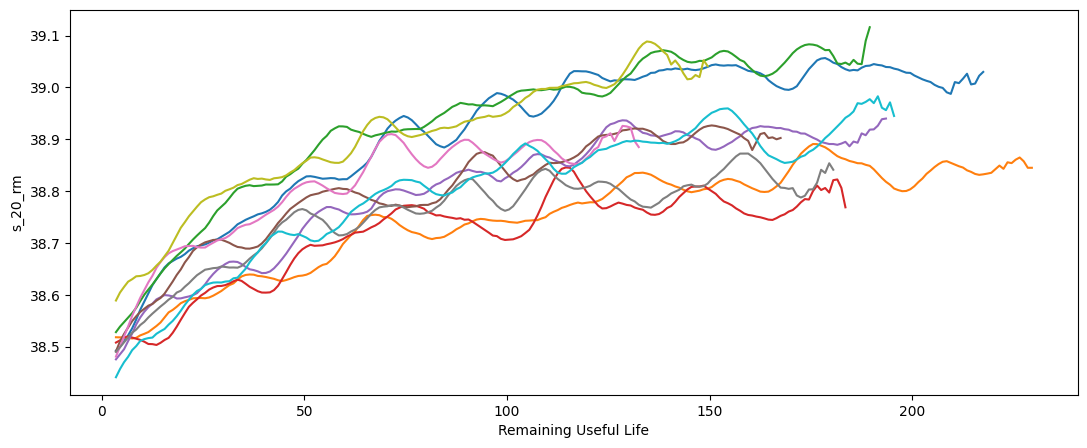

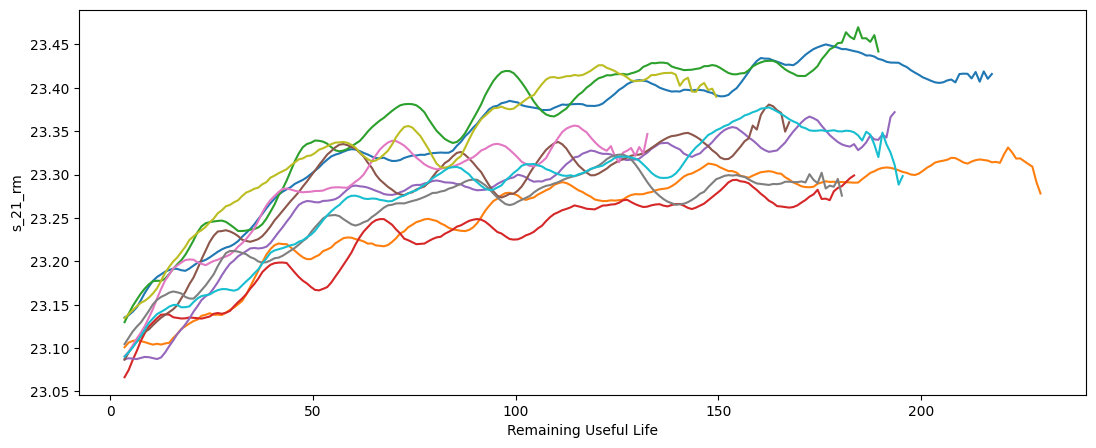

In [48]:
for i in range(1,22):
     if i not in [1,5,6,10,16,18,19] :
        try:
            plot_signal(dftm, 's_'+str(i)+'_rm')
        except:
            pass

## 12. Phase 3: Model Training with Rolling Mean Features

The same four models (Linear Regression, SVR, Random Forest, XGBoost) are re-trained on the rolling-mean feature set using identical hyperparameters to Phase 2. The hypothesis is that smoother, less noisy input signals improve prediction accuracy — particularly for linear models and SVR.

**Reported error metrics: RMSE and R² on train, internal test, and validation sets.**

In [49]:
# --- Linear Regression with Rolling Mean ---
lr = Linear_Regression()
lr.fit(X=X_train_tm_s, Y=y_train_tm)

y_lr_train = lr.predict(X_train_tm_s)
evaluate(y_train_tm, y_lr_train, label='train')

y_lr_test = lr.predict(X_test_tm_s)
evaluate(y_test_tm, y_lr_test, label='test')

y_lr_valid = lr.predict(X_valid_s)
evaluate(y_valid, y_lr_valid, label='valid')

train set RMSE:40.529124801409225, R2:0.5544983519999881
test set RMSE:40.09893732905365, R2:0.5545324875936375
valid set RMSE:38.37340578135016, R2:0.14729040845923846


In [50]:
# --- SVR with Rolling Mean ---
regressor = SVR(kernel='rbf')
regressor.fit(X_train_tm_s, y_train_tm)

y_svr_train = regressor.predict(X_train_tm_s)
evaluate(y_train_tm, y_svr_train, label='train')

y_svr_test = regressor.predict(X_test_tm_s)
evaluate(y_test_tm, y_svr_test, label='test')

y_svr_valid = regressor.predict(X_valid_s)
evaluate(y_valid, y_svr_valid, label='valid')

train set RMSE:32.48451160933286, R2:0.713801372146734
test set RMSE:33.828645374092, R2:0.6829560102536554
valid set RMSE:26.647585124781525, R2:0.5887970967915135


In [51]:
# --- Random Forest with Rolling Mean ---
rf = RandomForestRegressor(max_features=0.3, random_state=42, max_depth=5, min_samples_leaf=50, min_samples_split=100, n_estimators=200, max_samples=0.7)
rf.fit(X_train_tm_s, y_train_tm)

y_rf_train = rf.predict(X_train_tm_s)
evaluate(y_train_tm, y_rf_train, label='train')

y_rf_test = rf.predict(X_test_tm_s)
evaluate(y_test_tm, y_rf_test, label='test')

y_rf_valid = rf.predict(X_valid_s)
evaluate(y_valid, y_rf_valid, label='valid')

train set RMSE:31.346979018836922, R2:0.7334944545592936
test set RMSE:32.735467268644285, R2:0.7031155856947663
valid set RMSE:37.40678894960729, R2:0.18970844149409882


In [52]:
# --- XGBoost with Rolling Mean ---
import xgboost
xgb = xgboost.XGBRegressor(n_estimators=200, learning_rate=0.02, gamma=3, subsample=0.6, colsample_bytree=0.4, max_depth=2, reg_alpha=1, reg_lambda=5, min_child_weight=15)
xgb.fit(X_train_tm_s, y_train_tm)

y_xgb_train = xgb.predict(X_train_tm_s)
evaluate(y_train_tm, y_xgb_train, label='train')

y_xgb_test = xgb.predict(X_test_tm_s)
evaluate(y_test_tm, y_xgb_test, label='test')

y_xgb_valid = xgb.predict(X_valid_s)
evaluate(y_valid, y_xgb_valid, label='valid')

train set RMSE:32.2126797749155, R2:0.7185711860656738
test set RMSE:33.73099146417505, R2:0.6847838163375854
valid set RMSE:35.583194014717996, R2:0.26678669452667236


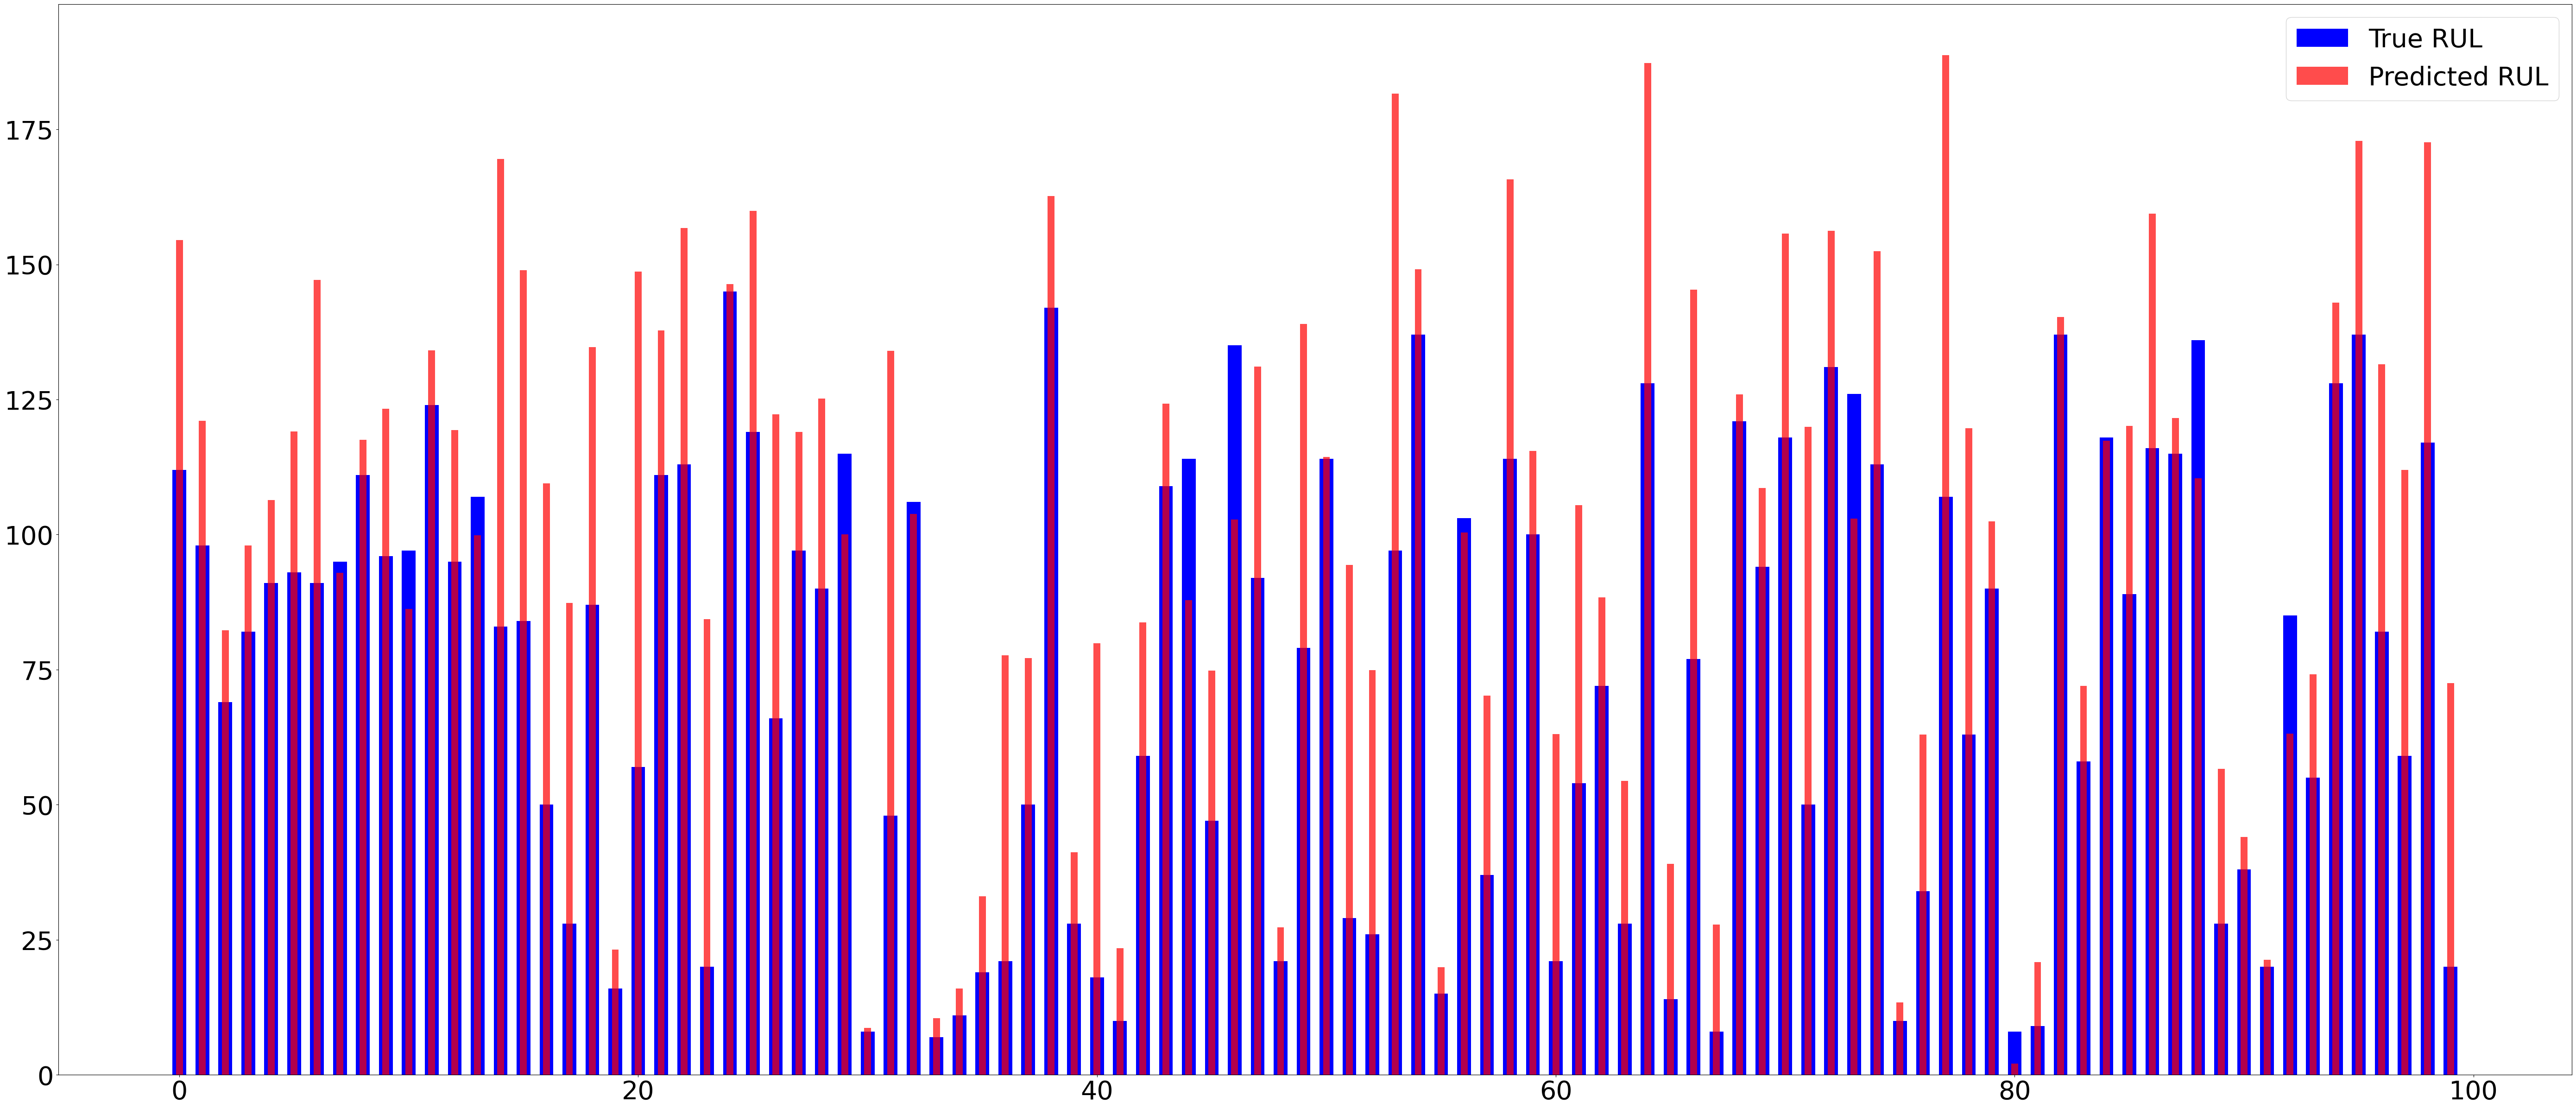

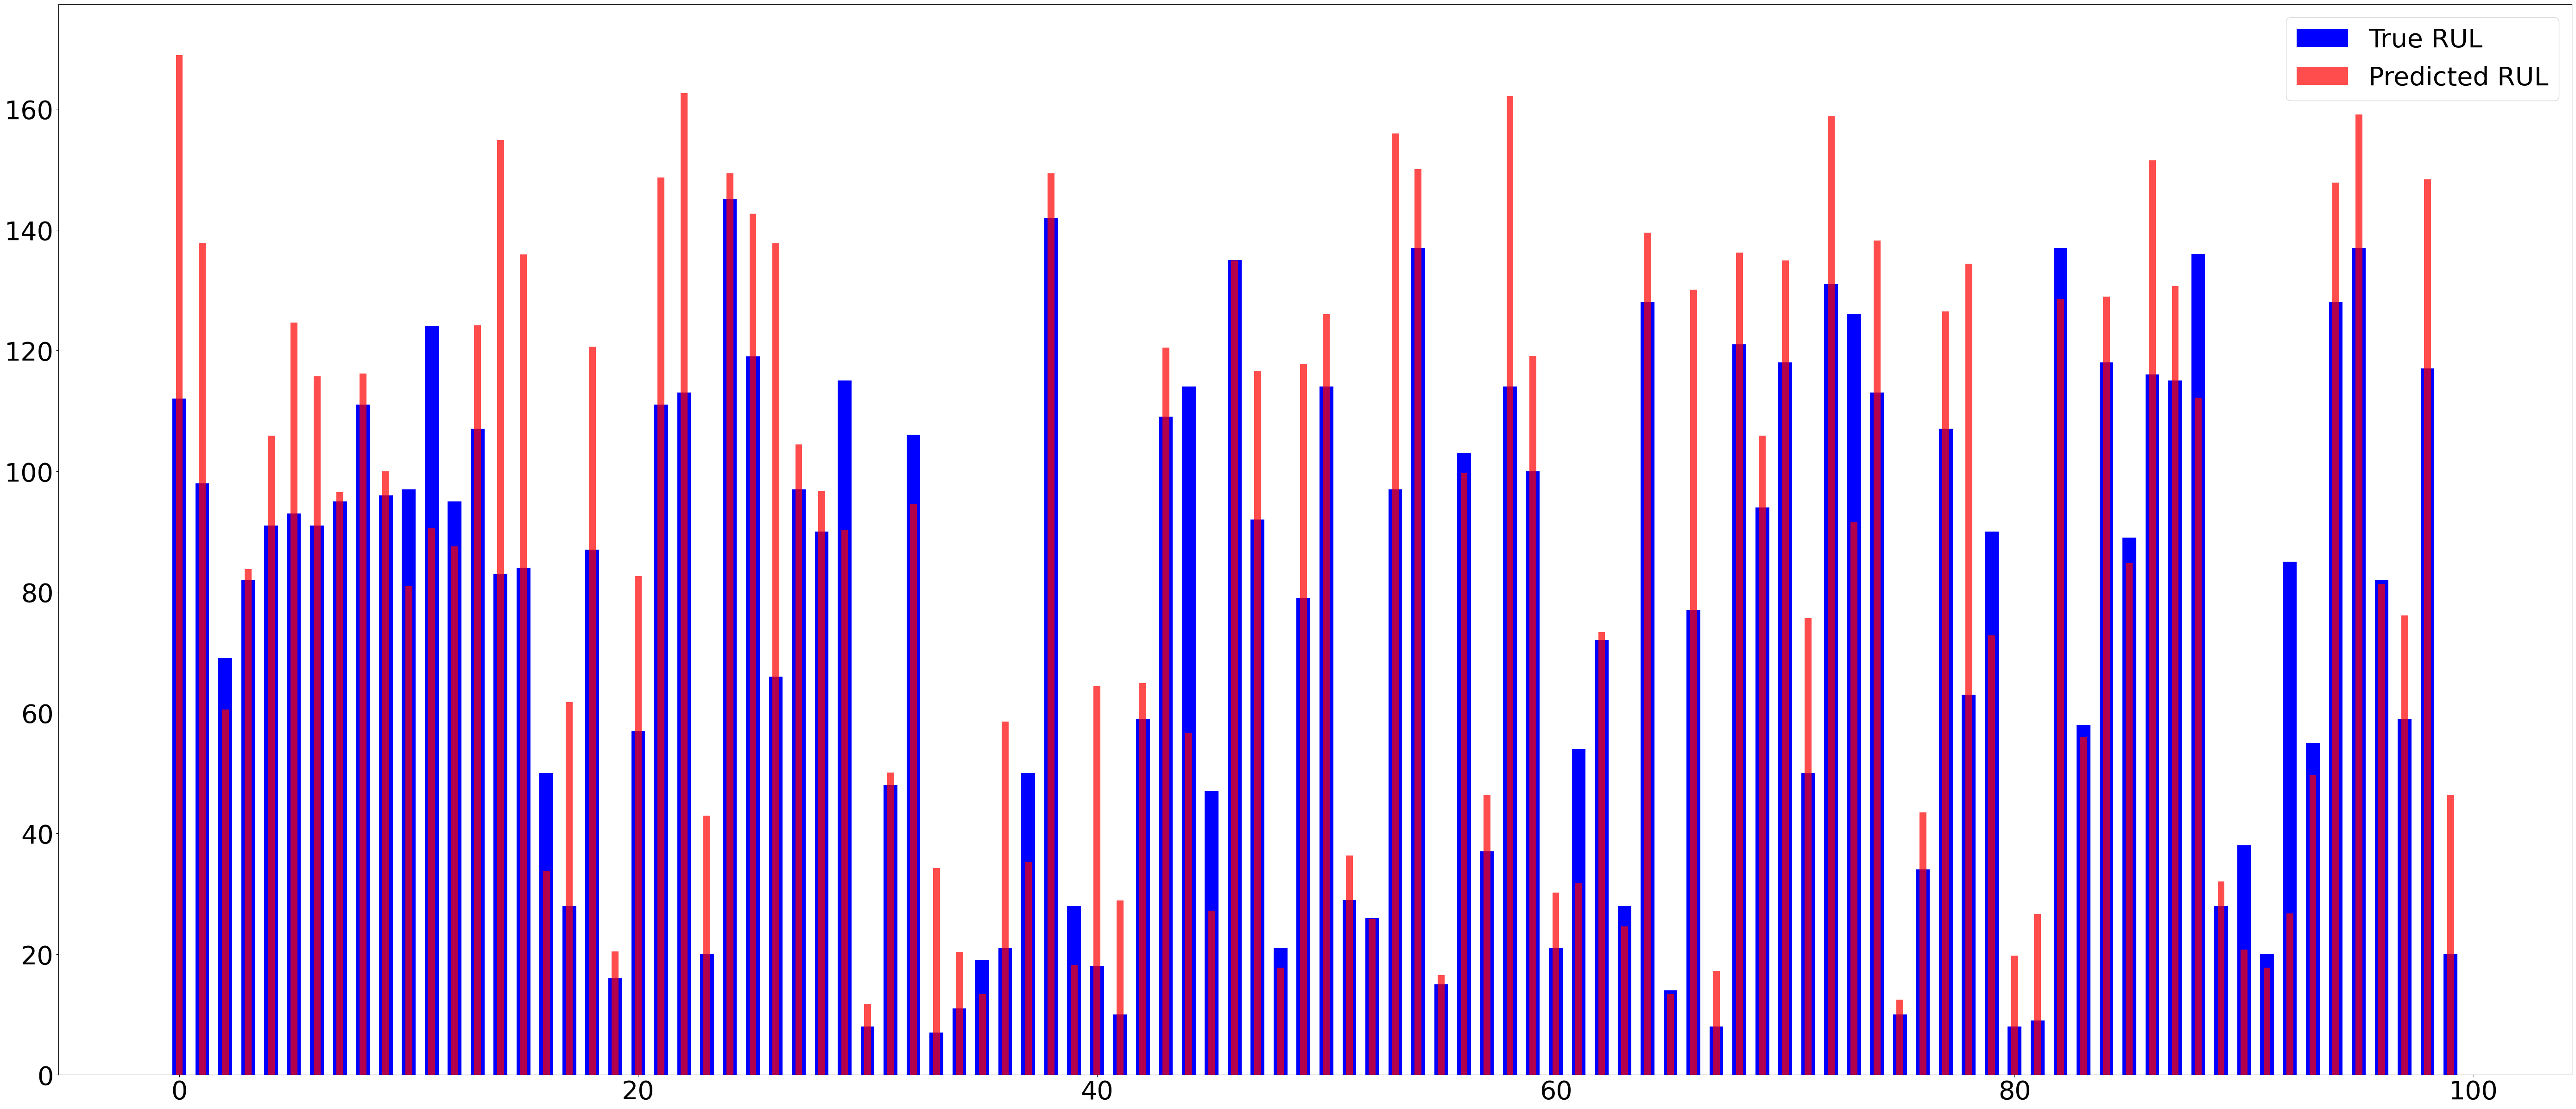

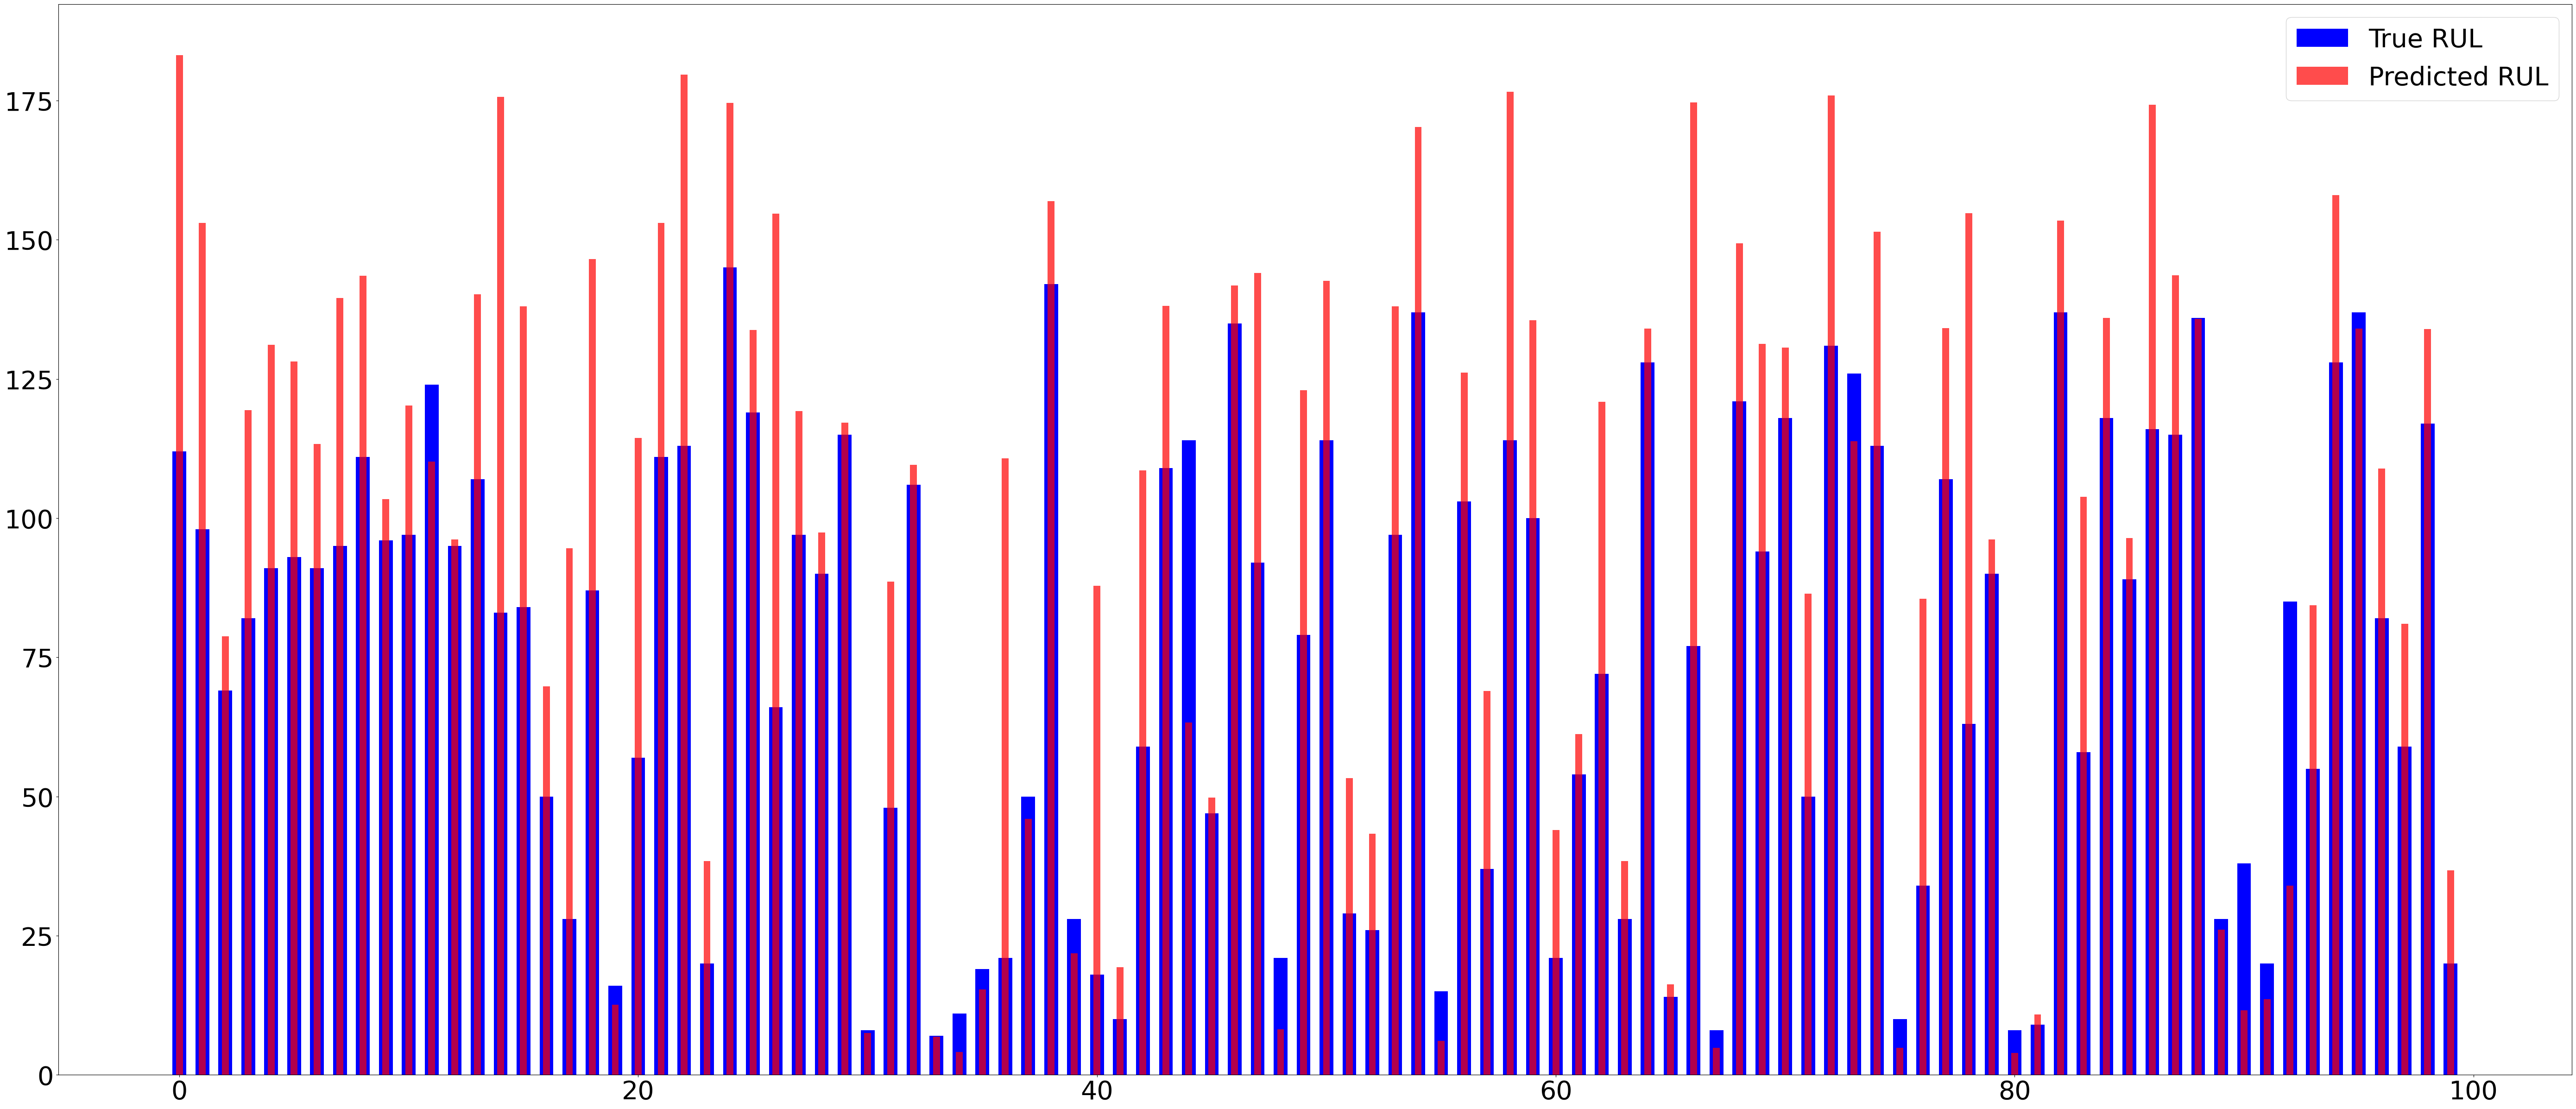

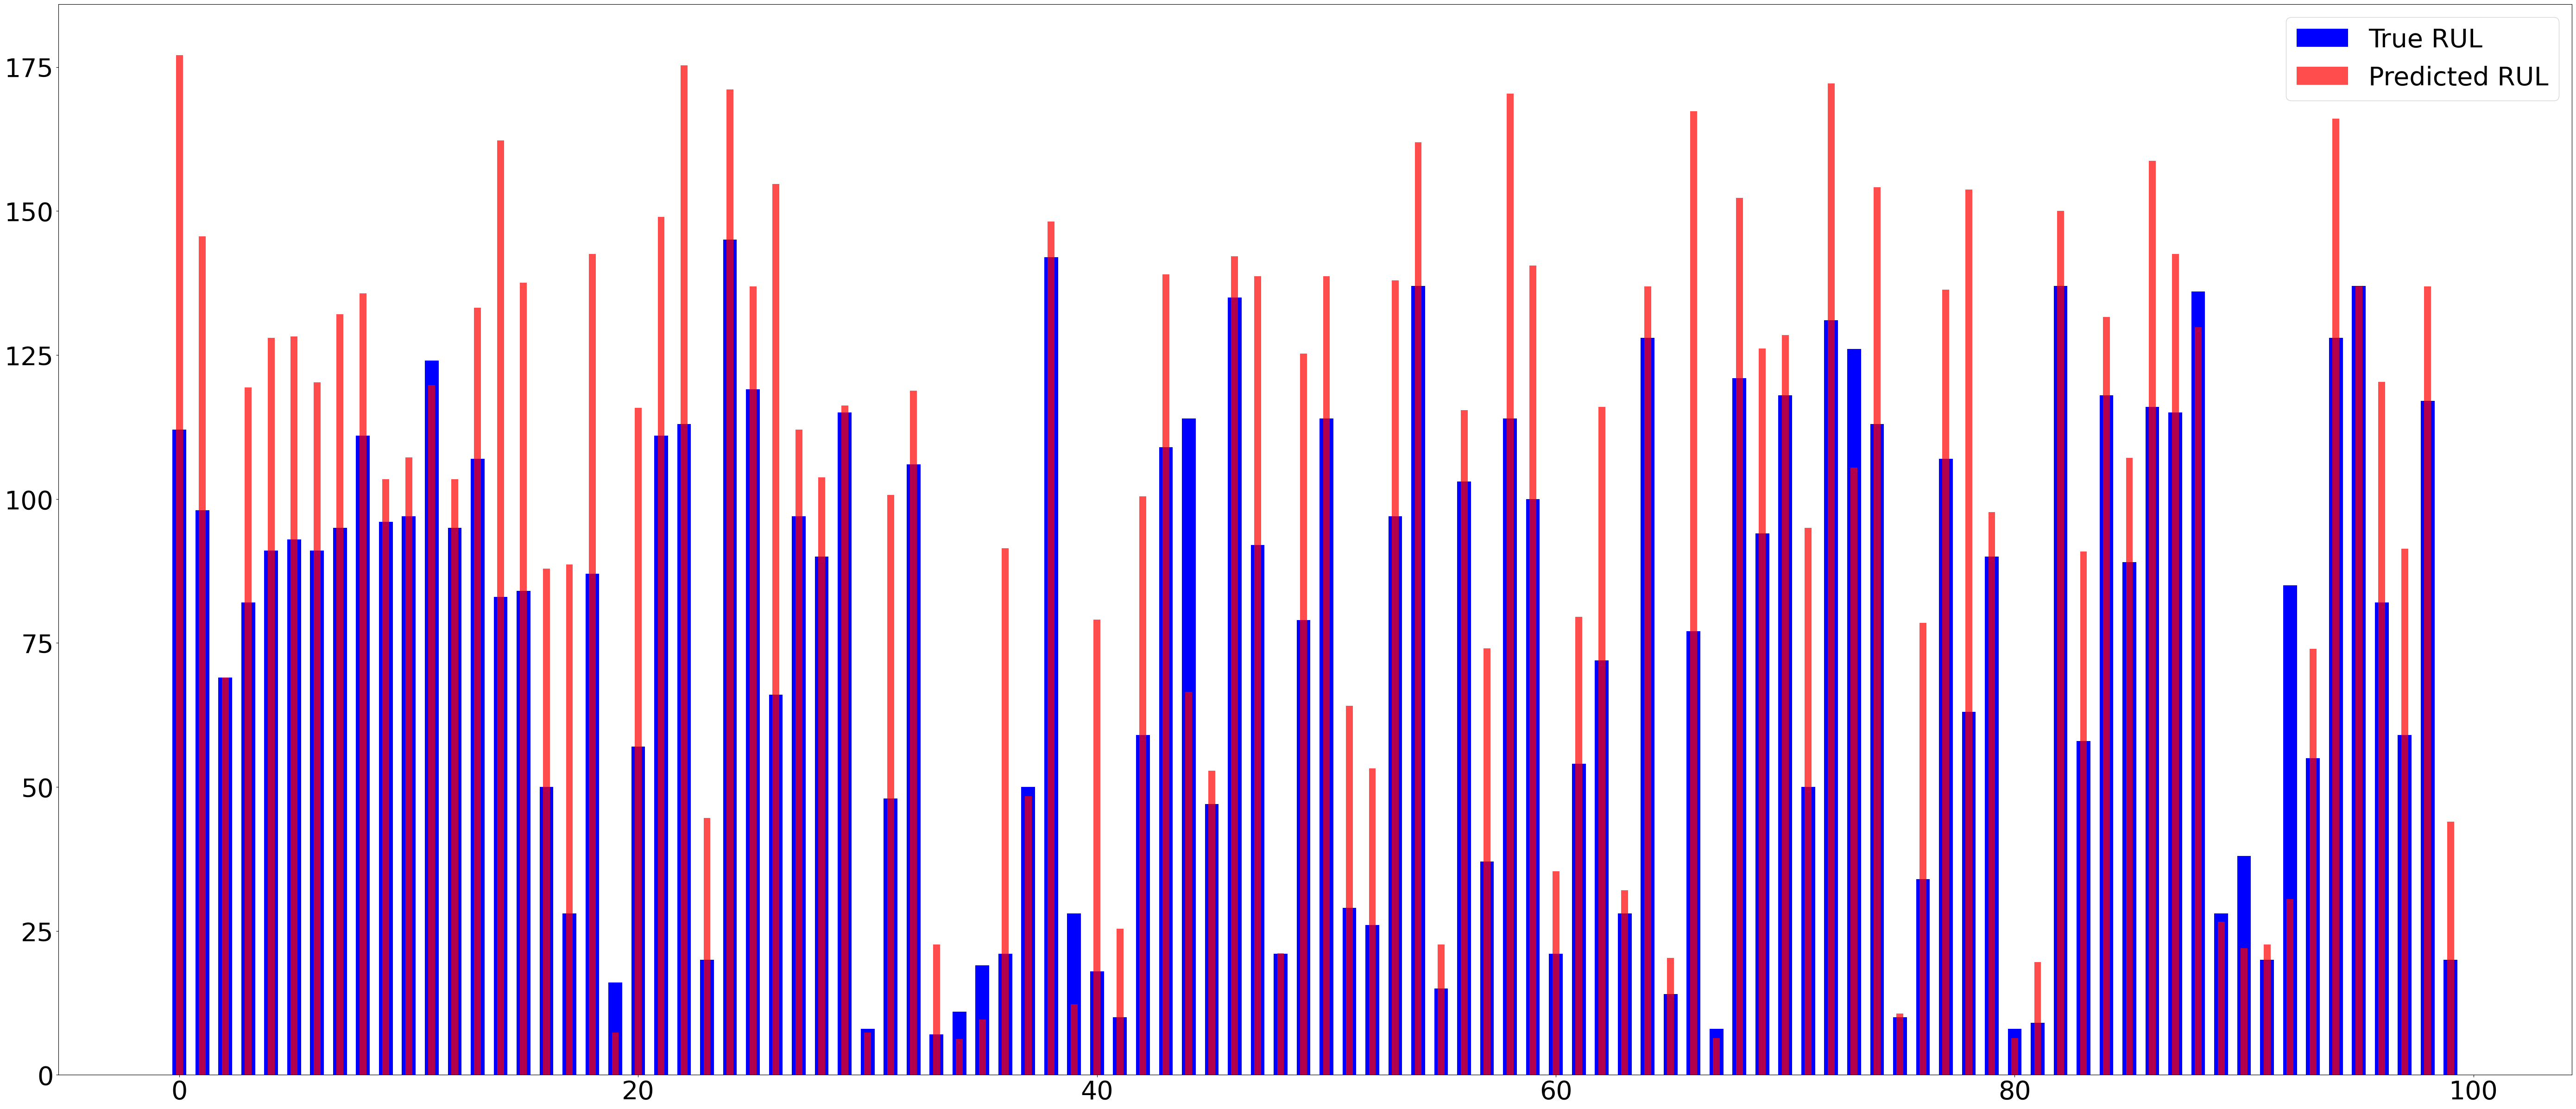

In [53]:
# --- Comparison Plots (Rolling Mean) ---
plot_predActual(y_valid, y_lr_valid)
plot_predActual(y_valid, y_svr_valid)
plot_predActual(y_valid, y_rf_valid)
plot_predActual(y_valid, y_xgb_valid)

## 13. Consolidated Model Comparison - All Three Phases (Phase 1, 2 & 3)

All model–feature combinations across the three phases are evaluated uniformly on the same train / internal-test / validation splits and assembled into a single comparison table. Cells highlighted in **green** indicate the lowest validation RMSE and highest validation R² — identifying the best-performing model overall.

In [54]:
# ===================== COMPARISON TABLE =====================
results = []

def get_metrics(y_true, y_pred):
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    r2 = r2_score(y_true, y_pred)
    return round(rmse, 4), round(r2, 4)

# ---------- Phase 1: All Sensors (no clipping) ----------
scaler1 = MinMaxScaler()
X_train_s1 = scaler1.fit_transform(X_train)
X_test_s1 = scaler1.transform(X_test)
X_valid_s1 = scaler1.transform(X_valid)

# Linear Regression
lr1 = Linear_Regression()
lr1.fit(X=X_train_s1, Y=y_train)
rmse_train, r2_train = get_metrics(y_train, lr1.predict(X_train_s1))
rmse_test, r2_test = get_metrics(y_test, lr1.predict(X_test_s1))
rmse_val, r2_val = get_metrics(y_valid, lr1.predict(X_valid_s1))
results.append(['Linear Regression', 'All Sensors', rmse_train, r2_train, rmse_test, r2_test, rmse_val, r2_val])

# SVR
svr1 = SVR(kernel='rbf')
svr1.fit(X_train_s1, y_train)
rmse_train, r2_train = get_metrics(y_train, svr1.predict(X_train_s1))
rmse_test, r2_test = get_metrics(y_test, svr1.predict(X_test_s1))
rmse_val, r2_val = get_metrics(y_valid, svr1.predict(X_valid_s1))
results.append(['SVR', 'All Sensors', rmse_train, r2_train, rmse_test, r2_test, rmse_val, r2_val])

# Random Forest
rf1 = RandomForestRegressor(max_features="sqrt", random_state=42)
rf1.fit(X_train_s1, y_train)
rmse_train, r2_train = get_metrics(y_train, rf1.predict(X_train_s1))
rmse_test, r2_test = get_metrics(y_test, rf1.predict(X_test_s1))
rmse_val, r2_val = get_metrics(y_valid, rf1.predict(X_valid_s1))
results.append(['Random Forest', 'All Sensors', rmse_train, r2_train, rmse_test, r2_test, rmse_val, r2_val])

# ---------- Phase 2: Dropped Sensors + Clipped RUL ----------
scaler2 = MinMaxScaler()
X_train_s2 = scaler2.fit_transform(X_train_2)
X_test_s2 = scaler2.transform(X_test_2)
X_valid_s2 = scaler2.transform(X_valid_2)

# Linear Regression
lr2 = Linear_Regression()
lr2.fit(X=X_train_s2, Y=y_train_clip)
rmse_train, r2_train = get_metrics(y_train_clip, lr2.predict(X_train_s2))
rmse_test, r2_test = get_metrics(y_test, lr2.predict(X_test_s2))
rmse_val, r2_val = get_metrics(y_valid, lr2.predict(X_valid_s2))
results.append(['Linear Regression', 'Dropped + Clipped', rmse_train, r2_train, rmse_test, r2_test, rmse_val, r2_val])

# SVR
svr2 = SVR(kernel='rbf')
svr2.fit(X_train_s2, y_train)
rmse_train, r2_train = get_metrics(y_train_clip, svr2.predict(X_train_s2))
rmse_test, r2_test = get_metrics(y_test, svr2.predict(X_test_s2))
rmse_val, r2_val = get_metrics(y_valid, svr2.predict(X_valid_s2))
results.append(['SVR', 'Dropped + Clipped', rmse_train, r2_train, rmse_test, r2_test, rmse_val, r2_val])

# Random Forest
rf2 = RandomForestRegressor(max_features=0.3, random_state=42, max_depth=5, min_samples_leaf=50, min_samples_split=100, n_estimators=200, max_samples=0.7)
rf2.fit(X_train_s2, y_train_clip)
rmse_train, r2_train = get_metrics(y_train_clip, rf2.predict(X_train_s2))
rmse_test, r2_test = get_metrics(y_test, rf2.predict(X_test_s2))
rmse_val, r2_val = get_metrics(y_valid, rf2.predict(X_valid_s2))
results.append(['Random Forest', 'Dropped + Clipped', rmse_train, r2_train, rmse_test, r2_test, rmse_val, r2_val])

# XGBoost
xgb2 = xgboost.XGBRegressor(n_estimators=200, learning_rate=0.02, gamma=3, subsample=0.6, colsample_bytree=0.4, max_depth=2, reg_alpha=1, reg_lambda=5, min_child_weight=15)
xgb2.fit(X_train_s2, y_train_clip)
rmse_train, r2_train = get_metrics(y_train_clip, xgb2.predict(X_train_s2))
rmse_test, r2_test = get_metrics(y_test, xgb2.predict(X_test_s2))
rmse_val, r2_val = get_metrics(y_valid, xgb2.predict(X_valid_s2))
results.append(['XGBoost', 'Dropped + Clipped', rmse_train, r2_train, rmse_test, r2_test, rmse_val, r2_val])

# ---------- Phase 3: Rolling Mean ----------
scaler3 = MinMaxScaler()
X_train_s3 = scaler3.fit_transform(X_train_tm)
X_test_s3 = scaler3.transform(X_test_tm)
X_valid_s3 = scaler3.transform(X_valid3)

# Linear Regression
lr3 = Linear_Regression()
lr3.fit(X=X_train_s3, Y=y_train_tm)
rmse_train, r2_train = get_metrics(y_train_tm, lr3.predict(X_train_s3))
rmse_test, r2_test = get_metrics(y_test_tm, lr3.predict(X_test_s3))
rmse_val, r2_val = get_metrics(y_valid, lr3.predict(X_valid_s3))
results.append(['Linear Regression', 'Rolling Mean', rmse_train, r2_train, rmse_test, r2_test, rmse_val, r2_val])

# SVR
svr3 = SVR(kernel='rbf')
svr3.fit(X_train_s3, y_train_tm)
rmse_train, r2_train = get_metrics(y_train_tm, svr3.predict(X_train_s3))
rmse_test, r2_test = get_metrics(y_test_tm, svr3.predict(X_test_s3))
rmse_val, r2_val = get_metrics(y_valid, svr3.predict(X_valid_s3))
results.append(['SVR', 'Rolling Mean', rmse_train, r2_train, rmse_test, r2_test, rmse_val, r2_val])

# Random Forest
rf3 = RandomForestRegressor(max_features=0.3, random_state=42, max_depth=5, min_samples_leaf=50, min_samples_split=100, n_estimators=200, max_samples=0.7)
rf3.fit(X_train_s3, y_train_tm)
rmse_train, r2_train = get_metrics(y_train_tm, rf3.predict(X_train_s3))
rmse_test, r2_test = get_metrics(y_test_tm, rf3.predict(X_test_s3))
rmse_val, r2_val = get_metrics(y_valid, rf3.predict(X_valid_s3))
results.append(['Random Forest', 'Rolling Mean', rmse_train, r2_train, rmse_test, r2_test, rmse_val, r2_val])

# XGBoost
xgb3 = xgboost.XGBRegressor(n_estimators=200, learning_rate=0.02, gamma=3, subsample=0.6, colsample_bytree=0.4, max_depth=2, reg_alpha=1, reg_lambda=5, min_child_weight=15)
xgb3.fit(X_train_s3, y_train_tm)
rmse_train, r2_train = get_metrics(y_train_tm, xgb3.predict(X_train_s3))
rmse_test, r2_test = get_metrics(y_test_tm, xgb3.predict(X_test_s3))
rmse_val, r2_val = get_metrics(y_valid, xgb3.predict(X_valid_s3))
results.append(['XGBoost', 'Rolling Mean', rmse_train, r2_train, rmse_test, r2_test, rmse_val, r2_val])

# ---------- Build Comparison Table ----------
comparison = pd.DataFrame(results, columns=[
    'Model', 'Feature Set', 
    'Train RMSE', 'Train R²', 
    'Test RMSE', 'Test R²', 
    'Validation RMSE', 'Validation R²'
])

comparison.style.highlight_min(subset=['Validation RMSE'], color='lightgreen') \
               .highlight_max(subset=['Validation R²'], color='lightgreen')

,Model,Feature Set,Train RMSE,Train R²,Test RMSE,Test R²,Validation RMSE,Validation R²
0,Linear Regression,All Sensors,56.198700,0.343900,55.060200,0.338100,38.477800,0.142600
1,SVR,All Sensors,43.564500,0.605800,43.253300,0.591600,26.218900,0.601900
2,Random Forest,All Sensors,15.408300,0.950700,41.294400,0.627700,33.227800,0.360600
3,Linear Regression,Dropped + Clipped,47.863100,0.379300,56.314200,0.307600,36.821400,0.214900
4,SVR,Dropped + Clipped,32.915400,0.706400,42.261900,0.610100,26.553100,0.591700
5,Random Forest,Dropped + Clipped,33.261100,0.700200,43.306500,0.590500,26.506800,0.593100
6,XGBoost,Dropped + Clipped,33.256200,0.700300,42.996200,0.596400,27.035000,0.576800
7,Linear Regression,Rolling Mean,40.529100,0.554500,40.499300,0.545600,30.982400,0.444100
8,SVR,Rolling Mean,32.484500,0.713800,32.764200,0.702600,27.675800,0.556500
9,Random Forest,Rolling Mean,31.347000,0.733500,32.050400,0.715400,28.250200,0.537800


## 15. Phase 4: Sensor Clustering and Risk-Aware Evaluation

**Goal:** Use hierarchical agglomerative clustering on sensor-RUL correlation profiles to identify **representative sensors** (one per cluster), reducing the feature set to the most informative and non-redundant signals. Scatter plots of all sensors vs RUL are shown to visually validate the clustering results.

All four classical models are re-trained on this minimal representative feature set and evaluated with **risk-aware metrics** beyond standard RMSE/R2:

| Metric | Meaning |
|--------|---------|
| Overprediction rate | Fraction of engines where RUL is overestimated (dangerous in safety-critical maintenance) |
| MAE (over / under) | Mean absolute error computed separately for over- and under-predictions |
| Asymmetric CMAPSS score | Standard benchmark scoring function: overprediction penalised more steeply than underprediction |

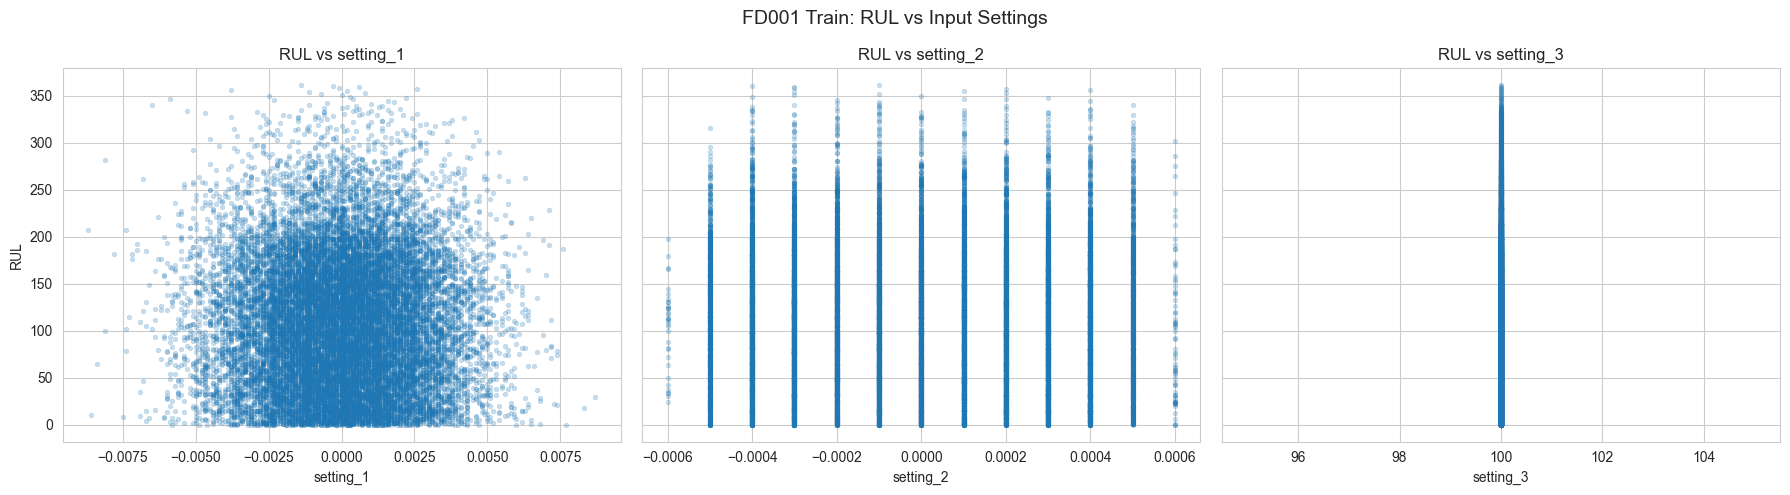

In [55]:
# ---- Scatter plots: RUL vs input settings (FD001 train) ----
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# Reuse existing train dataframe when available; otherwise build it quickly.
if 'train' not in globals():
    index_names = ['unit_number', 'time_cycles']
    setting_names = ['setting_1', 'setting_2', 'setting_3']
    sensor_names = [f's_{i+1}' for i in range(21)]
    col_names = index_names + setting_names + sensor_names

    train = pd.read_csv(
        'data/CMaps/train_FD001.txt',
        sep='\s+',
        header=None,
        names=col_names
    )

    max_cycle = train.groupby('unit_number')['time_cycles'].max().reset_index()
    max_cycle.columns = ['unit_number', 'max_time_cycle']
    train = train.merge(max_cycle, on='unit_number', how='left')
    train['RUL'] = train['max_time_cycle'] - train['time_cycles']
    train.drop(columns=['max_time_cycle'], inplace=True)

setting_cols = ['setting_1', 'setting_2', 'setting_3']
plot_df = train[setting_cols + ['RUL']].copy()

sns.set_style('whitegrid')
fig, axes = plt.subplots(1, 3, figsize=(18, 5), sharey=True)

for i, col in enumerate(setting_cols):
    sns.scatterplot(
        data=plot_df,
        x=col,
        y='RUL',
        alpha=0.25,
        s=12,
        edgecolor=None,
        ax=axes[i]
    )
    axes[i].set_title(f'RUL vs {col}')
    axes[i].set_xlabel(col)

axes[0].set_ylabel('RUL')
fig.suptitle('FD001 Train: RUL vs Input Settings', fontsize=14)
plt.tight_layout()
plt.show()

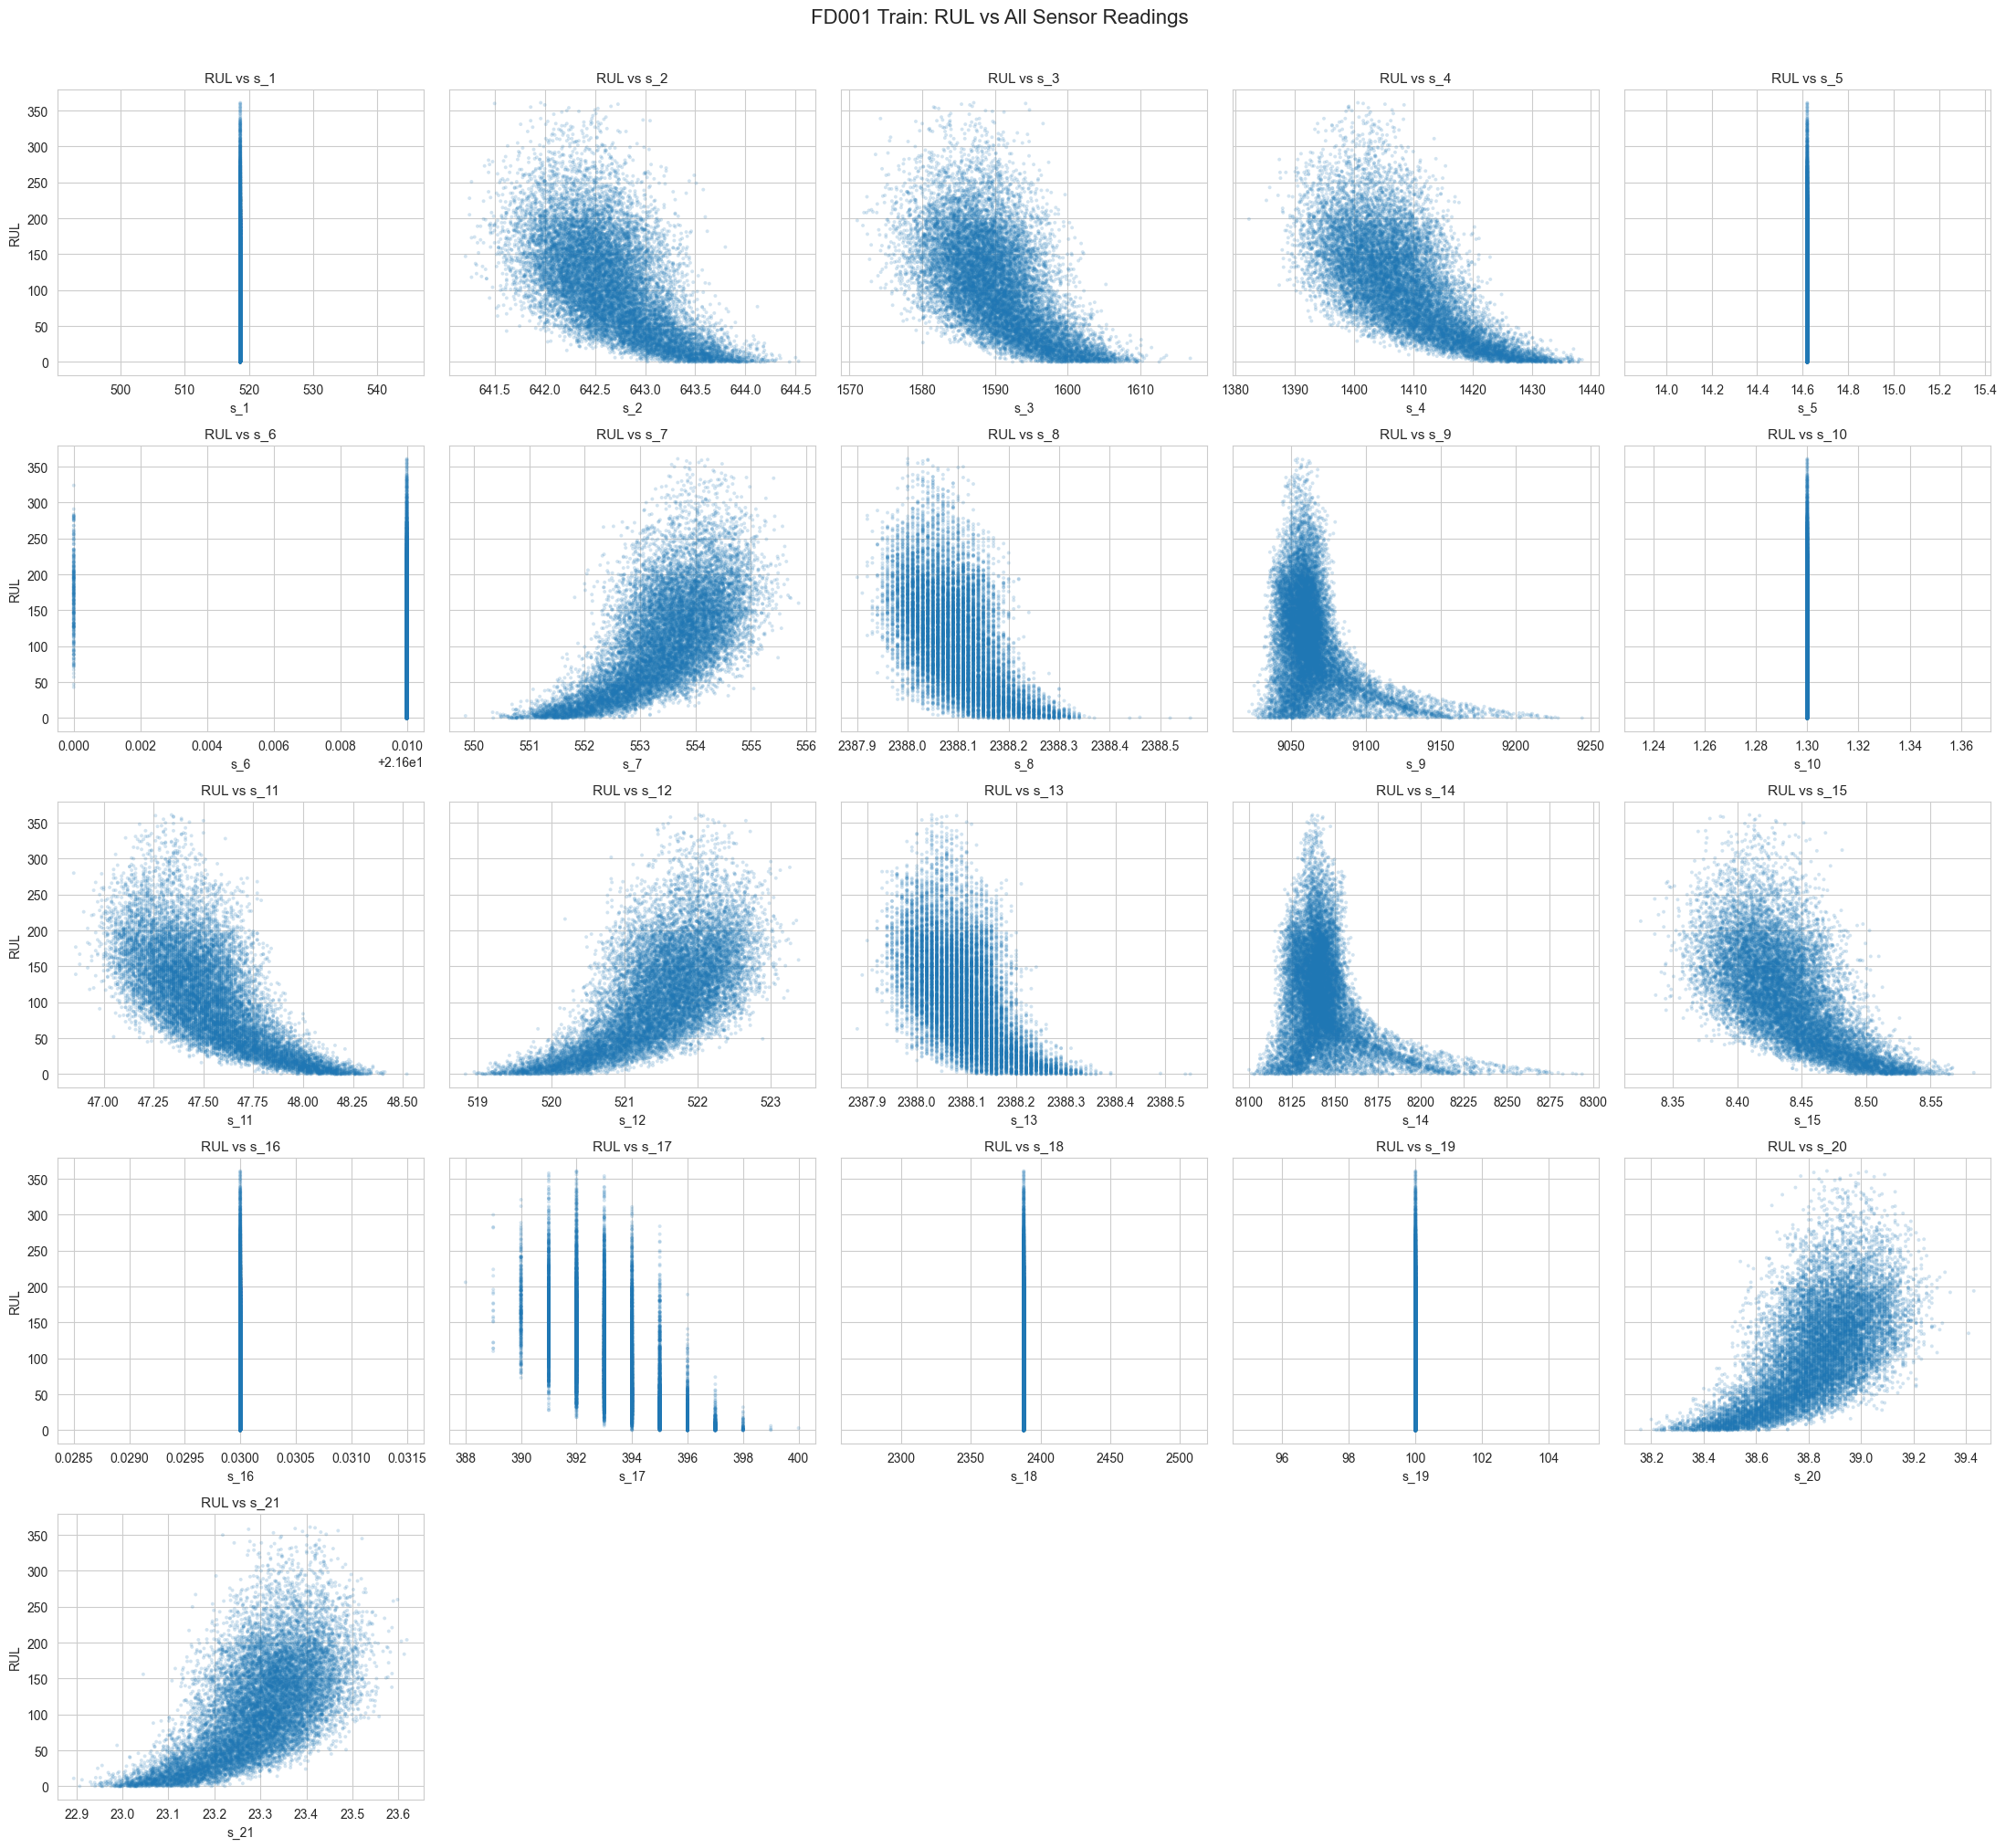

In [56]:
# ---- Scatter plots: RUL vs all sensor readings (FD001 train) ----
import numpy as np
import matplotlib.pyplot as plt

# Ensure train + sensor names exist
if 'train' not in globals():
    index_names = ['unit_number', 'time_cycles']
    setting_names = ['setting_1', 'setting_2', 'setting_3']
    sensor_names = [f's_{i+1}' for i in range(21)]
    col_names = index_names + setting_names + sensor_names

    train = pd.read_csv(
        'data/CMaps/train_FD001.txt',
        sep='\s+',
        header=None,
        names=col_names
    )

    max_cycle = train.groupby('unit_number')['time_cycles'].max().reset_index()
    max_cycle.columns = ['unit_number', 'max_time_cycle']
    train = train.merge(max_cycle, on='unit_number', how='left')
    train['RUL'] = train['max_time_cycle'] - train['time_cycles']
    train.drop(columns=['max_time_cycle'], inplace=True)

if 'sensor_names' not in globals():
    sensor_names = [f's_{i+1}' for i in range(21)]

# Optional sampling for readability and faster plotting
plot_df = train[['RUL'] + sensor_names].copy()
max_points = 15000
if len(plot_df) > max_points:
    plot_df = plot_df.sample(n=max_points, random_state=42)

n_sensors = len(sensor_names)
n_cols = 5
n_rows = int(np.ceil(n_sensors / n_cols))

fig, axes = plt.subplots(n_rows, n_cols, figsize=(22, 4 * n_rows), sharey=True)
axes = axes.flatten()

for idx, sensor in enumerate(sensor_names):
    axes[idx].scatter(
        plot_df[sensor],
        plot_df['RUL'],
        s=8,
        alpha=0.20,
        c='#1f77b4',
        edgecolors='none'
    )
    axes[idx].set_title(f'RUL vs {sensor}', fontsize=11)
    axes[idx].set_xlabel(sensor)
    if idx % n_cols == 0:
        axes[idx].set_ylabel('RUL')

# Hide any empty subplot slots
for j in range(n_sensors, len(axes)):
    axes[j].axis('off')

fig.suptitle('FD001 Train: RUL vs All Sensor Readings', fontsize=16, y=1.01)
plt.tight_layout()
plt.show()

Near-constant sensors (excluded from clustering): ['s_1', 's_5', 's_10', 's_16', 's_18', 's_19']
Sensors used for clustering: 15

Cluster assignment (first rows):
   sensor  cluster
0    s_14        1
1     s_9        1
2    s_11        2
3    s_12        2
4    s_13        2
5    s_15        2
6    s_17        2
7     s_2        2
8    s_20        2
9    s_21        2
10    s_4        2
11    s_7        2
12    s_8        2
13    s_3        3
14    s_6        4

Number of clusters: 4
Selected representative sensors: ['s_9', 's_11', 's_3', 's_6']

Representative sensors table:


,cluster,representative_sensor,abs_corr_with_RUL,cluster_size
0,1,s_9,0.390102,2
1,2,s_11,0.696228,11
2,3,s_3,0.584520,1
3,4,s_6,0.128348,1


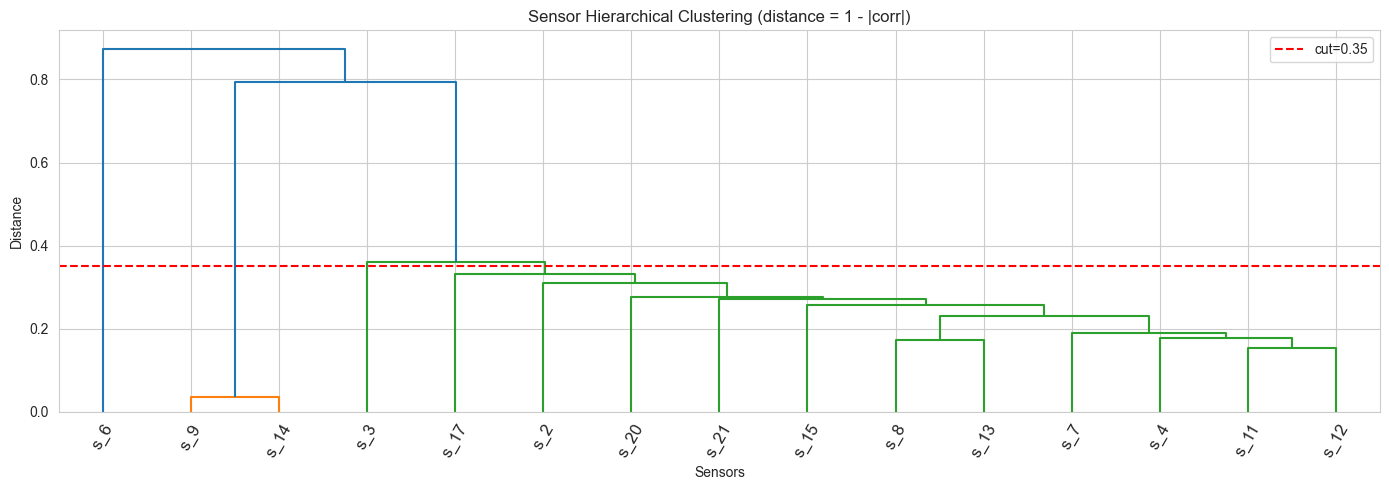

In [57]:
# ---- Sensor clustering to identify representative sensors ----
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.cluster.hierarchy import linkage, fcluster, dendrogram
from scipy.spatial.distance import squareform

# Ensure sensor list exists
if 'sensor_names' not in globals():
    sensor_names = [f's_{i+1}' for i in range(21)]

sensor_df = train[sensor_names].copy()

# 1) Remove near-constant sensors before clustering
stds = sensor_df.std()
constant_sensors = stds[stds < 1e-8].index.tolist()
active_sensors = [s for s in sensor_names if s not in constant_sensors]

print('Near-constant sensors (excluded from clustering):', constant_sensors)
print('Sensors used for clustering:', len(active_sensors))

# 2) Build distance matrix using absolute correlation
corr = sensor_df[active_sensors].corr()
distance = 1 - np.abs(corr)
np.fill_diagonal(distance.values, 0.0)

# 3) Hierarchical clustering
condensed_dist = squareform(distance.values, checks=False)
Z = linkage(condensed_dist, method='average')

# Choose a cut threshold on correlation distance
# (distance = 1 - |corr|, so 0.35 means |corr| >= 0.65 are grouped tightly)
cluster_threshold = 0.35
cluster_ids = fcluster(Z, t=cluster_threshold, criterion='distance')

cluster_map = pd.DataFrame({
    'sensor': active_sensors,
    'cluster': cluster_ids
}).sort_values(['cluster', 'sensor']).reset_index(drop=True)

# 4) Pick representative per cluster: strongest |corr(sensor, RUL)|
rul_corr = train[active_sensors + ['RUL']].corr()['RUL'].drop('RUL').abs()
representatives = []
for cluster_id, grp in cluster_map.groupby('cluster'):
    best_sensor = rul_corr[grp['sensor']].idxmax()
    representatives.append({
        'cluster': int(cluster_id),
        'representative_sensor': best_sensor,
        'abs_corr_with_RUL': float(rul_corr[best_sensor]),
        'cluster_size': int(len(grp))
    })

rep_df = pd.DataFrame(representatives).sort_values('cluster').reset_index(drop=True)
selected_sensors = rep_df['representative_sensor'].tolist()

print('\nCluster assignment (first rows):')
print(cluster_map.head(15))
print(f"\nNumber of clusters: {cluster_map['cluster'].nunique()}")
print('Selected representative sensors:', selected_sensors)

print('\nRepresentative sensors table:')
display(rep_df)

# 5) Visualize dendrogram
plt.figure(figsize=(14, 5))
dendrogram(Z, labels=active_sensors, leaf_rotation=60)
plt.axhline(y=cluster_threshold, color='red', linestyle='--', label=f'cut={cluster_threshold}')
plt.title('Sensor Hierarchical Clustering (distance = 1 - |corr|)')
plt.xlabel('Sensors')
plt.ylabel('Distance')
plt.legend()
plt.tight_layout()
plt.show()

Representative sensors used: ['s_9', 's_11', 's_3', 's_6']

Model comparison on representative sensors (sorted by validation RMSE):


,model,test_rmse,test_r2,valid_rmse,valid_r2
0,SVR,45.278171,0.552414,29.146733,0.508051
1,LinearRegression,46.234816,0.533301,34.442191,0.313055
2,RandomForest,43.860277,0.580007,35.002105,0.290539
3,XGBoost,43.868332,0.579853,35.605769,0.265856


Best model selected: SVR (validation RMSE = 29.1467)

Risk-aware metrics on validation (best model):
rmse: 29.146733
r2: 0.508051
mae: 21.743992
over_rate: 0.760000
under_rate: 0.240000
mae_over: 24.457584
mae_under: 13.150952
rmse_over: 31.898214
rmse_under: 17.822625
asymmetric_score: 10667.840318


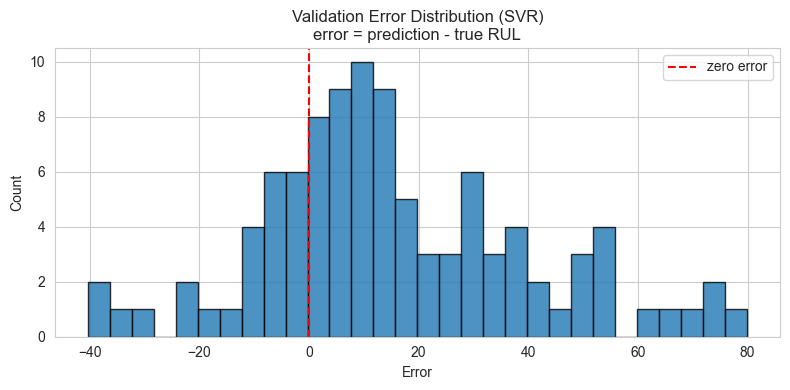

In [58]:
# ---- Train best model on representative sensors + risk-aware evaluation ----
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.svm import SVR
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LinearRegression
import xgboost as xgb
import numpy as np
import pandas as pd

# Ensure base datasets exist in the current kernel session
if 'train' not in globals() or 'valid' not in globals() or 'y_valid' not in globals():
    index_names = ['unit_number', 'time_cycles']
    setting_names = ['setting_1', 'setting_2', 'setting_3']
    sensor_names = [f's_{i+1}' for i in range(21)]
    col_names = index_names + setting_names + sensor_names

    dftrain = pd.read_csv('data/CMaps/train_FD001.txt', sep='\s+', header=None, names=col_names)
    valid = pd.read_csv('data/CMaps/test_FD001.txt', sep='\s+', header=None, names=col_names)
    y_valid = pd.read_csv('data/CMaps/RUL_FD001.txt', sep='\s+', header=None, names=['RUL'])

    train = dftrain.copy()
    max_cycle = train.groupby('unit_number')['time_cycles'].max().reset_index()
    max_cycle.columns = ['unit_number', 'max_time_cycle']
    train = train.merge(max_cycle, on='unit_number', how='left')
    train['RUL'] = train['max_time_cycle'] - train['time_cycles']
    train.drop(columns=['max_time_cycle'], inplace=True)

# Use selected sensors from clustering cell; fallback if not in memory
if 'selected_sensors' not in globals():
    selected_sensors = ['s_9', 's_11', 's_3', 's_6']

print('Representative sensors used:', selected_sensors)

# Build train/validation feature matrices
X_all = train[selected_sensors].copy()
y_all = train['RUL'].copy()
X_valid_rep = valid.groupby('unit_number').last().reset_index()[selected_sensors].copy()
y_valid_rep = y_valid['RUL'].values

# Split internal train/test (same style as your current notebook)
X_tr, X_te, y_tr, y_te = train_test_split(X_all, y_all, test_size=0.30, random_state=42)

# Scale features
scaler_rep = MinMaxScaler()
X_tr_s = scaler_rep.fit_transform(X_tr)
X_te_s = scaler_rep.transform(X_te)
X_valid_rep_s = scaler_rep.transform(X_valid_rep)

# Candidate models from your existing family
models = {
    'LinearRegression': LinearRegression(),
    'SVR': SVR(kernel='rbf'),
    'RandomForest': RandomForestRegressor(
        random_state=42,
        n_estimators=300,
        max_depth=8,
        min_samples_leaf=20,
        min_samples_split=40,
        max_features='sqrt'
    ),
    'XGBoost': xgb.XGBRegressor(
        random_state=42,
        n_estimators=300,
        learning_rate=0.03,
        max_depth=3,
        subsample=0.8,
        colsample_bytree=0.8,
        reg_alpha=0.2,
        reg_lambda=2.0,
        objective='reg:squarederror'
    )
}

# Train all models and compare
rows = []
best_name = None
best_model = None
best_rmse = np.inf

for name, model in models.items():
    model.fit(X_tr_s, y_tr)

    pred_te = model.predict(X_te_s)
    pred_val = model.predict(X_valid_rep_s)

    rmse_te = np.sqrt(mean_squared_error(y_te, pred_te))
    r2_te = r2_score(y_te, pred_te)

    rmse_val = np.sqrt(mean_squared_error(y_valid_rep, pred_val))
    r2_val = r2_score(y_valid_rep, pred_val)

    rows.append({
        'model': name,
        'test_rmse': rmse_te,
        'test_r2': r2_te,
        'valid_rmse': rmse_val,
        'valid_r2': r2_val
    })

    if rmse_val < best_rmse:
        best_rmse = rmse_val
        best_name = name
        best_model = model

comparison_rep = pd.DataFrame(rows).sort_values('valid_rmse').reset_index(drop=True)
print('\nModel comparison on representative sensors (sorted by validation RMSE):')
display(comparison_rep)

print(f"Best model selected: {best_name} (validation RMSE = {best_rmse:.4f})")

# Risk-aware metrics for best model on validation
best_pred_valid = best_model.predict(X_valid_rep_s)
err = best_pred_valid - y_valid_rep  # positive -> overprediction

over = err[err > 0]
under = err[err < 0]

risk_metrics = {
    'rmse': float(np.sqrt(mean_squared_error(y_valid_rep, best_pred_valid))),
    'r2': float(r2_score(y_valid_rep, best_pred_valid)),
    'mae': float(np.mean(np.abs(err))),
    'over_rate': float(np.mean(err > 0)),
    'under_rate': float(np.mean(err < 0)),
    'mae_over': float(np.mean(over)) if len(over) else 0.0,
    'mae_under': float(np.mean(np.abs(under))) if len(under) else 0.0,
    'rmse_over': float(np.sqrt(np.mean(over**2))) if len(over) else 0.0,
    'rmse_under': float(np.sqrt(np.mean(under**2))) if len(under) else 0.0,
    # C-MAPSS style asymmetric score: overprediction penalized more sharply
    'asymmetric_score': float(np.sum(np.where(err < 0, np.exp(-err / 13) - 1, np.exp(err / 10) - 1)))
}

print('\nRisk-aware metrics on validation (best model):')
for k, v in risk_metrics.items():
    print(f'{k}: {v:.6f}')

# Quick visual: where errors fall around zero
plt.figure(figsize=(8, 4))
plt.hist(err, bins=30, alpha=0.8, edgecolor='black')
plt.axvline(0, color='red', linestyle='--', label='zero error')
plt.title(f'Validation Error Distribution ({best_name})\nerror = prediction - true RUL')
plt.xlabel('Error')
plt.ylabel('Count')
plt.legend()
plt.tight_layout()
plt.show()

In [59]:
# ---- Compact summary of representative-sensor training ----
print('Best model:', best_name)
print('\nValidation leaderboard (RMSE ascending):')
print(comparison_rep[['model', 'valid_rmse', 'valid_r2']].to_string(index=False))

print('\nRisk-aware metrics (best model):')
for key in [
    'rmse', 'r2', 'mae',
    'over_rate', 'under_rate',
    'mae_over', 'mae_under',
    'rmse_over', 'rmse_under',
    'asymmetric_score'
]:
    print(f'{key}: {risk_metrics[key]:.6f}')

Best model: SVR

Validation leaderboard (RMSE ascending):
           model  valid_rmse  valid_r2
             SVR   29.146733  0.508051
LinearRegression   34.442191  0.313055
    RandomForest   35.002105  0.290539
         XGBoost   35.605769  0.265856

Risk-aware metrics (best model):
rmse: 29.146733
r2: 0.508051
mae: 21.743992
over_rate: 0.760000
under_rate: 0.240000
mae_over: 24.457584
mae_under: 13.150952
rmse_over: 31.898214
rmse_under: 17.822625
asymmetric_score: 10667.840318


## 16. Phase 5: LSTM -- Sequence-Based RUL Prediction

Unlike snapshot-based classical models, the **LSTM processes sliding windows of 30 consecutive time cycles** per engine, capturing temporal degradation dynamics that point-in-time feature models cannot.

**Architecture (two-layer stacked LSTM):**
- LSTM(64, return_sequences=True) -> Dropout(0.2) -> LSTM(32) -> Dropout(0.2) -> Dense(16, ReLU) -> Dense(1)

**Training configuration:**
- Optimizer: Adam | Loss: MSE | Batch size: 256 | Max epochs: 200
- Early stopping with patience = 20, restoring best weights
- RUL target clipped at **125 cycles** (piecewise-linear degradation assumption)
- Engine units split 80/20 for train/internal-test to prevent sequence leakage across engine units

**Reported error metrics: RMSE and R2 on train, internal test, and validation sets.**

In [60]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping
from sklearn.preprocessing import MinMaxScaler

In [61]:
# ---- Settings ----
sequence_length = 30  # lookback window
drop_sensors = ['s_1', 's_5', 's_6', 's_10', 's_16', 's_18', 's_19']
max_rul = 125  # clip RUL (piecewise linear degradation)

# ---- Prepare training data ----
train_lstm = train.copy()
train_lstm['RUL'] = train_lstm['RUL'].clip(upper=max_rul)

# Keep only useful sensor columns
sensor_cols = [c for c in sensor_names if c not in drop_sensors]

# Scale sensor features per the training set
scaler_lstm = MinMaxScaler()
train_lstm[sensor_cols] = scaler_lstm.fit_transform(train_lstm[sensor_cols])

# Build sequences for each engine unit
def build_sequences(df, seq_len, sensor_cols, label_col='RUL'):
    sequences, labels = [], []
    for uid in df['unit_number'].unique():
        unit = df[df['unit_number'] == uid]
        data = unit[sensor_cols].values
        rul = unit[label_col].values
        for i in range(len(data) - seq_len + 1):
            sequences.append(data[i:i+seq_len])
            labels.append(rul[i + seq_len - 1])
    return np.array(sequences), np.array(labels)

X_train_seq, y_train_seq = build_sequences(train_lstm, sequence_length, sensor_cols)
print(f"Training sequences: {X_train_seq.shape}, Labels: {y_train_seq.shape}")

Training sequences: (17731, 30, 14), Labels: (17731,)


In [62]:
# ---- Prepare validation/test sequences ----
# For the test set, build sequences per engine and take the LAST sequence
# (test engines are cut off at an arbitrary point; the last window predicts current RUL)

valid_lstm = valid.copy()
valid_lstm[sensor_cols] = scaler_lstm.transform(valid_lstm[sensor_cols])

def build_last_sequences(df, seq_len, sensor_cols):
    """For each engine, extract the last sequence of length seq_len."""
    sequences = []
    for uid in df['unit_number'].unique():
        unit = df[df['unit_number'] == uid]
        data = unit[sensor_cols].values
        if len(data) >= seq_len:
            sequences.append(data[-seq_len:])
        else:
            # Pad with zeros at the beginning if engine has fewer cycles than seq_len
            pad = np.zeros((seq_len - len(data), len(sensor_cols)))
            sequences.append(np.vstack([pad, data]))
    return np.array(sequences)

X_valid_seq = build_last_sequences(valid_lstm, sequence_length, sensor_cols)
print(f"Validation sequences: {X_valid_seq.shape}, Validation labels: {y_valid.shape}")

Validation sequences: (100, 30, 14), Validation labels: (100, 1)


In [63]:
# ---- Train/Val split from training data ----
from sklearn.model_selection import train_test_split

# Split engine units into train and internal-test groups
all_units = train_lstm['unit_number'].unique()
train_units, test_units = train_test_split(all_units, test_size=0.2, random_state=42)

train_sub = train_lstm[train_lstm['unit_number'].isin(train_units)]
test_sub = train_lstm[train_lstm['unit_number'].isin(test_units)]

X_tr, y_tr = build_sequences(train_sub, sequence_length, sensor_cols)
X_te, y_te = build_sequences(test_sub, sequence_length, sensor_cols)

print(f"Train split: {X_tr.shape}, Test split: {X_te.shape}")

Train split: (14241, 30, 14), Test split: (3490, 30, 14)


In [64]:
# ---- Build LSTM Model ----
n_features = X_tr.shape[2]

model = Sequential([
    LSTM(64, input_shape=(sequence_length, n_features), return_sequences=True),
    Dropout(0.2),
    LSTM(32),
    Dropout(0.2),
    Dense(16, activation='relu'),
    Dense(1)
])

model.compile(optimizer='adam', loss='mse')
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 30, 64)         │        20,224 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 30, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 32)             │        12,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 33,185 (129.63 KB)

 Trainable params: 33,185 (129.63 KB)

 Non-trainable params: 0 (0.00 B)

In [65]:
# ---- Train the LSTM ----
early_stop = EarlyStopping(monitor='val_loss', patience=20, restore_best_weights=True)

history = model.fit(
    X_tr, y_tr,
    validation_data=(X_te, y_te),
    epochs=200,
    batch_size=256,
    callbacks=[early_stop],
    verbose=1
)

Epoch 1/200
56/56 ━━━━━━━━━━━━━━━━━━━━ 5s 49ms/step - loss: 7440.7617 - val_loss: 6358.0103
Epoch 2/200
56/56 ━━━━━━━━━━━━━━━━━━━━ 2s 42ms/step - loss: 5586.2686 - val_loss: 4565.0830
Epoch 3/200
56/56 ━━━━━━━━━━━━━━━━━━━━ 3s 45ms/step - loss: 3899.9221 - val_loss: 3070.5012
Epoch 4/200
56/56 ━━━━━━━━━━━━━━━━━━━━ 3s 46ms/step - loss: 2655.4165 - val_loss: 2165.3435
Epoch 5/200
56/56 ━━━━━━━━━━━━━━━━━━━━ 3s 47ms/step - loss: 2033.4392 - val_loss: 1824.4221
Epoch 6/200
56/56 ━━━━━━━━━━━━━━━━━━━━ 3s 47ms/step - loss: 1823.7323 - val_loss: 1751.3243
Epoch 7/200
56/56 ━━━━━━━━━━━━━━━━━━━━ 3s 47ms/step - loss: 1799.7570 - val_loss: 1743.6932
Epoch 8/200
56/56 ━━━━━━━━━━━━━━━━━━━━ 3s 47ms/step - loss: 1799.5372 - val_loss: 1743.3920
Epoch 9/200
56/56 ━━━━━━━━━━━━━━━━━━━━ 3s 46ms/step - loss: 1801.4399 - val_loss: 1743.4086
Epoch 10/200
56/56 ━━━━━━━━━━━━━━━━━━━━ 2s 42ms/step - loss: 1798.8416 - val_loss: 1743.4133
Epoch 11/200
56/56 ━━━━━━━━━━━━━━━━━━━━ 2s 44ms/step - loss: 1800.4462 - val_lo

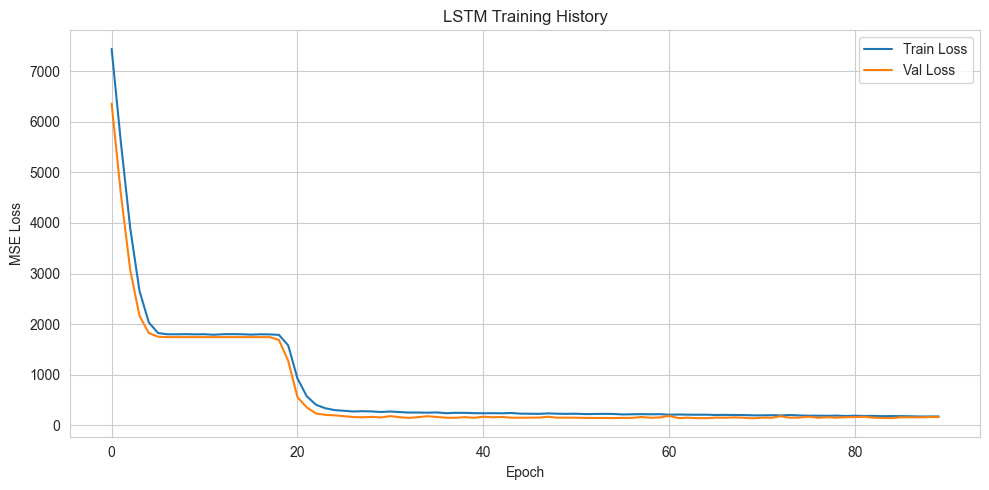

In [66]:
# ---- Training Loss Curves ----
plt.figure(figsize=(10, 5))
plt.plot(history.history['loss'], label='Train Loss')
plt.plot(history.history['val_loss'], label='Val Loss')
plt.xlabel('Epoch')
plt.ylabel('MSE Loss')
plt.title('LSTM Training History')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

In [67]:
# ---- Evaluate LSTM ----
# Train set (all sequences)
y_lstm_train = model.predict(X_train_seq).flatten()
evaluate(y_train_seq, y_lstm_train, label='train')

# Internal test set
y_lstm_test = model.predict(X_te).flatten()
evaluate(y_te, y_lstm_test, label='test')

# Validation set (FD001 test engines)
y_lstm_valid = model.predict(X_valid_seq).flatten()
evaluate(y_valid.values.flatten(), y_lstm_valid, label='valid')

555/555 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step
train set RMSE:11.58459012099627, R2:0.923191487789154
110/110 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step
test set RMSE:11.83628686571841, R2:0.9196397066116333
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step 
valid set RMSE:13.954653187415827, R2:0.8872339129447937


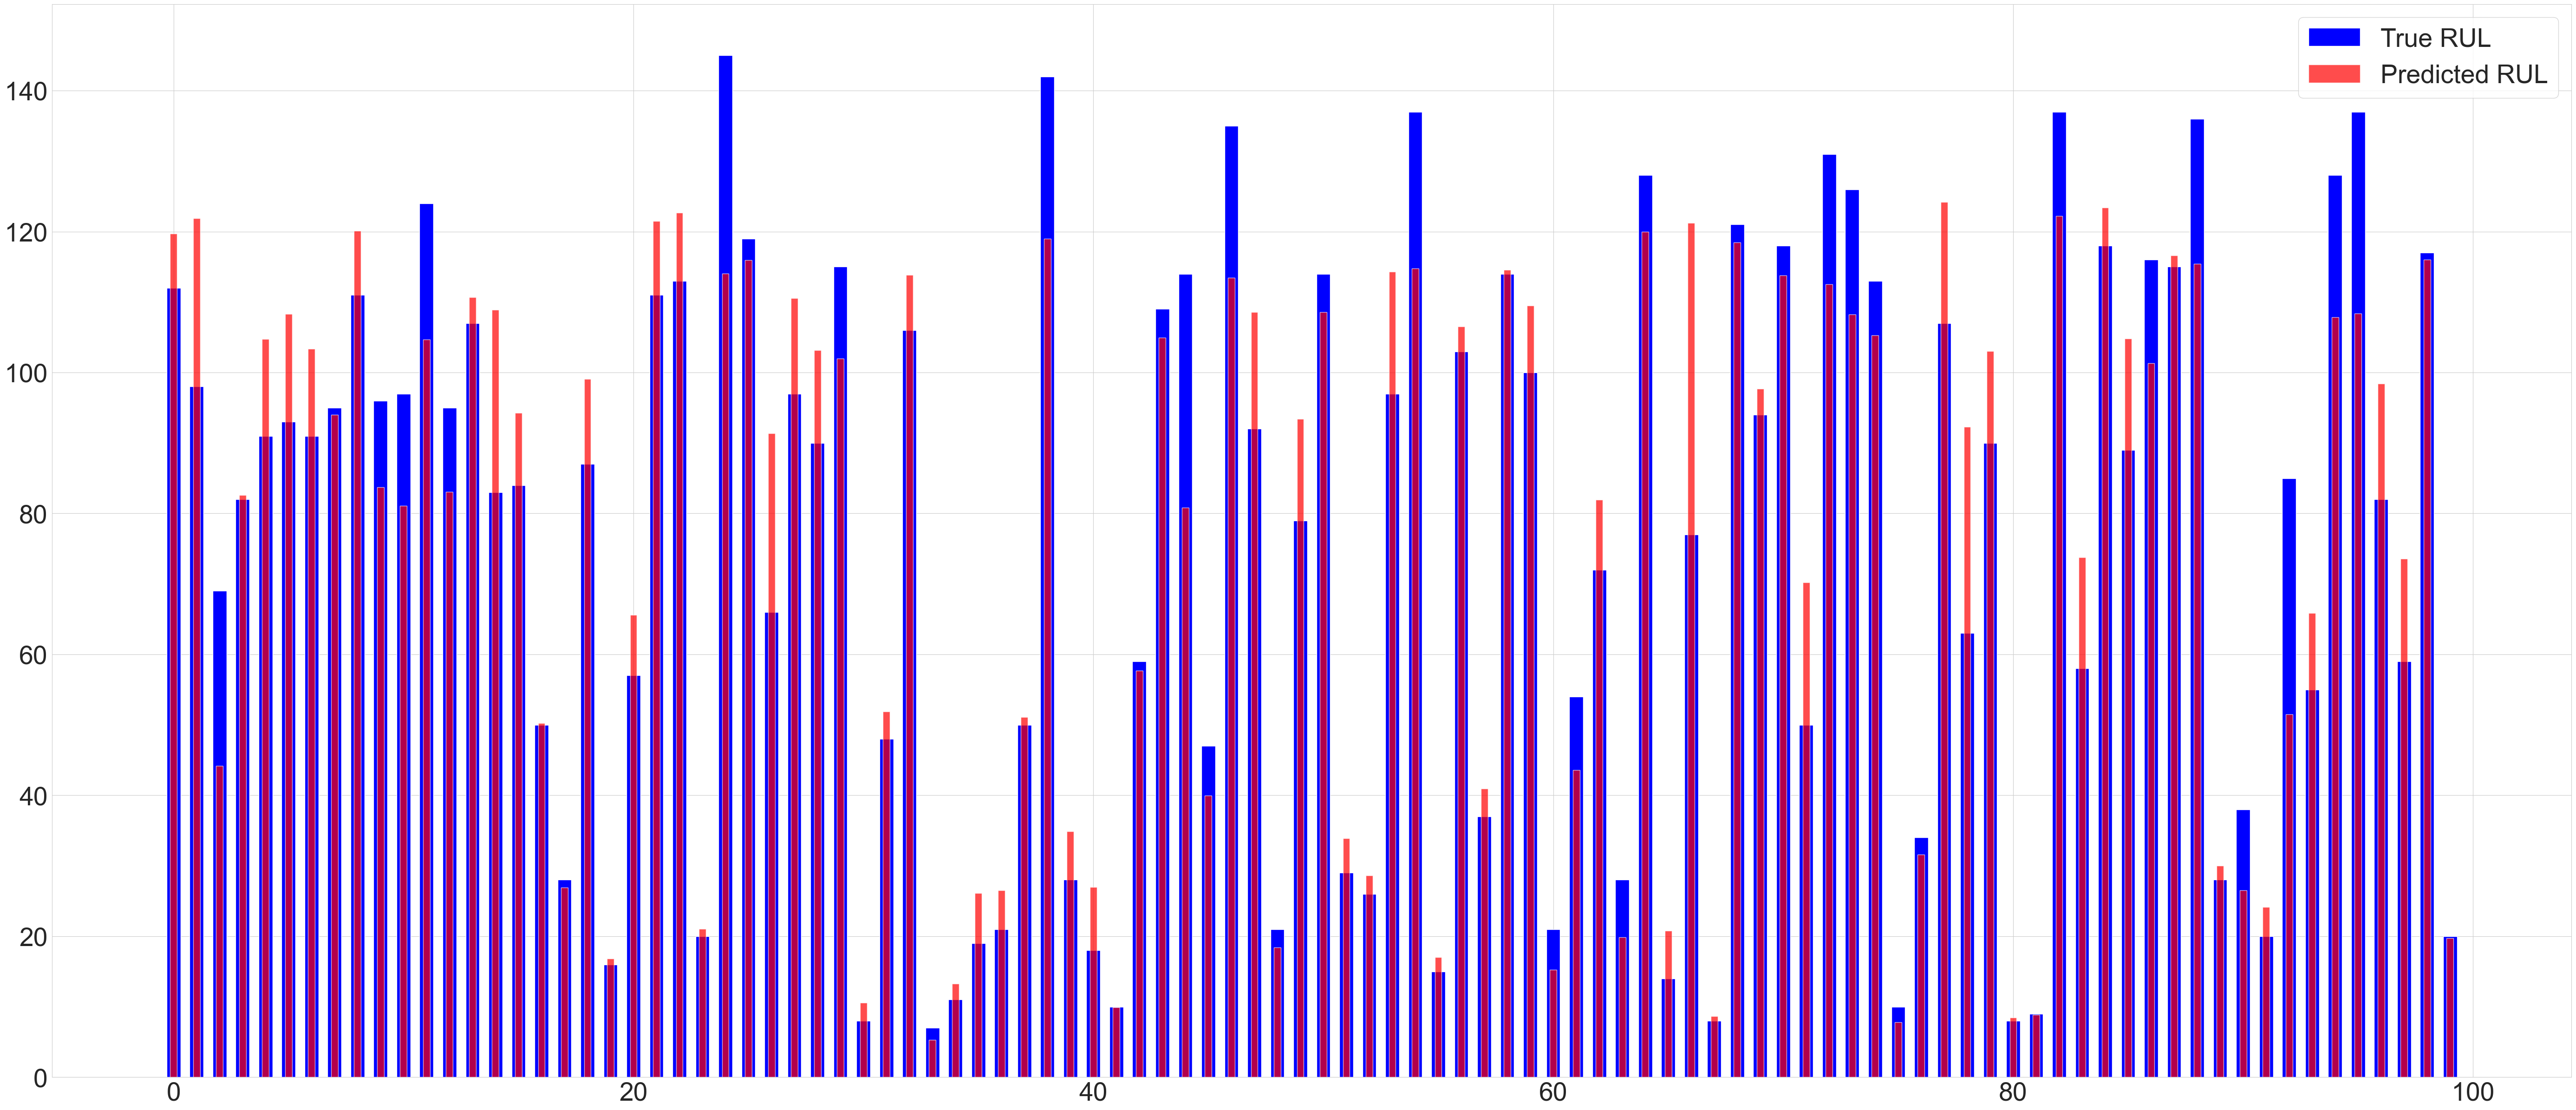

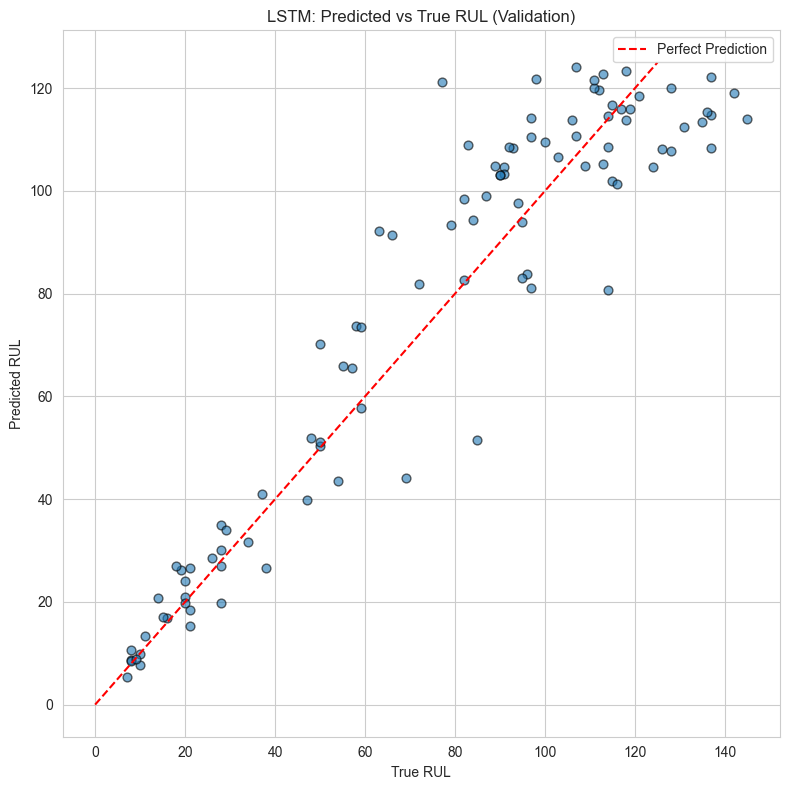

In [68]:
# ---- Predicted vs Actual RUL (Validation Set) ----
plot_predActual(y_valid, y_lstm_valid)

# Scatter plot
plt.figure(figsize=(8, 8))
plt.scatter(y_valid.values.flatten(), y_lstm_valid, alpha=0.6, edgecolors='k', s=40)
plt.plot([0, max_rul], [0, max_rul], 'r--', label='Perfect Prediction')
plt.xlabel('True RUL')
plt.ylabel('Predicted RUL')
plt.title('LSTM: Predicted vs True RUL (Validation)')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

## Cost-Sensitive LSTM (Overprediction-Penalized)

In real-life maintenance, **overpredicting** RUL is usually more dangerous than underpredicting it.
This model keeps the same LSTM structure but uses an asymmetric loss that penalizes overprediction more heavily.

In [69]:
# ---- Train a second LSTM with asymmetric loss ----
# Higher weight for overprediction error: (y_pred > y_true)
overprediction_weight = 5.0

@tf.keras.utils.register_keras_serializable()
def asymmetric_overprediction_loss(y_true, y_pred):
    error = y_pred - y_true
    sq_error = tf.square(error)
    weighted_sq_error = tf.where(error > 0.0, overprediction_weight * sq_error, sq_error)
    return tf.reduce_mean(weighted_sq_error)

n_features = X_tr.shape[2]

model_overpen = Sequential([
    LSTM(64, input_shape=(sequence_length, n_features), return_sequences=True),
    Dropout(0.2),
    LSTM(32),
    Dropout(0.2),
    Dense(16, activation='relu'),
    Dense(1)
 ])

model_overpen.compile(optimizer='adam', loss=asymmetric_overprediction_loss, metrics=['mae'])
model_overpen.summary()

early_stop_over = EarlyStopping(monitor='val_loss', patience=20, restore_best_weights=True)

history_overpen = model_overpen.fit(
    X_tr, y_tr,
    validation_data=(X_te, y_te),
    epochs=200,
    batch_size=256,
    callbacks=[early_stop_over],
    verbose=1
)

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm_2 (LSTM)                   │ (None, 30, 64)         │        20,224 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 30, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_3 (LSTM)                   │ (None, 32)             │        12,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 33,185 (129.63 KB)

 Trainable params: 33,185 (129.63 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/200
56/56 ━━━━━━━━━━━━━━━━━━━━ 5s 44ms/step - loss: 7422.6582 - mae: 75.4865 - val_loss: 6436.2666 - val_mae: 69.2356
Epoch 2/200
56/56 ━━━━━━━━━━━━━━━━━━━━ 2s 40ms/step - loss: 5772.1855 - mae: 64.8726 - val_loss: 4864.3862 - val_mae: 58.4838
Epoch 3/200
56/56 ━━━━━━━━━━━━━━━━━━━━ 2s 38ms/step - loss: 4413.7749 - mae: 54.6944 - val_loss: 3884.9495 - val_mae: 49.8164
Epoch 4/200
56/56 ━━━━━━━━━━━━━━━━━━━━ 2s 38ms/step - loss: 3808.6514 - mae: 48.1070 - val_loss: 3637.0920 - val_mae: 45.5268
Epoch 5/200
56/56 ━━━━━━━━━━━━━━━━━━━━ 2s 39ms/step - loss: 3702.3550 - mae: 45.5410 - val_loss: 3622.6699 - val_mae: 44.4552
Epoch 6/200
56/56 ━━━━━━━━━━━━━━━━━━━━ 2s 37ms/step - loss: 3696.1101 - mae: 45.0413 - val_loss: 3622.7664 - val_mae: 44.3031
Epoch 7/200
56/56 ━━━━━━━━━━━━━━━━━━━━ 2s 37ms/step - loss: 3691.6272 - mae: 44.9084 - val_loss: 3622.9194 - val_mae: 44.2540
Epoch 8/200
56/56 ━━━━━━━━━━━━━━━━━━━━ 2s 38ms/step - loss: 3703.2327 - mae: 45.0680 - val_loss: 3622.6909 - val_mae: 

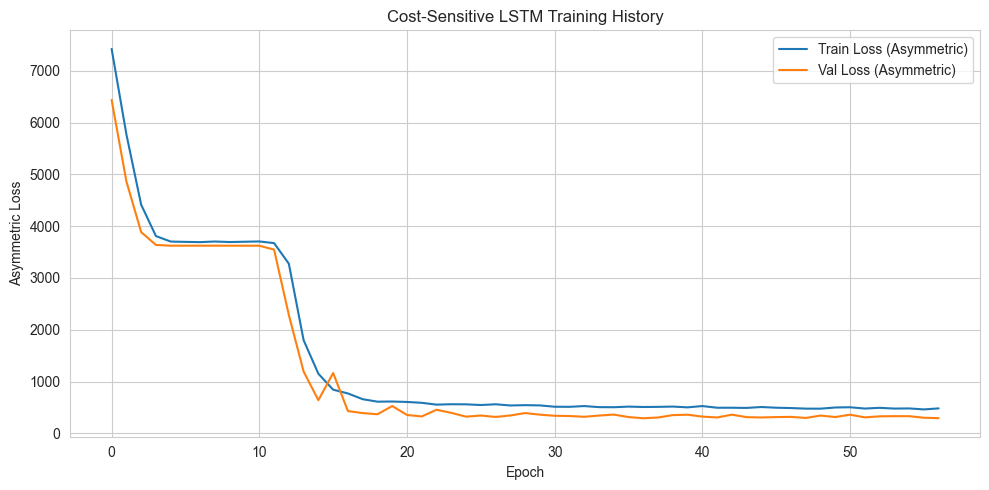

In [70]:
# ---- Training loss curves for asymmetric LSTM ----
plt.figure(figsize=(10, 5))
plt.plot(history_overpen.history['loss'], label='Train Loss (Asymmetric)')
plt.plot(history_overpen.history['val_loss'], label='Val Loss (Asymmetric)')
plt.xlabel('Epoch')
plt.ylabel('Asymmetric Loss')
plt.title('Cost-Sensitive LSTM Training History')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

555/555 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step
train_overpen set RMSE:15.681454652535626, R2:0.8592590093612671
110/110 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step
test_overpen set RMSE:14.549746712384076, R2:0.8785713315010071
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step 
valid_overpen set RMSE:16.013431633343966, R2:0.8515058755874634


,Model,RMSE,Overprediction Rate,Mean Overprediction,Mean Underprediction,Asymmetric Score
0,LSTM (MSE),13.9547,58.00%,9.8469,11.6330,318.11
1,"LSTM (Asymmetric, over_w=5.0)",16.0134,34.00%,8.4577,13.0425,340.12


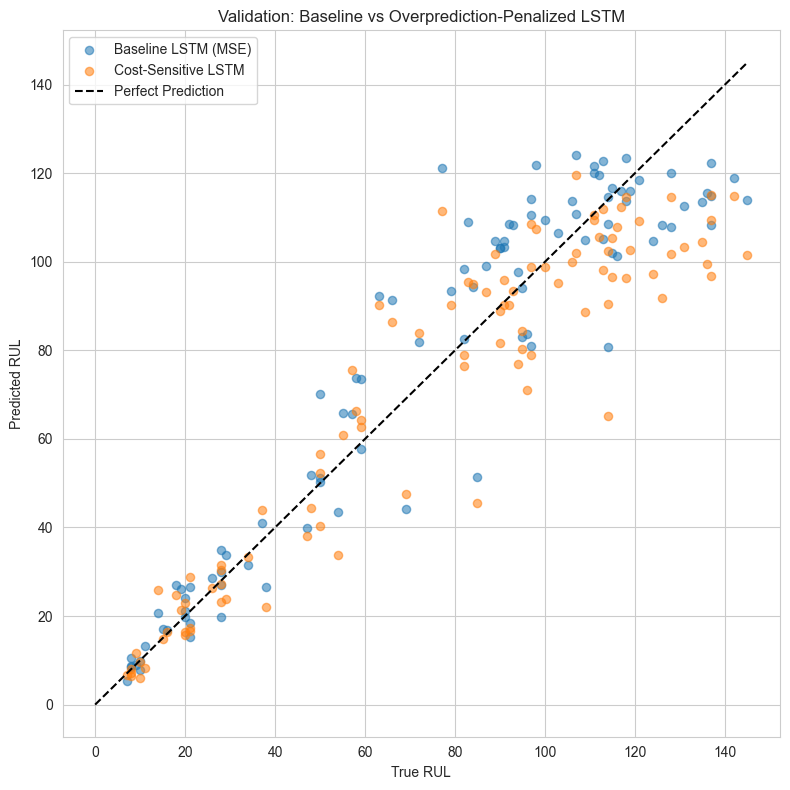

In [71]:
# ---- Evaluate and compare risk profile ----
y_true_valid = y_valid.values.flatten()

# Predictions from cost-sensitive model
y_lstm_over_train = model_overpen.predict(X_train_seq).flatten()
evaluate(y_train_seq, y_lstm_over_train, label='train_overpen')

y_lstm_over_test = model_overpen.predict(X_te).flatten()
evaluate(y_te, y_lstm_over_test, label='test_overpen')

y_lstm_over_valid = model_overpen.predict(X_valid_seq).flatten()
evaluate(y_true_valid, y_lstm_over_valid, label='valid_overpen')

# Baseline model predictions (from previous LSTM cell)
if 'y_lstm_valid' not in globals():
    y_lstm_valid = model.predict(X_valid_seq).flatten()

def risk_metrics(y_true, y_pred):
    y_true = np.asarray(y_true).flatten()
    y_pred = np.asarray(y_pred).flatten()
    err = y_pred - y_true

    over = err[err > 0]
    under = err[err < 0]

    return {
        'RMSE': float(np.sqrt(mean_squared_error(y_true, y_pred))),
        'Overprediction Rate': float(np.mean(err > 0)),
        'Mean Overprediction': float(np.mean(over)) if len(over) else 0.0,
        'Mean Underprediction': float(np.mean(np.abs(under))) if len(under) else 0.0,
        'Asymmetric Score': float(np.sum(np.where(err < 0, np.exp(-err / 13) - 1, np.exp(err / 10) - 1)))
    }

baseline_metrics = risk_metrics(y_true_valid, y_lstm_valid)
overpen_metrics = risk_metrics(y_true_valid, y_lstm_over_valid)

comparison_overpen = pd.DataFrame([
    {'Model': 'LSTM (MSE)', **baseline_metrics},
    {'Model': f'LSTM (Asymmetric, over_w={overprediction_weight})', **overpen_metrics}
])

display(comparison_overpen.style.format({
    'RMSE': '{:.4f}',
    'Overprediction Rate': '{:.2%}',
    'Mean Overprediction': '{:.4f}',
    'Mean Underprediction': '{:.4f}',
    'Asymmetric Score': '{:.2f}'
}))

# Visual comparison
plt.figure(figsize=(8, 8))
plt.scatter(y_true_valid, y_lstm_valid, alpha=0.55, s=35, label='Baseline LSTM (MSE)')
plt.scatter(y_true_valid, y_lstm_over_valid, alpha=0.55, s=35, label='Cost-Sensitive LSTM')
max_axis = max(float(np.max(y_true_valid)), float(np.max(y_lstm_valid)), float(np.max(y_lstm_over_valid)))
plt.plot([0, max_axis], [0, max_axis], 'k--', label='Perfect Prediction')
plt.xlabel('True RUL')
plt.ylabel('Predicted RUL')
plt.title('Validation: Baseline vs Overprediction-Penalized LSTM')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()